# Indus Weave Textiles -- HR Pipeline Case Study
**From six months of messy HCM exports to a warehouse the CFO can trust, and the story of why overtime keeps rising.**

One notebook, six stages, four layers: `raw` -> `staging` -> `warehouse` -> answers, with data quality checks after every load.
Every one of the 12 source files is used (11 for the core pipeline, `applications.csv` for the recruitment bonus).

## The Brief
Overtime cost has climbed for six months. HR says attendance looks normal. Payroll pays overtime from *approved OT requests*, not from biometric punches. Every module tells a slightly different story.

The job: load the exports untouched, clean and reconcile them into one model, answer 10 business questions with SQL, prove the numbers with automated checks, and give the CFO the top three findings.

| Layer | What lives there | Built by |
|---|---|---|
| `raw` | The files exactly as delivered, all text, plus `_source_file`, `_loaded_at`, `_row_hash` | Python (Stage 1) |
| `staging` | Typed, cleaned, de-duplicated tables, `attendance_daily`, rejected-row ledgers | Python + SQL (Stages 2-3) |
| `warehouse` | Star schema with enforced keys, SCD Type 2 employee dimension | SQL DDL (Stage 4) |
| answers | 10 `.sql` files and result CSVs, CFO findings | SQL (Stage 5) |

Engine: SQLite (allowed by the brief). The three layers are three attached database files named `raw`, `staging` and `warehouse`, so every query reads like PostgreSQL schemas (`raw.employees`, `staging.attendance_daily`, `warehouse.fact_payroll_line`).

## 0. Setup
Paths, the three attached schemas, and a handful of small helpers used by every stage. If the data files are not found next to the notebook (or in `./data`), the 12 files are downloaded from the course repository.

In [1]:
import hashlib
import json
import re
import shutil
import sqlite3
import urllib.request
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid")

PERIOD_START, PERIOD_END = "2026-04-01", "2026-09-30"
MONTHS = pd.period_range("2026-04", "2026-09", freq="M").astype(str).tolist()
OPEN_END = "9999-12-31"

SOURCE_FILES = [
    "employees.csv", "employment_history.csv", "departments.csv", "shifts.json",
    "shift_roster.csv", "device_mapping.csv", "biometric_punches.csv", "holidays.csv",
    "leave_requests.json", "overtime_requests.csv", "payroll_lines.csv", "applications.csv",
]
RAW_URL = "https://raw.githubusercontent.com/aiwithqasim/data-hackathon/main/"

def find_data_dir():
    for cand in [Path("data"), Path("../data"), Path("data-hackathon"), Path("../data-hackathon"), Path(".")]:
        if all((cand / f).exists() for f in SOURCE_FILES):
            return cand
    target = Path("data")
    target.mkdir(exist_ok=True)
    for f in SOURCE_FILES:
        urllib.request.urlretrieve(RAW_URL + f, target / f)
    return target

DATA_DIR = find_data_dir()
print("data folder:", DATA_DIR.resolve())

data folder: /home/claude/data-hackathon


In [2]:
PROJECT = Path("indus-weave-hr-pipeline")
DB_DIR = PROJECT / "db"
for sub in ["analytics/results", "warehouse/ddl", "quality", "presentation"]:
    (PROJECT / sub).mkdir(parents=True, exist_ok=True)

FRESH_START = True
if FRESH_START and DB_DIR.exists():
    shutil.rmtree(DB_DIR)
DB_DIR.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(DB_DIR / "main.db")
for schema in ("raw", "staging", "warehouse"):
    con.execute(f"ATTACH DATABASE '{(DB_DIR / (schema + '.db')).as_posix()}' AS {schema}")
con.execute("PRAGMA foreign_keys = ON")
con.execute("PRAGMA synchronous = OFF")
con.execute("PRAGMA temp_store = MEMORY")

def q(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

def run(sql):
    con.executescript(sql)
    con.commit()

def n_rows(schema, table):
    return con.execute(f"SELECT COUNT(*) FROM {schema}.{table}").fetchone()[0]

def sqlite_type(dtype):
    if pd.api.types.is_integer_dtype(dtype) or pd.api.types.is_bool_dtype(dtype):
        return "INTEGER"
    if pd.api.types.is_float_dtype(dtype):
        return "REAL"
    return "TEXT"

def write_table(df, schema, table):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[c]):
            df[c] = df[c].dt.strftime("%Y-%m-%d %H:%M:%S").where(df[c].notna(), None)
    cols = ", ".join(f'"{c}" {sqlite_type(df[c].dtype)}' for c in df.columns)
    con.execute(f"DROP TABLE IF EXISTS {schema}.{table}")
    con.execute(f"CREATE TABLE {schema}.{table} ({cols})")
    clean = df.astype(object).where(df.notna(), None)
    marks = ", ".join("?" * len(df.columns))
    con.executemany(f"INSERT INTO {schema}.{table} VALUES ({marks})", clean.itertuples(index=False, name=None))
    con.commit()
    return len(df)

RUN_STAMP = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
print("schemas attached:", [r[1] for r in con.execute("PRAGMA database_list")])

schemas attached: ['main', 'raw', 'staging', 'warehouse']


### Data quality logger
Stage 6 asks for automated checks that write to a `dq_results` table after every load. The logger is defined once here; each stage calls it as soon as its own tables are loaded, and Stage 6 adds the remaining checks and summarises everything.

In [3]:
con.execute("""
CREATE TABLE IF NOT EXISTS warehouse.dq_results (
    check_id     INTEGER PRIMARY KEY AUTOINCREMENT,
    run_ts       TEXT,
    layer        TEXT,
    table_name   TEXT,
    check_type   TEXT,
    check_name   TEXT,
    expected     TEXT,
    actual       TEXT,
    passed       INTEGER,
    detail       TEXT
)
""")
con.commit()

def dq(layer, table, check_type, check_name, expected, actual, passed=None, detail=""):
    if passed is None:
        passed = expected == actual
    con.execute(
        "INSERT INTO warehouse.dq_results (run_ts, layer, table_name, check_type, check_name, expected, actual, passed, detail) VALUES (?,?,?,?,?,?,?,?,?)",
        (RUN_STAMP, layer, table, check_type, check_name, str(expected), str(actual), int(bool(passed)), detail),
    )
    con.commit()

def dq_zero(layer, table, check_type, check_name, sql, detail=""):
    bad = con.execute(sql).fetchone()[0]
    dq(layer, table, check_type, check_name, 0, bad, bad == 0, detail)
    return bad

## 1. Load and First Look (profile before you clean)
Before touching anything: rows, columns, empty cells and exact duplicate rows for every file. The two JSON files are counted by the number of objects they contain.

In [4]:
csv_files = [f for f in SOURCE_FILES if f.endswith(".csv")]
frames = {f: pd.read_csv(DATA_DIR / f, dtype=str) for f in csv_files}

with open(DATA_DIR / "leave_requests.json") as fh:
    leave_json = json.load(fh)
with open(DATA_DIR / "shifts.json") as fh:
    shifts_json = json.load(fh)["shifts"]

profile_rows = []
for fname, df in frames.items():
    profile_rows.append({
        "file": fname, "rows": len(df), "columns": df.shape[1],
        "empty_cells": int(df.isna().sum().sum()), "exact_duplicate_rows": int(df.duplicated().sum()),
    })
profile_rows.append({"file": "shifts.json", "rows": len(shifts_json), "columns": len(shifts_json[0]), "empty_cells": 0, "exact_duplicate_rows": 0})
profile_rows.append({"file": "leave_requests.json", "rows": len(leave_json), "columns": len(leave_json[0]), "empty_cells": sum(r["cancelled_at"] is None for r in leave_json), "exact_duplicate_rows": 0})
profile = pd.DataFrame(profile_rows).set_index("file").loc[SOURCE_FILES]
profile

,rows,columns,empty_cells,exact_duplicate_rows
file,,,,
employees.csv,1316,16,1226,0
employment_history.csv,3686,8,1266,0
departments.csv,25,6,46,0
shifts.json,4,7,0,0
shift_roster.csv,36402,3,0,0
device_mapping.csv,1260,4,0,0
biometric_punches.csv,345280,4,0,0
holidays.csv,12,3,0,0
leave_requests.json,5372,6,5118,0


Quick look at the planted problems the brief warned about -- these are the issues the cleaning stage has to catch:

In [5]:
emp_p = frames["employees.csv"]
hist_p = frames["employment_history.csv"]
pun_p = frames["biometric_punches.csv"]
map_p = frames["device_mapping.csv"]

date_shapes = emp_p["hire_date"].str.replace(r"[A-Za-z]{3}", "Mon", regex=True).str.replace(r"\d", "9", regex=True).value_counts()
issues = pd.Series({
    "employees: duplicated emp_id": int(emp_p["emp_id"].duplicated().sum()),
    "employees: distinct hire_date shapes": int(len(date_shapes)),
    "employees: distinct department spellings": int(emp_p["department"].nunique()),
    "employment_history: duplicate (emp_id, effective_from)": int(hist_p.duplicated(["emp_id", "effective_from"]).sum()),
    "punches: device users with no mapping": int((~pun_p.set_index(["device_id", "device_user_id"]).index.isin(map_p.set_index(["device_id", "device_user_id"]).index)).sum()),
    "punches: employees with no device mapping": int(len(set(emp_p["emp_id"]) - set(map_p["emp_id"]))),
    "leave_requests: requests with only one approval step": sum(len(r["approvals"]) < 2 for r in leave_json),
    "leave_requests: cancelled after approval": sum(r["cancelled_at"] is not None for r in leave_json),
    "overtime_requests: not Approved": int((frames["overtime_requests.csv"]["status"] != "Approved").sum()),
})
issues.to_frame("count")

,count
employees: duplicated emp_id,50
employees: distinct hire_date shapes,3
employees: distinct department spellings,81
"employment_history: duplicate (emp_id, effective_from)",1
punches: device users with no mapping,6962
punches: employees with no device mapping,6
leave_requests: requests with only one approval step,619
leave_requests: cancelled after approval,254
overtime_requests: not Approved,2432


## 2. Stage 1 -- Ingest: `raw` schema, untouched
Rules followed:
- every column is stored as **text**, nothing is typed, trimmed or renamed;
- the two nested JSON files are **not flattened** -- one row per object, the whole object kept in a `payload` column;
- each row carries `_source_file`, `_loaded_at` and `_row_hash`;
- the load is **idempotent**: `_row_hash` is the primary key and rows are inserted with `INSERT OR IGNORE`, so running it twice adds nothing;
- every load is logged (rows in the file vs rows in the table) in `raw.load_log`.

`_row_hash` is a SHA-256 of the row content. If a file ever contains two identical rows, a counter is appended to the hash input so both survive and the row counts still reconcile.

In [6]:
con.execute("""
CREATE TABLE IF NOT EXISTS raw.load_log (
    log_id INTEGER PRIMARY KEY AUTOINCREMENT,
    run_label TEXT, run_ts TEXT, source_file TEXT, target_table TEXT,
    file_rows INTEGER, rows_inserted INTEGER, table_rows_after INTEGER, status TEXT
)
""")
con.commit()

def add_row_hash(df):
    glued = df.fillna("").astype(str)
    key = glued.iloc[:, 0]
    for col in glued.columns[1:]:
        key = key + "\x1f" + glued[col]
    seen = key.groupby(key).cumcount().astype(str)
    return (key + "#" + seen).map(lambda s: hashlib.sha256(s.encode("utf-8")).hexdigest())

def ingest_frame(df, table, source_file, run_label):
    df = df.copy()
    df["_source_file"] = source_file
    df["_loaded_at"] = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
    df["_row_hash"] = add_row_hash(df.drop(columns=["_loaded_at"]))
    cols = [c for c in df.columns if c != "_row_hash"]
    ddl = ", ".join(f'"{c}" TEXT' for c in cols)
    con.execute(f"CREATE TABLE IF NOT EXISTS raw.{table} ({ddl}, _row_hash TEXT PRIMARY KEY)")
    before = n_rows("raw", table)
    marks = ", ".join("?" * len(df.columns))
    ordered = cols + ["_row_hash"]
    con.executemany(
        f"INSERT OR IGNORE INTO raw.{table} ({', '.join(chr(34) + c + chr(34) for c in ordered)}) VALUES ({marks})",
        df[ordered].astype(object).where(df[ordered].notna(), None).itertuples(index=False, name=None),
    )
    after = n_rows("raw", table)
    status = "MATCH" if after == len(df) else "MISMATCH"
    con.execute(
        "INSERT INTO raw.load_log (run_label, run_ts, source_file, target_table, file_rows, rows_inserted, table_rows_after, status) VALUES (?,?,?,?,?,?,?,?)",
        (run_label, RUN_STAMP, source_file, table, len(df), after - before, after, status),
    )
    con.commit()

def json_frame(items):
    return pd.DataFrame({"payload": [json.dumps(item, sort_keys=True) for item in items]})

def run_ingest(run_label):
    for fname in SOURCE_FILES:
        table = fname.rsplit(".", 1)[0]
        if fname == "shifts.json":
            ingest_frame(json_frame(shifts_json), table, fname, run_label)
        elif fname == "leave_requests.json":
            ingest_frame(json_frame(leave_json), table, fname, run_label)
        else:
            ingest_frame(frames[fname], table, fname, run_label)
    return q("SELECT run_label, source_file, target_table, file_rows, rows_inserted, table_rows_after, status FROM raw.load_log WHERE run_label = ?", (run_label,))

first_load = run_ingest("run 1")
first_load

,run_label,source_file,target_table,file_rows,rows_inserted,table_rows_after,status
0,run 1,employees.csv,employees,1316,1316,1316,MATCH
1,run 1,employment_history.csv,employment_history,3686,3686,3686,MATCH
2,run 1,departments.csv,departments,25,25,25,MATCH
3,run 1,shifts.json,shifts,4,4,4,MATCH
4,run 1,shift_roster.csv,shift_roster,36402,36402,36402,MATCH
5,run 1,device_mapping.csv,device_mapping,1260,1260,1260,MATCH
6,run 1,biometric_punches.csv,biometric_punches,345280,345280,345280,MATCH
7,run 1,holidays.csv,holidays,12,12,12,MATCH
8,run 1,leave_requests.json,leave_requests,5372,5372,5372,MATCH
9,run 1,overtime_requests.csv,overtime_requests,22098,22098,22098,MATCH


### Prove the load is idempotent
Run the very same ingest a second time. `rows_inserted` must be 0 everywhere and the table row counts must not move.

In [7]:
second_load = run_ingest("run 2")
check = first_load.merge(second_load, on="source_file", suffixes=("_run1", "_run2"))[
    ["source_file", "table_rows_after_run1", "rows_inserted_run2", "table_rows_after_run2", "status_run2"]
]
print("total rows inserted by the second run:", int(second_load["rows_inserted"].sum()))
check

total rows inserted by the second run: 0


,source_file,table_rows_after_run1,rows_inserted_run2,table_rows_after_run2,status_run2
0,employees.csv,1316,0,1316,MATCH
1,employment_history.csv,3686,0,3686,MATCH
2,departments.csv,25,0,25,MATCH
3,shifts.json,4,0,4,MATCH
4,shift_roster.csv,36402,0,36402,MATCH
5,device_mapping.csv,1260,0,1260,MATCH
6,biometric_punches.csv,345280,0,345280,MATCH
7,holidays.csv,12,0,12,MATCH
8,leave_requests.json,5372,0,5372,MATCH
9,overtime_requests.csv,22098,0,22098,MATCH


In [8]:
for _, r in first_load.iterrows():
    dq("raw", r["target_table"], "reconciliation", "file rows = raw table rows", r["file_rows"], r["table_rows_after"])
for fname in SOURCE_FILES:
    table = fname.rsplit(".", 1)[0]
    dq_zero("raw", table, "not_null", "load metadata present",
            f"SELECT COUNT(*) FROM raw.{table} WHERE _source_file IS NULL OR _loaded_at IS NULL OR _row_hash IS NULL")
dq("raw", "ALL", "idempotency", "second run inserted zero rows", 0, int(second_load["rows_inserted"].sum()))
q("SELECT check_type, COUNT(*) AS checks, SUM(passed) AS passed FROM warehouse.dq_results WHERE layer='raw' GROUP BY check_type")

,check_type,checks,passed
0,idempotency,1,1
1,not_null,12,12
2,reconciliation,12,12


## 3. Stage 2 -- Clean and standardize: `staging` schema
Everything below reads from `raw` only (never from the files), writes typed tables to `staging`, and keeps a ledger of every row it removes so that `raw rows = staging rows + rejected rows` holds for every table.

Two helpers do most of the cleaning work: `to_iso_date` (three source date formats -> `YYYY-MM-DD`) and `squash` (trim + collapse inner spaces).

In [9]:
DATE_FORMATS = ["%Y-%m-%d", "%d/%m/%Y", "%d-%b-%Y"]

def to_iso_date(series):
    s = series.astype("string").str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for fmt in DATE_FORMATS:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out

def iso(series):
    return series.dt.strftime("%Y-%m-%d")

def squash(series):
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

con.execute("""
CREATE TABLE IF NOT EXISTS staging.rejected_rows (
    source_table TEXT, source_key TEXT, reason TEXT, detail TEXT
)
""")
con.execute("DELETE FROM staging.rejected_rows")
con.commit()

def reject(source_table, keys, reason, details=None):
    details = details if details is not None else [""] * len(keys)
    con.executemany(
        "INSERT INTO staging.rejected_rows VALUES (?,?,?,?)",
        [(source_table, str(k), reason, str(d)) for k, d in zip(keys, details)],
    )
    con.commit()

### 3.1 Departments (the reference everything else maps to)
25 departments across 4 plants. Two were renamed during the period (`Procurement` -> `Supply Chain` on 1 July, `Processing` -> `Finishing` on 1 June), so the employee file still carries old names. `Maintenance`, `Quality Control` and `Warehouse` exist in several plants, so a name alone is ambiguous -- the lookup key is **(plant, department name)**, old names included.

In [10]:
dept = q("SELECT dept_id, dept_name, plant, cost_center, previous_name, renamed_on FROM raw.departments")
for c in dept.columns:
    dept[c] = squash(dept[c])
dept["renamed_on"] = iso(to_iso_date(dept["renamed_on"]))
write_table(dept, "staging", "departments")

name_lookup = {}
for r in dept.itertuples():
    name_lookup[(r.plant, r.dept_name.lower())] = r.dept_id
    if pd.notna(r.previous_name):
        name_lookup[(r.plant, r.previous_name.lower())] = r.dept_id

dept[dept["previous_name"].notna()]

,dept_id,dept_name,plant,cost_center,previous_name,renamed_on
3,D04,Supply Chain,Head Office,CC-HO-04,Procurement,2026-07-01
14,D15,Finishing,SITE Plant,CC-SITE-15,Processing,2026-06-01


### 3.2 Employees: standardize, then de-duplicate (latest `updated_at` wins)
Fixes applied: trimmed text, one date format, consistent casing for names / emails / department, one phone layout, department resolved to a `dept_id`. Then the 50 duplicated `emp_id` rows are collapsed to the row with the latest `updated_at`, and a merge log records which record was kept, which was dropped and which raw columns disagreed.

In [11]:
emp_raw = q("SELECT * FROM raw.employees")
emp = emp_raw.drop(columns=["_source_file", "_loaded_at", "_row_hash"]).copy()

text_cols = ["emp_id", "full_name", "gender", "email", "plant", "department", "designation", "grade", "employment_type", "status"]
for c in text_cols:
    emp[c] = squash(emp[c])

emp["full_name"] = emp["full_name"].str.title()
emp["email"] = emp["email"].str.lower()
emp["gender"] = emp["gender"].str.upper()
for c in ["date_of_birth", "hire_date", "separation_date"]:
    emp[c] = to_iso_date(emp[c])
emp["updated_at"] = pd.to_datetime(emp["updated_at"])
emp["annual_leave_entitlement"] = pd.to_numeric(emp["annual_leave_entitlement"]).astype(int)

digits = emp["phone"].str.replace(r"\D", "", regex=True)
emp["phone"] = np.where(digits.str.len() == 11, digits.str[:4] + "-" + digits.str[4:], emp["phone"])

emp["dept_id"] = [name_lookup.get((p, d.lower())) for p, d in zip(emp["plant"], emp["department"])]
emp["department"] = emp["dept_id"].map(dept.set_index("dept_id")["dept_name"])

print("unparsed dates:", int(emp[["date_of_birth", "hire_date"]].isna().sum().sum()), "| unmapped departments:", int(emp["dept_id"].isna().sum()))
print("distinct department spellings: raw", emp_raw["department"].nunique(), "-> clean", emp["department"].nunique())
for c in ["plant", "employment_type", "status", "grade"]:
    print(c, emp[c].value_counts().to_dict())

unparsed dates: 0 | unmapped departments: 0
distinct department spellings: raw 81 -> clean 19
plant {'Korangi Plant': 413, 'Faisalabad Plant': 410, 'SITE Plant': 360, 'Head Office': 133}
employment_type {'Permanent': 1066, 'Contract': 250}
status {'Active': 1226, 'Separated': 90}
grade {'G1': 820, 'G2': 190, 'G3': 107, 'G4': 92, 'G5': 55, 'G6': 29, 'G7': 15, 'G8': 8}


In [12]:
emp = emp.merge(emp_raw[["emp_id", "updated_at", "_row_hash"]].assign(emp_id=lambda d: squash(d["emp_id"]), updated_at=lambda d: pd.to_datetime(d["updated_at"])),
                on=["emp_id", "updated_at"], how="left")
emp = emp.sort_values(["emp_id", "updated_at"]).reset_index(drop=True)

dup_mask = emp.duplicated("emp_id", keep="last")
raw_cols = [c for c in emp_raw.columns if c not in ("_source_file", "_loaded_at", "_row_hash", "emp_id", "updated_at")]
raw_idx = emp_raw.assign(emp_id=squash(emp_raw["emp_id"])).set_index(["emp_id", "updated_at"])

merge_rows = []
for emp_id, grp in emp[emp.duplicated("emp_id", keep=False)].groupby("emp_id"):
    keep, drop = grp.iloc[-1], grp.iloc[0]
    kept_raw = raw_idx.loc[(emp_id, keep["updated_at"].strftime("%Y-%m-%d %H:%M:%S"))]
    drop_raw = raw_idx.loc[(emp_id, drop["updated_at"].strftime("%Y-%m-%d %H:%M:%S"))]
    differing = [c for c in raw_cols if str(kept_raw[c]) != str(drop_raw[c])]
    merge_rows.append({
        "emp_id": emp_id, "kept_updated_at": keep["updated_at"].strftime("%Y-%m-%d %H:%M:%S"),
        "dropped_updated_at": drop["updated_at"].strftime("%Y-%m-%d %H:%M:%S"),
        "kept_row_hash": keep["_row_hash"], "dropped_row_hash": drop["_row_hash"],
        "raw_columns_that_differed": ", ".join(differing) if differing else "(none -- identical apart from updated_at)",
        "reason": "duplicate emp_id: kept the row with the latest updated_at",
    })
merge_log = pd.DataFrame(merge_rows)
write_table(merge_log, "staging", "employee_merge_log")
reject("employees", emp.loc[dup_mask, "emp_id"], "DUPLICATE_EMP_ID", emp.loc[dup_mask, "_row_hash"])

staging_emp = emp[~dup_mask].drop(columns=["_row_hash"]).copy()
staging_emp["is_separated"] = staging_emp["separation_date"].notna().astype(int)
out_emp = staging_emp.copy()
for c in ["date_of_birth", "hire_date", "separation_date"]:
    out_emp[c] = iso(out_emp[c])
write_table(out_emp, "staging", "employees")

print(f"raw rows {len(emp_raw):,} -> staging {len(staging_emp):,} + merged away {int(dup_mask.sum())}")
print("status vs separation_date disagreements:", int(((staging_emp['status'] == 'Separated') != staging_emp['separation_date'].notna()).sum()))
merge_log.head(5)

raw rows 1,316 -> staging 1,266 + merged away 50
status vs separation_date disagreements: 0


,emp_id,kept_updated_at,dropped_updated_at,kept_row_hash,dropped_row_hash,raw_columns_that_differed,reason
0,E10026,2026-07-01 18:42:00,2026-05-07 18:42:00,e580e01a29fd59c6f84261040ea0f70058b462caa1918a...,94dd1f429c500d4bfdd66391e22a333d6558f785aa88c8...,"phone, department",duplicate emp_id: kept the row with the latest...
1,E10142,2026-07-01 16:18:00,2026-01-27 16:18:00,3139ced665794dc30a01ca14b37bf5b81cf361a6217373...,d6bf67a45953880b1c24739fe31e5d7c1fa4c67a470ae5...,"full_name, department",duplicate emp_id: kept the row with the latest...
2,E10162,2026-07-01 11:15:00,2025-10-28 11:15:00,51e747c7ef8928aa466e540d686f79380bdec3ed2ea2ec...,66931bd46107a50c756195f70bcec2781003d395cc4cb2...,"full_name, department",duplicate emp_id: kept the row with the latest...
3,E10191,2026-07-01 16:45:00,2026-01-22 16:45:00,de805bd32cb436656847299f8a49cd0803d28a0b0946d7...,d43b02efcf1224c16c39839b1d1bc0db10a87b20c1804a...,full_name,duplicate emp_id: kept the row with the latest...
4,E10208,2026-07-01 10:20:00,2025-09-12 10:20:00,5a4e00050668520aa47aeee32cfa2c816caa82d62ba683...,135b7d4cca2fb3d9ae44c87c63225f6a98343ba44f3031...,full_name,duplicate emp_id: kept the row with the latest...


### 3.3 Employment history -> SCD Type 2 spans
The export's `effective_to` is declared unreliable, so it is ignored: every record is valid from its `effective_from` until **the day before the employee's next record starts**; the latest record is open-ended (`9999-12-31`).

One more trap: employee `E11259` has two records starting the same day (a `Hire` and a `Salary Revision`). Payroll pays the revised salary from that day, so when two records share a start date the higher-priority change wins (`Salary Revision` > `Promotion` > `Transfer` > `Hire`) and the loser goes to the rejected ledger.

In [13]:
hist = q("SELECT emp_id, effective_from, effective_to, dept_id, designation, grade, basic_salary, change_reason FROM raw.employment_history")
for c in ["emp_id", "dept_id", "designation", "grade", "change_reason"]:
    hist[c] = squash(hist[c])
hist["effective_from"] = to_iso_date(hist["effective_from"])
hist["exported_to"] = to_iso_date(hist["effective_to"])
hist["basic_salary"] = pd.to_numeric(hist["basic_salary"])

priority = {"Hire": 1, "Transfer": 2, "Promotion": 3, "Salary Revision": 4}
hist["prio"] = hist["change_reason"].map(priority)
hist = hist.sort_values(["emp_id", "effective_from", "prio"])
same_day_loser = hist.duplicated(["emp_id", "effective_from"], keep="last")
reject("employment_history", (hist.loc[same_day_loser, "emp_id"] + "@" + iso(hist.loc[same_day_loser, "effective_from"])),
       "SAME_START_DATE_SUPERSEDED", hist.loc[same_day_loser, "change_reason"] + " superseded by a later change on the same day")
hist = hist[~same_day_loser].copy()

hist["next_from"] = hist.groupby("emp_id")["effective_from"].shift(-1)
hist["valid_from"] = hist["effective_from"]
hist["valid_to"] = iso(hist["next_from"] - pd.Timedelta(days=1)).fillna(OPEN_END)
hist["version_no"] = hist.groupby("emp_id").cumcount() + 1
hist["is_current"] = hist["next_from"].isna().astype(int)

expected_to = hist["next_from"] - pd.Timedelta(days=1)
overlap = hist["exported_to"].notna() & expected_to.notna() & (hist["exported_to"] > expected_to)
gap = hist["exported_to"].notna() & expected_to.notna() & (hist["exported_to"] < expected_to)
stale_close = hist["exported_to"].notna() & expected_to.isna()
broken = overlap | gap | stale_close
print(f"history rows with an unreliable effective_to: {int(broken.sum())} across {hist.loc[broken, 'emp_id'].nunique()} employees "
      f"(overlap {int(overlap.sum())}, gap {int(gap.sum())}, closed but never superseded {int(stale_close.sum())})")

hist_out = hist[["emp_id", "version_no", "valid_from", "valid_to", "dept_id", "designation", "grade", "basic_salary", "change_reason", "is_current"]].copy()
hist_out["valid_from"] = iso(hist_out["valid_from"])
write_table(hist_out, "staging", "employment_history")

first_ver = hist_out[hist_out["version_no"] == 1].set_index("emp_id")["valid_from"]
print("employees whose first history record is not their hire date:", int((first_ver != out_emp.set_index("emp_id")["hire_date"].reindex(first_ver.index)).sum()))
hist_out[hist_out["emp_id"].isin(hist.loc[broken, "emp_id"].head(2))]

history rows with an unreliable effective_to: 37 across 37 employees (overlap 25, gap 12, closed but never superseded 0)
employees whose first history record is not their hire date: 0


,emp_id,version_no,valid_from,valid_to,dept_id,designation,grade,basic_salary,change_reason,is_current
2554,E10093,1,2021-11-07,2025-06-30,D20,Operator,G1,33000,Hire,0
2099,E10093,2,2025-07-01,2026-06-30,D20,Operator,G1,46000,Salary Revision,0
1369,E10093,3,2026-07-01,9999-12-31,D20,Operator,G1,50500,Salary Revision,1
793,E10212,1,2017-12-24,2025-06-30,D15,Operator,G1,31000,Hire,0
2308,E10212,2,2025-07-01,2026-06-30,D15,Operator,G1,40000,Salary Revision,0
4,E10212,3,2026-07-01,9999-12-31,D15,Operator,G1,44000,Salary Revision,1


In [14]:
cur_dept = hist_out[hist_out["is_current"] == 1].set_index("emp_id")["dept_id"]
disagree = (out_emp.set_index("emp_id")["dept_id"] != cur_dept.reindex(out_emp["emp_id"]).values).sum()
print("employees whose employees.csv department differs from their latest history department:", int(disagree))
print("-> history is the source of truth for department, grade and salary (rule 2)")
con.execute("CREATE UNIQUE INDEX IF NOT EXISTS staging.ix_hist ON employment_history (emp_id, valid_from)")
con.execute("CREATE INDEX IF NOT EXISTS staging.ix_hist_to ON employment_history (emp_id, valid_to)")
con.commit()

employees whose employees.csv department differs from their latest history department: 0
-> history is the source of truth for department, grade and salary (rule 2)


### 3.4 Shifts (JSON flattened with SQL) and the rotating roster
`shifts.json` was loaded as one JSON object per row, so SQLite's JSON functions flatten it directly. The night shift has `crosses_midnight = 1`: it starts on one calendar day and ends on the next.

The roster is stored one row per employee per *week* (Monday start). Rule 6: if a week is missing the employee worked **the same shift as the previous week**. The roster is therefore expanded to one row per employee per **day**, with missing weeks forward-filled from the last known week (and a flag showing which rows were filled).

In [15]:
run("""
DROP TABLE IF EXISTS staging.shifts;
CREATE TABLE staging.shifts AS
SELECT json_extract(payload, '$.shift_code')                  AS shift_code,
       json_extract(payload, '$.name')                        AS shift_name,
       json_extract(payload, '$.start_time')                  AS start_time,
       json_extract(payload, '$.end_time')                    AS end_time,
       CAST(json_extract(payload, '$.crosses_midnight') AS INTEGER) AS crosses_midnight,
       CAST(json_extract(payload, '$.grace_minutes') AS INTEGER)    AS grace_minutes,
       json_extract(payload, '$.applies_to')                  AS applies_to
FROM raw.shifts;
""")
q("SELECT * FROM staging.shifts")

,shift_code,shift_name,start_time,end_time,crosses_midnight,grace_minutes,applies_to
0,DAY,Day,06:00,14:00,0,10,Plant shift workers
1,EVE,Evening,14:00,22:00,0,10,Plant shift workers
2,NIGHT,Night,22:00,06:00,1,10,Plant shift workers
3,GEN,General,09:00,17:30,0,10,Head office and plant staff


In [16]:
roster = q("SELECT emp_id, week_start, shift_code FROM raw.shift_roster")
roster["emp_id"] = squash(roster["emp_id"])
roster["shift_code"] = squash(roster["shift_code"]).str.upper()
roster["week_start"] = to_iso_date(roster["week_start"])
print("roster weeks that do not start on a Monday:", int((roster["week_start"].dt.dayofweek != 0).sum()))
write_table(roster.assign(week_start=iso(roster["week_start"])), "staging", "shift_roster")

first_monday = pd.Timestamp("2026-03-30")
last_monday = pd.Timestamp("2026-09-28")
monday_of = lambda s: s - pd.to_timedelta(s.dt.dayofweek, unit="D")

span = staging_emp[["emp_id", "hire_date", "separation_date"]].copy()
span["from_week"] = monday_of(span["hire_date"]).clip(lower=first_monday)
span["to_week"] = monday_of(span["separation_date"].fillna(pd.Timestamp(PERIOD_END))).clip(upper=last_monday)

grid = pd.concat([
    pd.DataFrame({"emp_id": r.emp_id, "week_start": pd.date_range(r.from_week, r.to_week, freq="7D")})
    for r in span.itertuples()
], ignore_index=True)

grid = grid.merge(roster, on=["emp_id", "week_start"], how="left")
grid["week_in_roster"] = grid["shift_code"].notna()
grid = grid.sort_values(["emp_id", "week_start"])
grid["shift_code"] = grid.groupby("emp_id")["shift_code"].ffill()
leading_gap = grid["shift_code"].isna()
grid["shift_code"] = grid.groupby("emp_id")["shift_code"].bfill()
grid["fill_method"] = np.select([grid["week_in_roster"], leading_gap], ["roster", "next week (no earlier week)"], "previous week")

print(grid["fill_method"].value_counts().to_dict())
print("employees with a fully missing roster:", int(grid["shift_code"].isna().sum()))

offsets = pd.DataFrame({"day_offset": range(7)})
roster_daily = grid.merge(offsets, how="cross")
roster_daily["work_date"] = roster_daily["week_start"] + pd.to_timedelta(roster_daily["day_offset"], unit="D")
roster_daily = roster_daily[["emp_id", "work_date", "week_start", "shift_code", "fill_method"]]
roster_daily["work_date"] = iso(roster_daily["work_date"])
roster_daily["week_start"] = iso(roster_daily["week_start"])
write_table(roster_daily, "staging", "roster_daily")
con.execute("CREATE UNIQUE INDEX IF NOT EXISTS staging.ix_roster_daily ON roster_daily (emp_id, work_date)")
con.commit()

grid["week_start"].min(), roster_daily.shape

roster weeks that do not start on a Monday: 0


{'roster': 31758, 'previous week': 407}
employees with a fully missing roster: 0


(Timestamp('2026-03-30 00:00:00'), (225155, 5))

In [17]:
sample_emp = grid[grid["fill_method"] == "previous week"]["emp_id"].iloc[0]
show = grid[grid["emp_id"] == sample_emp][["emp_id", "week_start", "shift_code", "fill_method"]]
first_fill = show.index[show["fill_method"] == "previous week"][0]
show.loc[first_fill - 2:first_fill + 2]

,emp_id,week_start,shift_code,fill_method
147,E10007,2026-04-13,DAY,roster
148,E10007,2026-04-20,EVE,roster
149,E10007,2026-04-27,EVE,previous week
150,E10007,2026-05-04,DAY,roster
151,E10007,2026-05-11,EVE,roster


### 3.5 Holidays by plant, and the device mapping
Holiday scope `ALL` applies to every plant, `HO / KOR / SITE / FSD` to a single plant. Expanding to one row per (date, plant) makes the later join trivial.

In [18]:
hol = q("SELECT holiday_date, holiday_name, scope FROM raw.holidays")
hol["holiday_date"] = iso(to_iso_date(hol["holiday_date"]))
hol["scope"] = squash(hol["scope"]).str.upper()
scope_to_plant = {"HO": "Head Office", "KOR": "Korangi Plant", "SITE": "SITE Plant", "FSD": "Faisalabad Plant"}
plants = sorted(scope_to_plant.values())
holiday_calendar = pd.concat([
    pd.DataFrame({"holiday_date": r.holiday_date, "holiday_name": r.holiday_name, "scope": r.scope,
                  "plant": plants if r.scope == "ALL" else [scope_to_plant[r.scope]]})
    for r in hol.itertuples()
], ignore_index=True)
write_table(hol, "staging", "holidays")
write_table(holiday_calendar, "staging", "holiday_calendar")
con.execute("CREATE INDEX IF NOT EXISTS staging.ix_hol ON holiday_calendar (holiday_date, plant)")

dmap = q("SELECT device_id, device_user_id, emp_id, enrolled_on FROM raw.device_mapping")
for c in dmap.columns:
    dmap[c] = squash(dmap[c])
dmap["enrolled_on"] = iso(to_iso_date(dmap["enrolled_on"]))
write_table(dmap, "staging", "device_mapping")
con.execute("CREATE UNIQUE INDEX IF NOT EXISTS staging.ix_dmap ON device_mapping (device_id, device_user_id)")
con.commit()

print(f"{len(hol)} holidays -> {len(holiday_calendar)} (date, plant) rows; {len(dmap)} device users mapped to {dmap['emp_id'].nunique()} employees")
no_device = sorted(set(staging_emp["emp_id"]) - set(dmap["emp_id"]))
print("employees with no device enrolment (they can never show a punch):", no_device)

12 holidays -> 36 (date, plant) rows; 1260 device users mapped to 1260 employees
employees with no device enrolment (they can never show a punch): ['E10399', 'E10491', 'E10564', 'E10907', 'E11064', 'E11089']


### 3.6 Biometric punches
345,280 raw device events with no in/out flag. The pipeline for punches:

1. **Map** `device_id + device_user_id` -> employee. Unmapped punches (contractor / visitor badges) go to `staging.rejected_punches` with a reason -- the same device user id can belong to different people on different devices, so both columns are in the join.
2. **Find and fix the device whose clock is wrong** (3.7).
3. **De-duplicate**: two punches by the same employee within 2 minutes count as one (3.8).

In [19]:
con.execute("DROP TABLE IF EXISTS staging.rejected_punches")
con.execute("""
CREATE TABLE staging.rejected_punches (
    punch_id TEXT, device_id TEXT, device_user_id TEXT, punch_time TEXT, emp_id TEXT, reason TEXT, detail TEXT
)
""")
con.commit()

run("""
DROP TABLE IF EXISTS staging.punches_mapped;
CREATE TABLE staging.punches_mapped AS
SELECT TRIM(p.punch_id) AS punch_id, TRIM(p.device_id) AS device_id, TRIM(p.device_user_id) AS device_user_id,
       TRIM(p.punch_time) AS punch_time_raw, m.emp_id
FROM raw.biometric_punches p
JOIN staging.device_mapping m
  ON m.device_id = TRIM(p.device_id) AND m.device_user_id = TRIM(p.device_user_id);

INSERT INTO staging.rejected_punches
SELECT TRIM(p.punch_id), TRIM(p.device_id), TRIM(p.device_user_id), TRIM(p.punch_time), NULL,
       'UNMAPPED_DEVICE_USER', 'no row in device_mapping for this device + user id (contractor / visitor)'
FROM raw.biometric_punches p
LEFT JOIN staging.device_mapping m
  ON m.device_id = TRIM(p.device_id) AND m.device_user_id = TRIM(p.device_user_id)
WHERE m.emp_id IS NULL;
""")

mapped_n, rejected_n = n_rows("staging", "punches_mapped"), n_rows("staging", "rejected_punches")
print(f"mapped {mapped_n:,} | rejected as unmapped {rejected_n:,} | total {mapped_n + rejected_n:,} = raw {n_rows('raw', 'biometric_punches'):,}")
q("""SELECT device_id, COUNT(DISTINCT device_user_id) AS unmapped_users, COUNT(*) AS punches, MIN(device_user_id) AS first_id, MAX(device_user_id) AS last_id
     FROM staging.rejected_punches GROUP BY device_id""")

mapped 338,318 | rejected as unmapped 6,962 | total 345,280 = raw 345,280


,device_id,unmapped_users,punches,first_id,last_id
0,DEV-FSD-01,12,2050,90001,90028
1,DEV-KOR-01,16,2876,90002,90040
2,DEV-SITE-01,12,2036,90004,90036


### 3.7 Detecting the device with the wrong clock
**Idea:** on a normal day every device sees people arrive at roughly the same time relative to their shift start. If one device's clock is off, *every* employee on that device looks early or late by the same amount, while the other devices stay normal.

**Method**
1. Take employees on DAY and GEN shifts (their first punch of the calendar day is their check-in; night / evening shifts can mix in punches from the neighbouring day).
2. For each device and each date compute the **median minutes between first punch and scheduled shift start**.
3. Compare each device with the **median of the other devices on the same date** -- a healthy device sits within a few minutes of its peers.
4. Only device-days with at least 20 observed employees are judged (Sundays and holidays have a handful of punches and are too noisy), and a device-day more than 30 minutes away from its peers is flagged; the offset is rounded to the nearest 15 minutes.

In [20]:
pm = q("SELECT punch_id, device_id, emp_id, punch_time_raw FROM staging.punches_mapped")
pm["ts"] = pd.to_datetime(pm["punch_time_raw"])
pm["cal_date"] = iso(pm["ts"].dt.normalize())
pm = pm.merge(roster_daily[["emp_id", "work_date", "shift_code"]].rename(columns={"work_date": "cal_date"}), on=["emp_id", "cal_date"], how="left")

shift_start_min = {"DAY": 6 * 60, "GEN": 9 * 60}
probe = pm[pm["shift_code"].isin(shift_start_min)].copy()
probe["minute_of_day"] = probe["ts"].dt.hour * 60 + probe["ts"].dt.minute
first_in = probe.groupby(["device_id", "cal_date", "emp_id", "shift_code"], as_index=False)["minute_of_day"].min()
first_in["minutes_vs_shift_start"] = first_in["minute_of_day"] - first_in["shift_code"].map(shift_start_min)

MIN_SAMPLE = 20
day_stats = first_in.groupby(["cal_date", "device_id"])["minutes_vs_shift_start"].agg(median="median", n="size").reset_index()
per_device_day = day_stats.pivot(index="cal_date", columns="device_id", values="median")
peer_median = pd.DataFrame({d: per_device_day.drop(columns=d).median(axis=1) for d in per_device_day.columns})
gap_vs_peers = per_device_day - peer_median

audit = gap_vs_peers.stack().rename("gap_minutes").reset_index().merge(day_stats[["cal_date", "device_id", "n"]], on=["cal_date", "device_id"])
audit = audit[audit["n"] >= MIN_SAMPLE].reset_index(drop=True)
audit["flagged"] = audit["gap_minutes"].abs() >= 30
summary = audit.groupby("device_id").agg(
    days_observed=("gap_minutes", "size"), days_flagged=("flagged", "sum"),
    median_gap_minutes=("gap_minutes", "median"),
    first_flagged_day=("cal_date", lambda s: s[audit.loc[s.index, "flagged"]].min()),
    last_flagged_day=("cal_date", lambda s: s[audit.loc[s.index, "flagged"]].max()),
)
summary

,days_observed,days_flagged,median_gap_minutes,first_flagged_day,last_flagged_day
device_id,,,,,
DEV-FSD-01,147,0,0.00,NaN,NaN
DEV-HO-01,149,0,-0.50,NaN,NaN
DEV-KOR-01,148,0,-1.00,NaN,NaN
DEV-SITE-01,148,77,55.75,2026-07-01,2026-09-30


faulty device : DEV-SITE-01
drift window  : 2026-07-01 to 2026-09-30  (100% of observed days inside the window are flagged)
clock offset  : +60 minutes (device runs ahead of real time)
healthy devices flagged on any day: 0


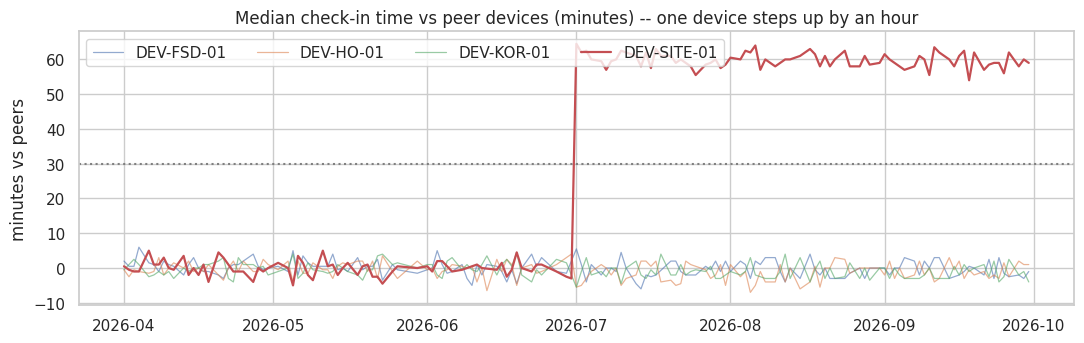

In [21]:
bad_device = summary["days_flagged"].idxmax()
flag_days = audit[(audit["device_id"] == bad_device) & audit["flagged"]]
drift_start, drift_end = flag_days["cal_date"].min(), flag_days["cal_date"].max()
drift_minutes = int(round(flag_days["gap_minutes"].median() / 15) * 15)

in_window = audit[(audit["device_id"] == bad_device) & (audit["cal_date"].between(drift_start, drift_end))]
print(f"faulty device : {bad_device}")
print(f"drift window  : {drift_start} to {drift_end}  ({in_window['flagged'].mean():.0%} of observed days inside the window are flagged)")
print(f"clock offset  : {drift_minutes:+d} minutes (device runs ahead of real time)")
print(f"healthy devices flagged on any day: {int(audit[audit['device_id'] != bad_device]['flagged'].sum())}")

fig, ax = plt.subplots(figsize=(11, 3.6))
for dev, grp in audit.groupby("device_id"):
    ax.plot(pd.to_datetime(grp["cal_date"]), grp["gap_minutes"], label=dev, linewidth=1.6 if dev == bad_device else 0.9, alpha=1 if dev == bad_device else 0.6)
ax.axhline(30, color="grey", linestyle=":")
ax.set_title("Median check-in time vs peer devices (minutes) -- one device steps up by an hour")
ax.set_ylabel("minutes vs peers")
ax.legend(ncol=4, loc="upper left")
plt.tight_layout()
plt.show()

In [22]:
audit_out = summary.reset_index()
audit_out["detected_offset_minutes"] = np.where(audit_out["device_id"] == bad_device, drift_minutes, 0)
write_table(audit_out, "staging", "device_clock_audit")

pm["ts_corrected"] = pm["ts"]
still_drifting = drift_end == audit["cal_date"].max()
apply_until = OPEN_END if still_drifting else drift_end
fix_mask = (pm["device_id"] == bad_device) & (pm["cal_date"] >= drift_start) & (pm["cal_date"] <= apply_until)
pm.loc[fix_mask, "ts_corrected"] = pm.loc[fix_mask, "ts"] - pd.Timedelta(minutes=drift_minutes)
print(f"drift still present on the last observed day: {still_drifting}")
print(f"{int(fix_mask.sum()):,} punches on {bad_device} shifted back by {drift_minutes} minutes")

after_probe = pm.merge(roster_daily[["emp_id", "work_date", "shift_code"]].rename(columns={"work_date": "cal_date2", "shift_code": "sc2"}),
                       left_on=["emp_id", pm["ts_corrected"].dt.strftime("%Y-%m-%d")], right_on=["emp_id", "cal_date2"], how="left")
after_probe = after_probe[after_probe["sc2"].isin(shift_start_min)].copy()
after_probe["minute_of_day"] = after_probe["ts_corrected"].dt.hour * 60 + after_probe["ts_corrected"].dt.minute
after_in = after_probe.groupby(["device_id", "cal_date2", "emp_id", "sc2"], as_index=False)["minute_of_day"].min()
after_in["gap"] = after_in["minute_of_day"] - after_in["sc2"].map(shift_start_min)
after_in["month"] = after_in["cal_date2"].str[:7]
pd.DataFrame({
    "before": first_in.assign(month=first_in["cal_date"].str[:7]).groupby(["device_id", "month"])["minutes_vs_shift_start"].median().unstack().loc[bad_device],
    "after": after_in.groupby(["device_id", "month"])["gap"].median().unstack().loc[bad_device],
}).T

drift still present on the last observed day: True
48,146 punches on DEV-SITE-01 shifted back by 60 minutes


month,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
before,-7.00,-7.00,-7.00,53.00,53.00,52.00
after,-7.00,-7.00,-7.00,-7.00,-7.00,-8.00


### 3.8 De-duplicating punches (the 2-minute rule)
This is a `LAG()` problem: order each employee's punches in time and compare every punch with the previous one. If the gap is 120 seconds or less, it is a repeat of the previous scan and is dropped (the first scan of the cluster survives). Dropped punches are not lost: they go to `staging.rejected_punches` with the reason `DUPLICATE_WITHIN_2_MIN`.

In [23]:
pm_out = pm[["punch_id", "device_id", "emp_id", "punch_time_raw", "ts_corrected"]].copy()
pm_out["punch_ts"] = pm_out["ts_corrected"].dt.strftime("%Y-%m-%d %H:%M:%S")
pm_out["clock_corrected"] = fix_mask.astype(int).values
write_table(pm_out[["punch_id", "device_id", "emp_id", "punch_time_raw", "punch_ts", "clock_corrected"]], "staging", "punches_corrected")
con.execute("CREATE INDEX IF NOT EXISTS staging.ix_pc ON punches_corrected (emp_id, punch_ts)")

gap_seconds = pd.read_sql_query("""
    SELECT strftime('%s', punch_ts) - strftime('%s', LAG(punch_ts) OVER (PARTITION BY emp_id ORDER BY punch_ts, punch_id)) AS gap_s
    FROM staging.punches_corrected""", con)["gap_s"].dropna()
print("gaps between consecutive punches of one employee:")
print(pd.cut(gap_seconds, [0, 30, 60, 119, 120, 600, 3600, 1e9], right=True).value_counts().sort_index().to_string())

gaps between consecutive punches of one employee:
gap_s
(0.0, 30.0]                 4553
(30.0, 60.0]                4950
(60.0, 119.0]               6672
(119.0, 120.0]                 0
(120.0, 600.0]                 0
(600.0, 3600.0]                0
(3600.0, 1000000000.0]    320883


In [24]:
run("""
DROP TABLE IF EXISTS staging.punches_flagged;
CREATE TABLE staging.punches_flagged AS
SELECT punch_id, device_id, emp_id, punch_time_raw, punch_ts, clock_corrected,
       strftime('%s', punch_ts) - strftime('%s', LAG(punch_ts) OVER (PARTITION BY emp_id ORDER BY punch_ts, punch_id)) AS secs_since_prev
FROM staging.punches_corrected;

INSERT INTO staging.rejected_punches
SELECT punch_id, device_id, NULL, punch_time_raw, emp_id, 'DUPLICATE_WITHIN_2_MIN',
       'scanned ' || secs_since_prev || 's after the previous punch of the same employee'
FROM staging.punches_flagged
WHERE secs_since_prev <= 120;

DROP TABLE IF EXISTS staging.punches;
CREATE TABLE staging.punches AS
SELECT punch_id, device_id, emp_id, punch_ts, clock_corrected
FROM staging.punches_flagged
WHERE secs_since_prev IS NULL OR secs_since_prev > 120;

CREATE INDEX staging.ix_punches ON punches (emp_id, punch_ts);
DROP TABLE staging.punches_flagged;
""")

recon = q("""
SELECT (SELECT COUNT(*) FROM raw.biometric_punches) AS raw_rows,
       (SELECT COUNT(*) FROM staging.punches) AS clean_punches,
       (SELECT COUNT(*) FROM staging.rejected_punches WHERE reason='UNMAPPED_DEVICE_USER') AS unmapped,
       (SELECT COUNT(*) FROM staging.rejected_punches WHERE reason='DUPLICATE_WITHIN_2_MIN') AS duplicates""")
recon["accounted_for"] = recon["clean_punches"] + recon["unmapped"] + recon["duplicates"]
recon

,raw_rows,clean_punches,unmapped,duplicates,accounted_for
0,345280,322143,6962,16175,345280


### 3.9 Leave requests: flatten the nested JSON
Each request holds its approval steps in a nested array. SQLite's `json_extract` / `json_each` flatten it into
- `staging.leave_requests` -- one row per request,
- `staging.leave_approval_steps` -- one row per approval step.

**Rule 16:** a request counts only if step 1 (Manager) **and** step 2 (HR) both say `Approved` and `cancelled_at` is empty. A request that stops after the Manager step, or whose HR step rejected it, does not count.

In [25]:
run("""
DROP TABLE IF EXISTS staging.leave_requests;
CREATE TABLE staging.leave_requests AS
SELECT TRIM(json_extract(payload, '$.request_id'))          AS request_id,
       TRIM(json_extract(payload, '$.employee.emp_id'))     AS emp_id,
       TRIM(json_extract(payload, '$.employee.plant'))      AS plant_on_request,
       TRIM(json_extract(payload, '$.leave.type'))          AS leave_type,
       date(json_extract(payload, '$.leave.from'))          AS leave_from,
       date(json_extract(payload, '$.leave.to'))            AS leave_to,
       CAST(json_extract(payload, '$.leave.days_requested') AS INTEGER) AS days_requested,
       datetime(json_extract(payload, '$.submitted_at'))    AS submitted_at,
       datetime(json_extract(payload, '$.cancelled_at'))    AS cancelled_at,
       json_array_length(payload, '$.approvals')            AS approval_steps
FROM raw.leave_requests;

DROP TABLE IF EXISTS staging.leave_approval_steps;
CREATE TABLE staging.leave_approval_steps AS
SELECT TRIM(json_extract(r.payload, '$.request_id'))  AS request_id,
       CAST(json_extract(a.value, '$.step') AS INTEGER) AS step_no,
       TRIM(json_extract(a.value, '$.approver_role'))  AS approver_role,
       TRIM(json_extract(a.value, '$.approver_id'))    AS approver_id,
       TRIM(json_extract(a.value, '$.action'))         AS action,
       datetime(json_extract(a.value, '$.acted_at'))   AS acted_at
FROM raw.leave_requests r, json_each(r.payload, '$.approvals') a;

CREATE UNIQUE INDEX staging.ix_las ON leave_approval_steps (request_id, step_no);

ALTER TABLE staging.leave_requests ADD COLUMN manager_action TEXT;
ALTER TABLE staging.leave_requests ADD COLUMN hr_action TEXT;
ALTER TABLE staging.leave_requests ADD COLUMN is_valid INTEGER;

UPDATE staging.leave_requests SET
    manager_action = (SELECT action FROM staging.leave_approval_steps s WHERE s.request_id = leave_requests.request_id AND s.step_no = 1 AND s.approver_role = 'Manager'),
    hr_action      = (SELECT action FROM staging.leave_approval_steps s WHERE s.request_id = leave_requests.request_id AND s.step_no = 2 AND s.approver_role = 'HR');

UPDATE staging.leave_requests SET is_valid =
    CASE WHEN manager_action = 'Approved' AND hr_action = 'Approved' AND cancelled_at IS NULL THEN 1 ELSE 0 END;
""")

q("""SELECT COALESCE(manager_action,'-') AS manager_step, COALESCE(hr_action,'(no HR step)') AS hr_step,
            CASE WHEN cancelled_at IS NULL THEN 'not cancelled' ELSE 'cancelled' END AS cancelled,
            COUNT(*) AS requests, SUM(is_valid) AS counted
     FROM staging.leave_requests GROUP BY 1,2,3 ORDER BY requests DESC""")

,manager_step,hr_step,cancelled,requests,counted
0,Approved,Approved,not cancelled,4282,4282
1,Rejected,(no HR step),not cancelled,467,0
2,Approved,Approved,cancelled,254,0
3,Approved,Rejected,not cancelled,217,0
4,Approved,(no HR step),not cancelled,152,0


`days_requested` is what the employee typed and is not trusted. A recursive CTE expands every **valid** request into one row per calendar day from `leave_from` to `leave_to`. Rule 17 then removes Sundays and the employee's plant holidays (those days already have their own attendance status). The plant is taken from the employee's department **on that day** (SCD history), not from the request.

In [26]:
run("""
DROP TABLE IF EXISTS staging.leave_days;
CREATE TABLE staging.leave_days AS
WITH RECURSIVE days(request_id, emp_id, leave_type, leave_date, last_date) AS (
    SELECT request_id, emp_id, leave_type, leave_from, leave_to FROM staging.leave_requests WHERE is_valid = 1
    UNION ALL
    SELECT request_id, emp_id, leave_type, date(leave_date, '+1 day'), last_date FROM days WHERE leave_date < last_date
),
placed AS (
    SELECT d.request_id, d.emp_id, d.leave_type, d.leave_date, dp.plant,
           CASE WHEN CAST(strftime('%w', d.leave_date) AS INTEGER) = 0 THEN 1 ELSE 0 END AS is_sunday,
           CASE WHEN EXISTS (SELECT 1 FROM staging.holiday_calendar hc WHERE hc.holiday_date = d.leave_date AND hc.plant = dp.plant) THEN 1 ELSE 0 END AS is_holiday,
           CASE WHEN e.emp_id IS NOT NULL AND d.leave_date >= e.hire_date AND d.leave_date <= COALESCE(e.separation_date, '9999-12-31') THEN 1 ELSE 0 END AS in_employment
    FROM days d
    JOIN staging.employees e ON e.emp_id = d.emp_id
    LEFT JOIN staging.employment_history h ON h.emp_id = d.emp_id AND d.leave_date BETWEEN h.valid_from AND h.valid_to
    LEFT JOIN staging.departments dp ON dp.dept_id = h.dept_id
)
SELECT *, CASE WHEN is_sunday = 0 AND is_holiday = 0 AND in_employment = 1 AND leave_date BETWEEN '2026-04-01' AND '2026-09-30' THEN 1 ELSE 0 END AS counts_as_leave_day
FROM placed;

CREATE INDEX staging.ix_ld ON leave_days (emp_id, leave_date);
""")

q("""SELECT COUNT(*) AS calendar_days_in_valid_requests,
            SUM(is_sunday) AS on_sundays, SUM(is_holiday) AS on_plant_holidays,
            SUM(1 - in_employment) AS outside_employment, SUM(counts_as_leave_day) AS real_leave_days,
            COUNT(*) - COUNT(DISTINCT emp_id || leave_date) AS overlapping_requests_same_day
     FROM staging.leave_days""")

,calendar_days_in_valid_requests,on_sundays,on_plant_holidays,outside_employment,real_leave_days,overlapping_requests_same_day
0,10220,1005,611,0,8604,0


### 3.10 Overtime requests, payroll lines, applications
Typed and trimmed; amounts and hours become numbers. Nothing is dropped here -- every status of OT request is kept, and the `is_approved` flag (rule 19: only `status = Approved`) is applied downstream.

In [27]:
ot = q("SELECT request_id, emp_id, ot_date, requested_hours, approved_hours, status, approver_id, requested_at FROM raw.overtime_requests")
for c in ["request_id", "emp_id", "status", "approver_id"]:
    ot[c] = squash(ot[c])
ot["ot_date"] = iso(to_iso_date(ot["ot_date"]))
ot["requested_hours"] = pd.to_numeric(ot["requested_hours"])
ot["approved_hours"] = pd.to_numeric(ot["approved_hours"])
ot["requested_at"] = pd.to_datetime(ot["requested_at"]).dt.strftime("%Y-%m-%d %H:%M:%S")
ot["is_approved"] = (ot["status"] == "Approved").astype(int)
write_table(ot, "staging", "overtime_requests")
con.execute("CREATE INDEX IF NOT EXISTS staging.ix_ot ON overtime_requests (emp_id, ot_date)")

pay = q("SELECT line_id, payroll_month, emp_id, component, component_type, units, amount FROM raw.payroll_lines")
for c in ["line_id", "payroll_month", "emp_id", "component", "component_type"]:
    pay[c] = squash(pay[c])
pay["component"] = pay["component"].str.upper()
pay["component_type"] = pay["component_type"].str.upper()
pay["units"] = pd.to_numeric(pay["units"])
pay["amount"] = pd.to_numeric(pay["amount"])
write_table(pay, "staging", "payroll_lines")
con.execute("CREATE INDEX IF NOT EXISTS staging.ix_pay ON payroll_lines (emp_id, payroll_month)")

apps = q("SELECT application_id, candidate_id, job_req_id, dept_id, stage, stage_date FROM raw.applications")
for c in apps.columns:
    apps[c] = squash(apps[c])
apps["stage_date"] = iso(to_iso_date(apps["stage_date"]))
write_table(apps, "staging", "applications")
con.commit()

print("overtime requests by status:", ot["status"].value_counts().to_dict())
print("payroll lines by type:", pay.groupby("component_type").size().to_dict())
pay.groupby(["component_type", "component"]).agg(lines=("amount", "size"), total_amount=("amount", "sum")).reset_index()

overtime requests by status: {'Approved': 19666, 'Rejected': 1346, 'Pending': 1086}
payroll lines by type: {'DEDUCTION': 18113, 'EARNING': 35504}


,component_type,component,lines,total_amount
0,DEDUCTION,ABSENCE_DEDUCTION,3228,10135030
1,DEDUCTION,EOBI,7233,2893200
2,DEDUCTION,INCOME_TAX,7136,19090533
3,DEDUCTION,LOAN_INSTALLMENT,516,4936000
4,EARNING,BASIC,7233,418719387
5,EARNING,CONVEYANCE,7233,27000239
6,EARNING,HOUSE_RENT,7233,188423724
7,EARNING,MEDICAL,7233,41871938
8,EARNING,OVERTIME,6572,19003890


## 4. Stage 3 -- Business logic in SQL: `staging.attendance_daily`
Goal: **one row per employee per day of employment** (1 April or hire date until 30 September or separation date), with one status, hours worked, late / early minutes and overtime.

The build is a chain of small, named steps so each business rule is visible on its own:

| Step | Table | What it does |
|---|---|---|
| 1 | `attendance_spine` | employee x day, with the department (SCD lookup), plant, shift (roster), Sunday and plant-holiday flags |
| 2 | `punch_shift_assignment` | decides which **shift date** every punch belongs to (night shifts!) |
| 3 | `shift_punch_pairs` | first punch = check-in, last punch = check-out, punch count |
| 4 | `attendance_daily` | status by priority, then late / early / overtime |

In [28]:
run("""
DROP TABLE IF EXISTS staging.calendar;
CREATE TABLE staging.calendar AS
WITH RECURSIVE d(cal_date) AS (
    SELECT '2026-03-30' UNION ALL SELECT date(cal_date, '+1 day') FROM d WHERE cal_date < '2026-10-31'
)
SELECT cal_date FROM d;
CREATE UNIQUE INDEX staging.ix_cal ON calendar (cal_date);

DROP TABLE IF EXISTS staging.attendance_spine;
CREATE TABLE staging.attendance_spine AS
SELECT e.emp_id,
       c.cal_date                                                       AS work_date,
       h.dept_id,
       d.plant,
       r.shift_code,
       CASE WHEN CAST(strftime('%w', c.cal_date) AS INTEGER) = 0 THEN 1 ELSE 0 END AS is_sunday,
       CASE WHEN EXISTS (SELECT 1 FROM staging.holiday_calendar hc
                         WHERE hc.holiday_date = c.cal_date AND hc.plant = d.plant) THEN 1 ELSE 0 END AS is_holiday
FROM staging.employees e
JOIN staging.calendar c
  ON c.cal_date BETWEEN MAX(e.hire_date, '2026-04-01') AND MIN(COALESCE(e.separation_date, '9999-12-31'), '2026-09-30')
JOIN staging.employment_history h
  ON h.emp_id = e.emp_id AND c.cal_date BETWEEN h.valid_from AND h.valid_to
JOIN staging.departments d ON d.dept_id = h.dept_id
LEFT JOIN staging.roster_daily r ON r.emp_id = e.emp_id AND r.work_date = c.cal_date;

CREATE UNIQUE INDEX staging.ix_spine ON attendance_spine (emp_id, work_date);
""")

q("""SELECT COUNT(*) AS employee_days, COUNT(DISTINCT emp_id) AS employees, SUM(is_sunday) AS sundays, SUM(is_holiday) AS plant_holidays,
            SUM(shift_code IS NULL) AS days_without_shift FROM staging.attendance_spine""")

,employee_days,employees,sundays,plant_holidays,days_without_shift
0,217584,1266,30899,10956,0


### Which shift date does a punch belong to? (rule 7)
A night shift starts at 22:00 and ends at 06:00 the next morning, so the check-out punch has the *next* calendar date. Rule: a punch belongs to the date the shift **started**.

For each punch look at the employee's shift on the **previous** calendar day:
- previous day is a **NIGHT** shift (Monday to Saturday -- no night shift starts on a Sunday) and the punch is before midday -> it is the check-out of that night shift, so it belongs to the previous date;
- previous day is an **EVE** shift and the punch is before 04:00 -> a late check-out after midnight, same treatment;
- anything else belongs to its own calendar date.

This is the same thing as "shift the punch back a few hours before taking its date", but driven by the roster so a Monday-morning *day shift* check-in after a Sunday does not get pulled back into the weekend.

In [29]:
run("""
DROP TABLE IF EXISTS staging.punch_shift_assignment;
CREATE TABLE staging.punch_shift_assignment AS
SELECT p.punch_id, p.emp_id, p.punch_ts,
       date(p.punch_ts) AS calendar_date,
       CASE
           WHEN prev.shift_code = 'NIGHT'
                AND CAST(strftime('%w', date(p.punch_ts, '-1 day')) AS INTEGER) <> 0
                AND CAST(strftime('%H', p.punch_ts) AS INTEGER) < 12
                THEN date(p.punch_ts, '-1 day')
           WHEN prev.shift_code = 'EVE' AND CAST(strftime('%H', p.punch_ts) AS INTEGER) < 4
                THEN date(p.punch_ts, '-1 day')
           ELSE date(p.punch_ts)
       END AS shift_date
FROM staging.punches p
LEFT JOIN staging.roster_daily prev
       ON prev.emp_id = p.emp_id AND prev.work_date = date(p.punch_ts, '-1 day');

CREATE INDEX staging.ix_psa ON punch_shift_assignment (emp_id, shift_date);

DROP TABLE IF EXISTS staging.shift_punch_pairs;
CREATE TABLE staging.shift_punch_pairs AS
SELECT emp_id, shift_date,
       MIN(punch_ts) AS check_in,
       MAX(punch_ts) AS check_out,
       COUNT(*)      AS n_punches
FROM staging.punch_shift_assignment
GROUP BY emp_id, shift_date;

CREATE UNIQUE INDEX staging.ix_spp ON shift_punch_pairs (emp_id, shift_date);
""")

q("""SELECT n_punches, COUNT(*) AS shift_days FROM staging.shift_punch_pairs GROUP BY n_punches ORDER BY n_punches""")

,n_punches,shift_days
0,1,2493
1,2,159825


In [30]:
night_check = q("""
SELECT r.shift_code, ROUND(AVG((strftime('%s', check_out) - strftime('%s', check_in)) / 3600.0), 2) AS avg_hours_between_first_and_last,
       ROUND(MAX((strftime('%s', check_out) - strftime('%s', check_in)) / 3600.0), 2) AS max_hours,
       COUNT(*) AS paired_days
FROM staging.shift_punch_pairs p
JOIN staging.roster_daily r ON r.emp_id = p.emp_id AND r.work_date = p.shift_date
WHERE n_punches >= 2
GROUP BY r.shift_code
""")
night_check

,shift_code,avg_hours_between_first_and_last,max_hours,paired_days
0,DAY,8.51,11.89,46608
1,EVE,8.40,10.31,46508
2,GEN,8.87,12.37,20395
3,NIGHT,8.51,11.90,46314


Sanity check on the logic: a night shift should show ~8-9 hours between first and last punch like every other shift. If check-outs were left on the wrong date they would show up as ~15-hour "days" or as lone single punches.

### Status, late, early, overtime
Status uses the priority order of rule 12, evaluated top to bottom (first match wins):

1. Sunday with no punches -> `Weekly Off`
2. Plant holiday with no punches -> `Holiday`
3. Approved leave day -> `On Leave`
4. two or more punches -> `Present`
5. one punch -> `Missing Punch`
6. nothing -> `Absent`

Timing rules, all computed from first / last punch and the shift definition (a night shift ends at 06:00 on the *next* day):
- **late arrival**: check-in more than 10 minutes after shift start; **early departure**: check-out more than 10 minutes before shift end -- both only on `Present` working days (not Sundays / holidays);
- **overtime on a working day**: minutes after shift end, rounded **down** to whole half-hours (29 min = 0 h, 45 min = 0.5 h, 75 min = 1.0 h);
- **overtime on a Sunday or holiday**: the whole check-in to check-out span, rounded down to half-hours.

In [31]:
run("""
DROP TABLE IF EXISTS staging.attendance_daily;
CREATE TABLE staging.attendance_daily AS
WITH joined AS (
    SELECT s.*, p.check_in, p.check_out, COALESCE(p.n_punches, 0) AS n_punches,
           sh.start_time, sh.end_time, sh.crosses_midnight,
           CASE WHEN EXISTS (SELECT 1 FROM staging.leave_days ld
                             WHERE ld.emp_id = s.emp_id AND ld.leave_date = s.work_date AND ld.counts_as_leave_day = 1)
                THEN 1 ELSE 0 END AS has_leave
    FROM staging.attendance_spine s
    LEFT JOIN staging.shift_punch_pairs p ON p.emp_id = s.emp_id AND p.shift_date = s.work_date
    LEFT JOIN staging.shifts sh ON sh.shift_code = s.shift_code
),
classified AS (
    SELECT *,
           CASE WHEN is_sunday = 1  AND n_punches = 0 THEN 'Weekly Off'
                WHEN is_holiday = 1 AND n_punches = 0 THEN 'Holiday'
                WHEN has_leave = 1                    THEN 'On Leave'
                WHEN n_punches >= 2                   THEN 'Present'
                WHEN n_punches = 1                    THEN 'Missing Punch'
                ELSE 'Absent' END AS status,
           CAST(strftime('%s', work_date || ' ' || start_time) AS INTEGER) AS shift_start_s,
           CAST(strftime('%s', CASE WHEN crosses_midnight = 1 THEN date(work_date, '+1 day') ELSE work_date END || ' ' || end_time) AS INTEGER) AS shift_end_s,
           CAST(strftime('%s', check_in) AS INTEGER)  AS in_s,
           CAST(strftime('%s', check_out) AS INTEGER) AS out_s
    FROM joined
),
measured AS (
    SELECT *,
           CASE WHEN status = 'Present' AND is_sunday = 0 AND is_holiday = 0 THEN in_s - shift_start_s END  AS late_s,
           CASE WHEN status = 'Present' AND is_sunday = 0 AND is_holiday = 0 THEN shift_end_s - out_s END   AS early_s
    FROM classified
)
SELECT emp_id, work_date, dept_id, plant, shift_code, is_sunday, is_holiday,
       CASE WHEN is_sunday = 0 AND is_holiday = 0 THEN 1 ELSE 0 END AS is_scheduled_day,
       status, check_in, check_out, n_punches,
       CASE WHEN status = 'Present' THEN ROUND((out_s - in_s) / 3600.0, 2) END AS worked_hours,
       CASE WHEN late_s  > 600 THEN 1 ELSE 0 END AS is_late,
       CASE WHEN late_s  > 600 THEN late_s / 60 ELSE 0 END AS late_minutes,
       CASE WHEN early_s > 600 THEN 1 ELSE 0 END AS is_early_departure,
       CASE WHEN early_s > 600 THEN early_s / 60 ELSE 0 END AS early_departure_minutes,
       CASE WHEN status <> 'Present' THEN 0.0
            WHEN is_sunday = 1 OR is_holiday = 1 THEN (MAX(out_s - in_s, 0) / 1800) * 0.5
            ELSE (MAX(out_s - shift_end_s, 0) / 1800) * 0.5 END AS overtime_hours,
       CASE WHEN has_leave = 1 AND n_punches > 0 THEN 1 ELSE 0 END AS punched_while_on_leave
FROM measured;

CREATE UNIQUE INDEX staging.ix_att ON attendance_daily (emp_id, work_date);
CREATE INDEX staging.ix_att_date ON attendance_daily (work_date);
""")

q("""SELECT status, COUNT(*) AS days, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct FROM staging.attendance_daily GROUP BY status ORDER BY days DESC""")

,status,days,pct
0,Present,159825,73.50
1,Weekly Off,30321,13.90
2,Holiday,10759,4.90
3,On Leave,8604,4.00
4,Absent,5582,2.60
5,Missing Punch,2493,1.10


In [32]:
q("""
SELECT strftime('%Y-%m', work_date) AS month,
       SUM(status = 'Present')                      AS present_days,
       SUM(status = 'Absent')                       AS absent_days,
       SUM(status = 'Missing Punch')                AS missing_punch_days,
       SUM(status = 'On Leave')                     AS leave_days,
       SUM(is_late)                                 AS late_arrivals,
       SUM(is_early_departure)                      AS early_departures,
       ROUND(SUM(overtime_hours), 1)                AS computed_ot_hours
FROM staging.attendance_daily
GROUP BY month ORDER BY month
""")

,month,present_days,absent_days,missing_punch_days,leave_days,late_arrivals,early_departures,computed_ot_hours
0,2026-04,28029,991,463,1528,1692,542,"6,167.00"
1,2026-05,23998,840,366,1328,1495,481,"6,274.00"
2,2026-06,25813,915,421,1330,1588,517,"6,140.50"
3,2026-07,28780,979,448,1488,1756,555,"6,281.50"
4,2026-08,25852,866,379,1346,1583,521,"6,472.00"
5,2026-09,27353,991,416,1584,1694,551,"6,066.00"


### Data quality checks on the staging layer
Run straight after the load (Stage 6 explains the framework). Reconciliation is the strongest one: **every raw row must be accounted for** as either a staging row or a logged rejection.

In [33]:
def rejected_count(table):
    return con.execute("SELECT COUNT(*) FROM staging.rejected_rows WHERE source_table = ?", (table,)).fetchone()[0]

recon_plan = {
    "employees": ("employees", rejected_count("employees")),
    "employment_history": ("employment_history", rejected_count("employment_history")),
    "departments": ("departments", 0),
    "shifts": ("shifts", 0),
    "shift_roster": ("shift_roster", 0),
    "device_mapping": ("device_mapping", 0),
    "biometric_punches": ("punches", n_rows("staging", "rejected_punches")),
    "holidays": ("holidays", 0),
    "leave_requests": ("leave_requests", 0),
    "overtime_requests": ("overtime_requests", 0),
    "payroll_lines": ("payroll_lines", 0),
    "applications": ("applications", 0),
}
recon_rows = []
for raw_table, (stg_table, rej) in recon_plan.items():
    raw_n, stg_n = n_rows("raw", raw_table), n_rows("staging", stg_table)
    dq("staging", stg_table, "reconciliation", "raw rows = staging rows + rejected rows", raw_n, stg_n + rej, detail=f"raw {raw_n} / staging {stg_n} / rejected {rej}")
    recon_rows.append({"raw_table": raw_table, "raw_rows": raw_n, "staging_rows": stg_n, "rejected_rows": rej, "balanced": raw_n == stg_n + rej})
pd.DataFrame(recon_rows)

,raw_table,raw_rows,staging_rows,rejected_rows,balanced
0,employees,1316,1266,50,True
1,employment_history,3686,3685,1,True
2,departments,25,25,0,True
3,shifts,4,4,0,True
4,shift_roster,36402,36402,0,True
5,device_mapping,1260,1260,0,True
6,biometric_punches,345280,322143,23137,True
7,holidays,12,12,0,True
8,leave_requests,5372,5372,0,True
9,overtime_requests,22098,22098,0,True


In [34]:
unique_keys = {
    "employees": "emp_id", "departments": "dept_id", "shifts": "shift_code", "leave_requests": "request_id",
    "overtime_requests": "request_id", "payroll_lines": "line_id", "punches": "punch_id",
}
for tbl, key in unique_keys.items():
    dq_zero("staging", tbl, "uniqueness", f"{key} is unique", f"SELECT COUNT(*) - COUNT(DISTINCT {key}) FROM staging.{tbl}")
    dq_zero("staging", tbl, "not_null", f"{key} is not null", f"SELECT COUNT(*) FROM staging.{tbl} WHERE {key} IS NULL")
composite_keys = {
    "employment_history": "emp_id, valid_from", "roster_daily": "emp_id, work_date", "attendance_daily": "emp_id, work_date",
    "device_mapping": "device_id, device_user_id", "leave_approval_steps": "request_id, step_no",
}
for tbl, key in composite_keys.items():
    dq_zero("staging", tbl, "uniqueness", f"({key}) has no duplicate groups", f"SELECT COUNT(*) FROM (SELECT 1 FROM staging.{tbl} GROUP BY {key} HAVING COUNT(*) > 1)")

dq_zero("staging", "attendance_daily", "business_sanity", "attendance row for every employee-day of employment",
        """SELECT (SELECT COUNT(*) FROM staging.attendance_spine) - (SELECT COUNT(*) FROM staging.attendance_daily)""")
dq_zero("staging", "attendance_daily", "business_sanity", "no punch lands outside the employee's days of employment",
        """SELECT COUNT(*) FROM staging.shift_punch_pairs p WHERE NOT EXISTS (SELECT 1 FROM staging.attendance_spine s WHERE s.emp_id = p.emp_id AND s.work_date = p.shift_date)""")
dq_zero("staging", "attendance_daily", "business_sanity", "no unmapped department or shift on any day",
        "SELECT COUNT(*) FROM staging.attendance_daily WHERE dept_id IS NULL OR shift_code IS NULL")
dq_zero("staging", "attendance_daily", "accepted_values", "status is one of the six allowed values",
        "SELECT COUNT(*) FROM staging.attendance_daily WHERE status NOT IN ('Present','Absent','On Leave','Holiday','Weekly Off','Missing Punch')")
q("SELECT layer, check_type, COUNT(*) AS checks, SUM(passed) AS passed FROM warehouse.dq_results WHERE layer = 'staging' GROUP BY layer, check_type")

,layer,check_type,checks,passed
0,staging,accepted_values,1,1
1,staging,business_sanity,3,3
2,staging,not_null,7,7
3,staging,reconciliation,12,12
4,staging,uniqueness,12,12


## 5. Stage 4 -- Model the warehouse: star schema with enforced keys
**Grain and design**

| Table | Grain | Notes |
|---|---|---|
| `dim_date` | one row per calendar day | `date_key` = `YYYYMMDD`, month-end flag, Sunday flag |
| `dim_department` | one row per department | plant, cost centre, previous name |
| `dim_shift` | one row per shift | start / end, crosses-midnight flag |
| `dim_employee` | one row per employee **version** (SCD Type 2) | `valid_from` / `valid_to` from employment history, `is_current` |
| `fact_attendance_daily` | employee x day | status, hours, late / early minutes, computed overtime |
| `fact_leave_day` | request x leave day | only counted leave days (rule 16 and 17) |
| `fact_overtime_approved` | approved OT request | approved hours |
| `fact_payroll_line` | employee x month x pay component | long format kept, pivoted at query time |

Every fact points at the **employee version that was valid on the fact's date**: `fact.work_date BETWEEN dim.valid_from AND dim.valid_to`. Payroll lines use the **last day of the month, or the last working day if the employee left that month** (rule 3). Primary keys, foreign keys, `CHECK` constraints and uniqueness are all enforced (`PRAGMA foreign_keys = ON`).

Attendance belongs to Workforce and Payroll only *consumes* it, so there is no attendance column inside the payroll fact: the two are joined by employee and month in the queries.

In [35]:
DDL_DIMENSIONS = """
DROP TABLE IF EXISTS warehouse.fact_payroll_line;
DROP TABLE IF EXISTS warehouse.fact_overtime_approved;
DROP TABLE IF EXISTS warehouse.fact_leave_day;
DROP TABLE IF EXISTS warehouse.fact_attendance_daily;
DROP VIEW  IF EXISTS warehouse.vw_employee_month;
DROP TABLE IF EXISTS warehouse.dim_employee;
DROP TABLE IF EXISTS warehouse.dim_shift;
DROP TABLE IF EXISTS warehouse.dim_department;
DROP TABLE IF EXISTS warehouse.dim_date;

CREATE TABLE warehouse.dim_date (
    date_key         INTEGER PRIMARY KEY,
    full_date        TEXT    NOT NULL UNIQUE,
    year_no          INTEGER NOT NULL,
    quarter_no       INTEGER NOT NULL,
    month_no         INTEGER NOT NULL,
    month_name       TEXT    NOT NULL,
    year_month       TEXT    NOT NULL,
    day_of_month     INTEGER NOT NULL,
    day_of_week_no   INTEGER NOT NULL CHECK (day_of_week_no BETWEEN 0 AND 6),
    day_name         TEXT    NOT NULL,
    is_sunday        INTEGER NOT NULL CHECK (is_sunday IN (0, 1)),
    is_month_end     INTEGER NOT NULL CHECK (is_month_end IN (0, 1)),
    month_start      TEXT    NOT NULL,
    month_end        TEXT    NOT NULL
);

CREATE TABLE warehouse.dim_department (
    department_key   INTEGER PRIMARY KEY,
    dept_id          TEXT    NOT NULL UNIQUE,
    dept_name        TEXT    NOT NULL,
    plant            TEXT    NOT NULL,
    cost_center      TEXT    NOT NULL,
    previous_name    TEXT,
    renamed_on       TEXT
);

CREATE TABLE warehouse.dim_shift (
    shift_key        INTEGER PRIMARY KEY,
    shift_code       TEXT    NOT NULL UNIQUE,
    shift_name       TEXT    NOT NULL,
    start_time       TEXT    NOT NULL,
    end_time         TEXT    NOT NULL,
    crosses_midnight INTEGER NOT NULL CHECK (crosses_midnight IN (0, 1)),
    grace_minutes    INTEGER NOT NULL
);

CREATE TABLE warehouse.dim_employee (
    employee_key             INTEGER PRIMARY KEY,
    emp_id                   TEXT    NOT NULL,
    version_no               INTEGER NOT NULL,
    full_name                TEXT    NOT NULL,
    gender                   TEXT,
    date_of_birth            TEXT,
    email                    TEXT,
    phone                    TEXT,
    hire_date                TEXT    NOT NULL,
    separation_date          TEXT,
    employment_type          TEXT,
    status                   TEXT,
    annual_leave_entitlement INTEGER NOT NULL,
    designation              TEXT,
    grade                    TEXT,
    basic_salary             REAL,
    change_reason            TEXT,
    department_key           INTEGER NOT NULL REFERENCES dim_department (department_key),
    valid_from               TEXT    NOT NULL,
    valid_to                 TEXT    NOT NULL,
    is_current               INTEGER NOT NULL CHECK (is_current IN (0, 1)),
    UNIQUE (emp_id, version_no),
    UNIQUE (emp_id, valid_from),
    CHECK (valid_from <= valid_to)
);
CREATE INDEX warehouse.ix_dim_emp_span ON dim_employee (emp_id, valid_from, valid_to);
"""

DDL_FACTS = """
CREATE TABLE warehouse.fact_attendance_daily (
    attendance_key          INTEGER PRIMARY KEY,
    employee_key            INTEGER NOT NULL REFERENCES dim_employee (employee_key),
    department_key          INTEGER NOT NULL REFERENCES dim_department (department_key),
    shift_key               INTEGER NOT NULL REFERENCES dim_shift (shift_key),
    date_key                INTEGER NOT NULL REFERENCES dim_date (date_key),
    status                  TEXT    NOT NULL CHECK (status IN ('Present', 'Absent', 'On Leave', 'Holiday', 'Weekly Off', 'Missing Punch')),
    is_sunday               INTEGER NOT NULL,
    is_holiday              INTEGER NOT NULL,
    is_scheduled_day        INTEGER NOT NULL,
    check_in                TEXT,
    check_out               TEXT,
    n_punches               INTEGER NOT NULL,
    worked_hours            REAL,
    is_late                 INTEGER NOT NULL,
    late_minutes            INTEGER NOT NULL,
    is_early_departure      INTEGER NOT NULL,
    early_departure_minutes INTEGER NOT NULL,
    overtime_hours          REAL    NOT NULL,
    UNIQUE (employee_key, date_key)
);

CREATE TABLE warehouse.fact_leave_day (
    leave_day_key   INTEGER PRIMARY KEY,
    request_id      TEXT    NOT NULL,
    employee_key    INTEGER NOT NULL REFERENCES dim_employee (employee_key),
    department_key  INTEGER NOT NULL REFERENCES dim_department (department_key),
    date_key        INTEGER NOT NULL REFERENCES dim_date (date_key),
    leave_type      TEXT    NOT NULL CHECK (leave_type IN ('Annual', 'Casual', 'Sick')),
    UNIQUE (request_id, date_key)
);

CREATE TABLE warehouse.fact_overtime_approved (
    overtime_key     INTEGER PRIMARY KEY,
    request_id       TEXT    NOT NULL UNIQUE,
    employee_key     INTEGER NOT NULL REFERENCES dim_employee (employee_key),
    department_key   INTEGER NOT NULL REFERENCES dim_department (department_key),
    date_key         INTEGER NOT NULL REFERENCES dim_date (date_key),
    requested_hours  REAL    NOT NULL,
    approved_hours   REAL    NOT NULL CHECK (approved_hours > 0),
    approver_id      TEXT
);

CREATE TABLE warehouse.fact_payroll_line (
    payroll_line_key INTEGER PRIMARY KEY,
    line_id          TEXT    NOT NULL UNIQUE,
    employee_key     INTEGER NOT NULL REFERENCES dim_employee (employee_key),
    department_key   INTEGER NOT NULL REFERENCES dim_department (department_key),
    month_end_key    INTEGER NOT NULL REFERENCES dim_date (date_key),
    payroll_month    TEXT    NOT NULL,
    component        TEXT    NOT NULL CHECK (component IN ('BASIC', 'HOUSE_RENT', 'MEDICAL', 'CONVEYANCE', 'OVERTIME', 'INCOME_TAX', 'EOBI', 'ABSENCE_DEDUCTION', 'LOAN_INSTALLMENT')),
    component_type   TEXT    NOT NULL CHECK (component_type IN ('EARNING', 'DEDUCTION')),
    units            REAL,
    amount           REAL    NOT NULL
);
CREATE INDEX warehouse.ix_fpl_emp ON fact_payroll_line (employee_key, payroll_month);
CREATE INDEX warehouse.ix_fad_emp ON fact_attendance_daily (employee_key, date_key);
"""

(PROJECT / "warehouse/ddl/01_dimensions.sql").write_text(DDL_DIMENSIONS)
(PROJECT / "warehouse/ddl/02_facts.sql").write_text(DDL_FACTS)
run(DDL_DIMENSIONS)
run(DDL_FACTS)
print("created:", [r[0] for r in con.execute("SELECT name FROM warehouse.sqlite_master WHERE type='table' AND name LIKE 'dim_%' OR name LIKE 'fact_%' ORDER BY name")])

created: ['dim_date', 'dim_department', 'dim_employee', 'dim_shift', 'fact_attendance_daily', 'fact_leave_day', 'fact_overtime_approved', 'fact_payroll_line']


### Load the dimensions
`dim_date` is a pandas date range (SQLite has no `generate_series` for tables; in PostgreSQL this would be `generate_series`). `dim_employee` joins each employee to **every history version**, so one person can have several rows, each valid for a different date span.

In [36]:
dates = pd.DataFrame({"full_date": pd.date_range("2026-03-01", "2026-10-31")})
dd = pd.DataFrame({
    "date_key": dates["full_date"].dt.strftime("%Y%m%d").astype(int),
    "full_date": iso(dates["full_date"]),
    "year_no": dates["full_date"].dt.year, "quarter_no": dates["full_date"].dt.quarter,
    "month_no": dates["full_date"].dt.month, "month_name": dates["full_date"].dt.month_name(),
    "year_month": dates["full_date"].dt.strftime("%Y-%m"), "day_of_month": dates["full_date"].dt.day,
    "day_of_week_no": dates["full_date"].dt.dayofweek, "day_name": dates["full_date"].dt.day_name(),
    "is_sunday": (dates["full_date"].dt.dayofweek == 6).astype(int),
    "is_month_end": dates["full_date"].dt.is_month_end.astype(int),
    "month_start": iso(dates["full_date"].dt.to_period("M").dt.start_time),
    "month_end": iso(dates["full_date"].dt.to_period("M").dt.end_time.dt.normalize()),
})
con.executemany(f"INSERT INTO warehouse.dim_date VALUES ({','.join('?' * dd.shape[1])})", dd.itertuples(index=False, name=None))

run("""
INSERT INTO warehouse.dim_department (department_key, dept_id, dept_name, plant, cost_center, previous_name, renamed_on)
SELECT CAST(substr(dept_id, 2) AS INTEGER), dept_id, dept_name, plant, cost_center, previous_name, renamed_on FROM staging.departments;

INSERT INTO warehouse.dim_shift (shift_key, shift_code, shift_name, start_time, end_time, crosses_midnight, grace_minutes)
SELECT ROW_NUMBER() OVER (ORDER BY start_time), shift_code, shift_name, start_time, end_time, crosses_midnight, grace_minutes FROM staging.shifts;

INSERT INTO warehouse.dim_employee
SELECT ROW_NUMBER() OVER (ORDER BY e.emp_id, h.version_no) AS employee_key,
       e.emp_id, h.version_no, e.full_name, e.gender, e.date_of_birth, e.email, e.phone, e.hire_date, e.separation_date,
       e.employment_type, e.status, e.annual_leave_entitlement,
       h.designation, h.grade, h.basic_salary, h.change_reason, dep.department_key, h.valid_from, h.valid_to, h.is_current
FROM staging.employees e
JOIN staging.employment_history h ON h.emp_id = e.emp_id
JOIN warehouse.dim_department dep ON dep.dept_id = h.dept_id;
""")

q("""SELECT (SELECT COUNT(*) FROM warehouse.dim_date) AS dim_date, (SELECT COUNT(*) FROM warehouse.dim_department) AS dim_department,
            (SELECT COUNT(*) FROM warehouse.dim_shift) AS dim_shift, (SELECT COUNT(*) FROM warehouse.dim_employee) AS dim_employee_versions,
            (SELECT COUNT(DISTINCT emp_id) FROM warehouse.dim_employee) AS distinct_employees""")

,dim_date,dim_department,dim_shift,dim_employee_versions,distinct_employees
0,245,25,4,3685,1266


In [37]:
q("""SELECT emp_id, version_no, designation, grade, basic_salary, change_reason, valid_from, valid_to, is_current
     FROM warehouse.dim_employee
     WHERE emp_id IN (SELECT emp_id FROM warehouse.dim_employee WHERE change_reason = 'Transfer' LIMIT 1)
     ORDER BY version_no""")

,emp_id,version_no,designation,grade,basic_salary,change_reason,valid_from,valid_to,is_current
0,E10019,1,Operator,G1,"27,000.00",Hire,2017-04-02,2025-06-30,0
1,E10019,2,Operator,G1,"38,000.00",Salary Revision,2025-07-01,2026-06-30,0
2,E10019,3,Operator,G1,"42,000.00",Salary Revision,2026-07-01,2026-07-03,0
3,E10019,4,Operator,G1,"42,000.00",Transfer,2026-07-04,9999-12-31,1


### Load the facts
Each fact finds its employee version with the SCD2 join. Rows that cannot find a version would violate the foreign key and stop the load, which is exactly the point of enforcing keys.

In [38]:
run("""
INSERT INTO warehouse.fact_attendance_daily
SELECT ROW_NUMBER() OVER (ORDER BY a.emp_id, a.work_date),
       de.employee_key, de.department_key, ds.shift_key, CAST(REPLACE(a.work_date, '-', '') AS INTEGER),
       a.status, a.is_sunday, a.is_holiday, a.is_scheduled_day, a.check_in, a.check_out, a.n_punches, a.worked_hours,
       a.is_late, a.late_minutes, a.is_early_departure, a.early_departure_minutes, a.overtime_hours
FROM staging.attendance_daily a
JOIN warehouse.dim_employee de ON de.emp_id = a.emp_id AND a.work_date BETWEEN de.valid_from AND de.valid_to
JOIN warehouse.dim_shift ds ON ds.shift_code = a.shift_code;

INSERT INTO warehouse.fact_leave_day (leave_day_key, request_id, employee_key, department_key, date_key, leave_type)
SELECT ROW_NUMBER() OVER (ORDER BY l.request_id, l.leave_date),
       l.request_id, de.employee_key, de.department_key, CAST(REPLACE(l.leave_date, '-', '') AS INTEGER), l.leave_type
FROM staging.leave_days l
JOIN warehouse.dim_employee de ON de.emp_id = l.emp_id AND l.leave_date BETWEEN de.valid_from AND de.valid_to
WHERE l.counts_as_leave_day = 1;

INSERT INTO warehouse.fact_overtime_approved (overtime_key, request_id, employee_key, department_key, date_key, requested_hours, approved_hours, approver_id)
SELECT ROW_NUMBER() OVER (ORDER BY o.request_id),
       o.request_id, de.employee_key, de.department_key, CAST(REPLACE(o.ot_date, '-', '') AS INTEGER), o.requested_hours, o.approved_hours, o.approver_id
FROM staging.overtime_requests o
JOIN warehouse.dim_employee de ON de.emp_id = o.emp_id AND o.ot_date BETWEEN de.valid_from AND de.valid_to
WHERE o.is_approved = 1;

INSERT INTO warehouse.fact_payroll_line (payroll_line_key, line_id, employee_key, department_key, month_end_key, payroll_month, component, component_type, units, amount)
WITH pay AS (
    SELECT p.*, date(p.payroll_month || '-01', '+1 month', '-1 day') AS month_end, e.hire_date, e.separation_date
    FROM staging.payroll_lines p JOIN staging.employees e ON e.emp_id = p.emp_id
),
ref AS (
    SELECT pay.*, MAX(MIN(month_end, COALESCE(separation_date, '9999-12-31')), hire_date) AS ref_date FROM pay
)
SELECT ROW_NUMBER() OVER (ORDER BY ref.line_id),
       ref.line_id, de.employee_key, de.department_key, CAST(REPLACE(ref.month_end, '-', '') AS INTEGER),
       ref.payroll_month, ref.component, ref.component_type, ref.units, ref.amount
FROM ref JOIN warehouse.dim_employee de ON de.emp_id = ref.emp_id AND ref.ref_date BETWEEN de.valid_from AND de.valid_to;
""")

loaded = pd.DataFrame({
    "fact": ["fact_attendance_daily", "fact_leave_day", "fact_overtime_approved", "fact_payroll_line"],
    "source_rows": [n_rows("staging", "attendance_daily"), int(con.execute("SELECT SUM(counts_as_leave_day) FROM staging.leave_days").fetchone()[0]),
                    int(con.execute("SELECT SUM(is_approved) FROM staging.overtime_requests").fetchone()[0]), n_rows("staging", "payroll_lines")],
})
loaded["fact_rows"] = [n_rows("warehouse", f) for f in loaded["fact"]]
loaded["lost_rows"] = loaded["source_rows"] - loaded["fact_rows"]
loaded

,fact,source_rows,fact_rows,lost_rows
0,fact_attendance_daily,217584,217584,0
1,fact_leave_day,8604,8604,0
2,fact_overtime_approved,19666,19666,0
3,fact_payroll_line,53617,53617,0


### One reusable view: who belonged to which department in a given month
Rule 3 says monthly numbers (headcount, overtime, payroll cost) belong to the department the employee was in **on the last day of the month**, or on their **last working day** if they left during the month. That lookup is needed by several questions, so it lives in one view: one row per employee per month of employment, with the employee version valid on that reference date.

In [39]:
run("""
DROP VIEW IF EXISTS warehouse.vw_employee_month;
CREATE VIEW warehouse.vw_employee_month AS
SELECT de.emp_id,
       m.year_month,
       m.month_start,
       m.month_end,
       MIN(m.month_end, COALESCE(de.separation_date, '9999-12-31')) AS reference_date,
       de.employee_key,
       de.department_key
FROM (SELECT DISTINCT year_month, month_start, month_end FROM warehouse.dim_date WHERE month_end BETWEEN '2026-04-01' AND '2026-09-30') m
JOIN warehouse.dim_employee de
  ON de.hire_date <= m.month_end
 AND COALESCE(de.separation_date, '9999-12-31') >= m.month_start
 AND MIN(m.month_end, COALESCE(de.separation_date, '9999-12-31')) BETWEEN de.valid_from AND de.valid_to;
""")
(PROJECT / "warehouse/ddl/03_views.sql").write_text("""CREATE VIEW warehouse.vw_employee_month AS ... -- see notebook, section 5""")

q("""SELECT year_month, COUNT(*) AS employees_in_month, COUNT(DISTINCT department_key) AS departments
     FROM warehouse.vw_employee_month GROUP BY year_month ORDER BY year_month""")

,year_month,employees_in_month,departments
0,2026-04,1213,25
1,2026-05,1212,25
2,2026-06,1206,25
3,2026-07,1203,25
4,2026-08,1191,25
5,2026-09,1187,25


### ER diagram
Drawn straight from the live schema (`PRAGMA table_info` / `foreign_key_list`), so it can never drift from the real tables. Saved to `warehouse/erd.png`.

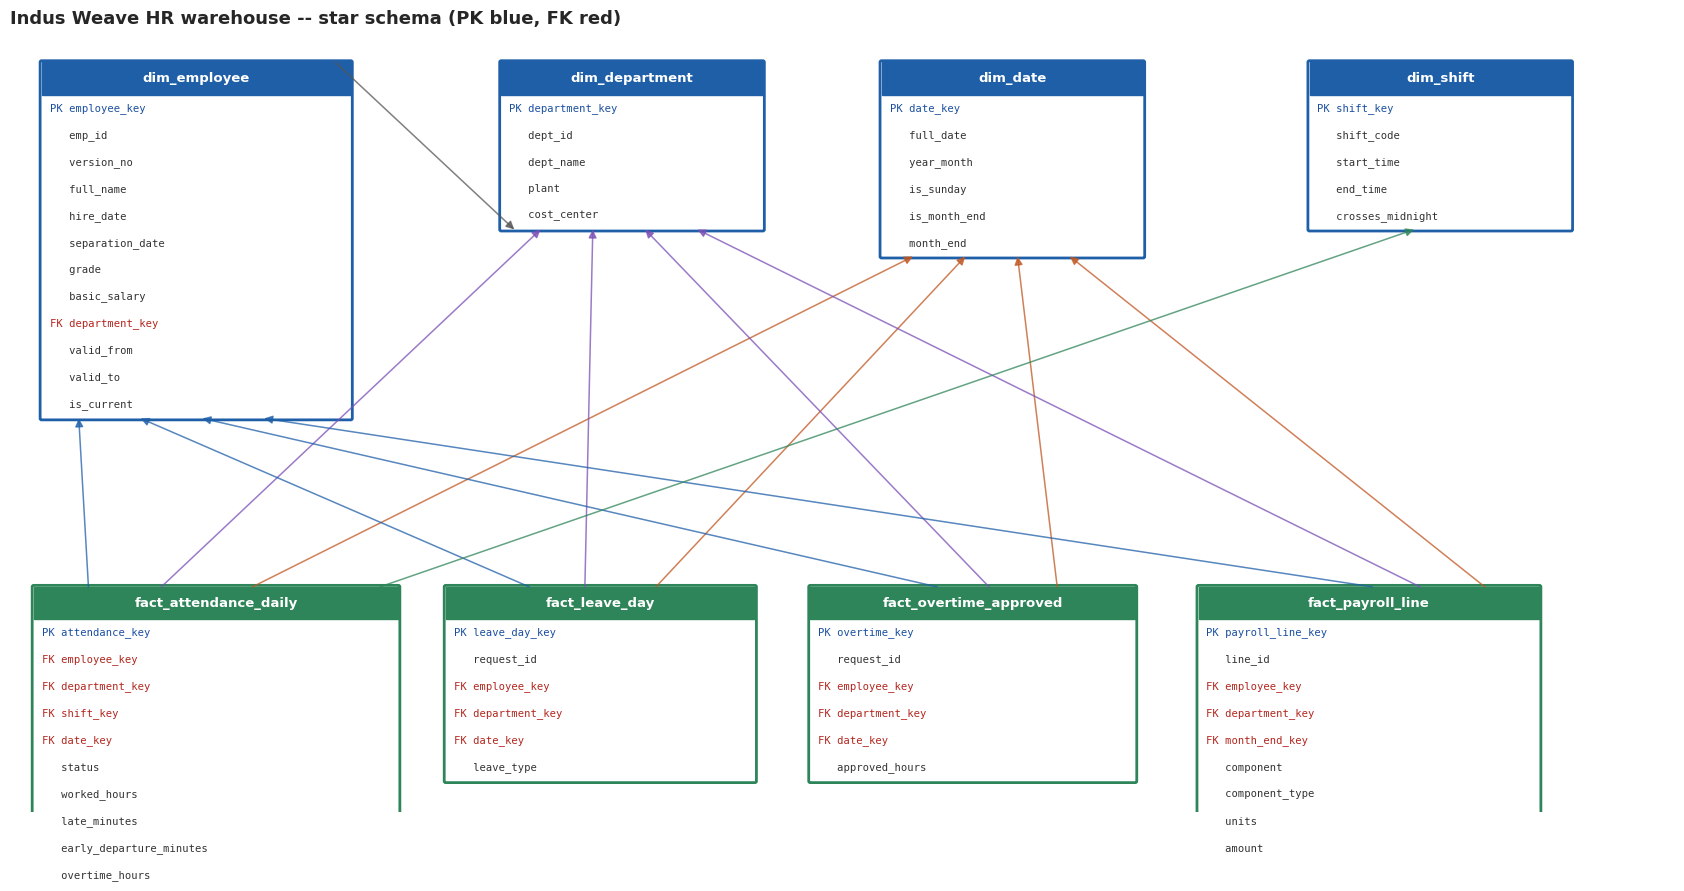

In [40]:
from matplotlib.patches import FancyBboxPatch, Rectangle

def table_columns(name):
    info = con.execute(f"PRAGMA warehouse.table_info({name})").fetchall()
    fks = {r[3] for r in con.execute(f"PRAGMA warehouse.foreign_key_list({name})")}
    cols = []
    for _, cname, ctype, _, _, pk in info:
        tag = "PK " if pk else ("FK " if cname in fks else "   ")
        cols.append(f"{tag}{cname}")
    return cols

KEEP = {
    "dim_date": ["date_key", "full_date", "year_month", "is_sunday", "is_month_end", "month_end"],
    "dim_department": ["department_key", "dept_id", "dept_name", "plant", "cost_center"],
    "dim_shift": ["shift_key", "shift_code", "start_time", "end_time", "crosses_midnight"],
    "dim_employee": ["employee_key", "emp_id", "version_no", "full_name", "hire_date", "separation_date", "grade", "basic_salary",
                     "department_key", "valid_from", "valid_to", "is_current"],
    "fact_attendance_daily": ["attendance_key", "employee_key", "department_key", "shift_key", "date_key", "status", "worked_hours",
                              "late_minutes", "early_departure_minutes", "overtime_hours"],
    "fact_leave_day": ["leave_day_key", "request_id", "employee_key", "department_key", "date_key", "leave_type"],
    "fact_overtime_approved": ["overtime_key", "request_id", "employee_key", "department_key", "date_key", "approved_hours"],
    "fact_payroll_line": ["payroll_line_key", "line_id", "employee_key", "department_key", "month_end_key", "component",
                          "component_type", "units", "amount"],
}

def draw_box(ax, x, top, name, color, width=3.3):
    cols = [c for c in table_columns(name) if c[3:] in KEEP[name]]
    row = 0.36
    height = row * (len(cols) + 1.2)
    ax.add_patch(FancyBboxPatch((x, top - height), width, height, boxstyle="round,pad=0.02", fc="white", ec=color, lw=2))
    ax.add_patch(Rectangle((x, top - row * 1.2), width, row * 1.2, fc=color, ec=color))
    ax.text(x + width / 2, top - row * 0.6, name, ha="center", va="center", color="white", fontweight="bold", fontsize=9.5)
    for i, c in enumerate(cols):
        ax.text(x + 0.1, top - row * (i + 1.2) - row * 0.5, c, va="center", fontsize=7.6, family="monospace",
                color="#b3261e" if c.startswith("FK") else ("#1a4fa0" if c.startswith("PK") else "#333"))
    return {"x": x, "top": top, "w": width, "h": height, "bottom": top - height, "cx": x + width / 2}

fig, ax = plt.subplots(figsize=(17, 9))
ax.set_xlim(0, 21); ax.set_ylim(3.6, 14); ax.axis("off")
BLUE, GREEN = "#1f5fa8", "#2f855a"
b = {}
b["dim_employee"] = draw_box(ax, 0.4, 13.6, "dim_employee", BLUE, 3.9)
b["dim_department"] = draw_box(ax, 6.2, 13.6, "dim_department", BLUE)
b["dim_date"] = draw_box(ax, 11.0, 13.6, "dim_date", BLUE)
b["dim_shift"] = draw_box(ax, 16.4, 13.6, "dim_shift", BLUE)
b["fact_attendance_daily"] = draw_box(ax, 0.3, 6.6, "fact_attendance_daily", GREEN, 4.6)
b["fact_leave_day"] = draw_box(ax, 5.5, 6.6, "fact_leave_day", GREEN, 3.9)
b["fact_overtime_approved"] = draw_box(ax, 10.1, 6.6, "fact_overtime_approved", GREEN, 4.1)
b["fact_payroll_line"] = draw_box(ax, 15.0, 6.6, "fact_payroll_line", GREEN, 4.3)

def link(fact, dim, fx, dx, color="#555"):
    f, d = b[fact], b[dim]
    ax.annotate("", xy=(d["x"] + d["w"] * dx, d["bottom"]), xytext=(f["x"] + f["w"] * fx, f["top"]),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.1, alpha=0.75, shrinkA=0, shrinkB=0))

link("dim_employee", "dim_department", 0.95, 0.05)
for i, fact in enumerate(["fact_attendance_daily", "fact_leave_day", "fact_overtime_approved", "fact_payroll_line"]):
    link(fact, "dim_employee", 0.15 + 0.12 * i, 0.12 + 0.2 * i, "#1f5fa8")
    link(fact, "dim_department", 0.35 + 0.1 * i, 0.15 + 0.2 * i, "#7a4fb5")
    link(fact, "dim_date", 0.6 + 0.08 * i, 0.12 + 0.2 * i, "#c05621")
link("fact_attendance_daily", "dim_shift", 0.95, 0.4, "#2f855a")

ax.set_title("Indus Weave HR warehouse -- star schema (PK blue, FK red)", fontsize=13, fontweight="bold", loc="left")
plt.tight_layout()
fig.savefig(PROJECT / "warehouse" / "erd.png", dpi=130, bbox_inches="tight")
plt.show()

## 6. Stage 5 -- The 10 business questions (SQL)
One `.sql` file per question, written to `analytics/`, run against the **warehouse** tables only, with the result saved as a CSV in `analytics/results/`. Each question below states its definition first, because most disagreements about HR numbers are really disagreements about the definition.

In [41]:
QUERIES = {}
RESULTS = {}

def run_question(name, sql):
    sql = sql.strip() + "\n"
    (PROJECT / "analytics" / f"{name}.sql").write_text(sql)
    result = q(sql)
    result.to_csv(PROJECT / "analytics" / "results" / f"{name}.csv", index=False)
    QUERIES[name], RESULTS[name] = sql, result
    print(f"{name}: {len(result):,} rows -> analytics/results/{name}.csv")
    return result

### Q1. Month-end headcount by plant and department
An employee is in the headcount at month end if `hire_date <= month_end` and they have no `separation_date`, or the separation date is **after** month end (`separation_date` is the last day worked). The department is the SCD2 version valid on the month-end date. A cross join of months x departments keeps empty departments visible as zero.

In [42]:
run_question("q01_headcount", """
WITH month_ends AS (
    SELECT DISTINCT year_month, month_end
    FROM warehouse.dim_date
    WHERE month_end BETWEEN '2026-04-01' AND '2026-09-30'
),
dept_months AS (
    SELECT m.year_month, m.month_end, d.department_key, d.plant, d.dept_name
    FROM month_ends m CROSS JOIN warehouse.dim_department d
),
active AS (
    SELECT dm.year_month, dm.department_key, COUNT(DISTINCT e.emp_id) AS headcount
    FROM dept_months dm
    JOIN warehouse.dim_employee e
      ON dm.month_end BETWEEN e.valid_from AND e.valid_to
     AND e.department_key = dm.department_key
     AND e.hire_date <= dm.month_end
     AND (e.separation_date IS NULL OR e.separation_date > dm.month_end)
    GROUP BY dm.year_month, dm.department_key
)
SELECT dm.year_month, dm.plant, dm.dept_name AS department, COALESCE(a.headcount, 0) AS headcount
FROM dept_months dm
LEFT JOIN active a ON a.year_month = dm.year_month AND a.department_key = dm.department_key
ORDER BY dm.year_month, dm.plant, dm.dept_name
""")
pivot = RESULTS["q01_headcount"].pivot_table(index="plant", columns="year_month", values="headcount", aggfunc="sum")
pivot.loc["TOTAL"] = pivot.sum()
pivot

q01_headcount: 150 rows -> analytics/results/q01_headcount.csv


year_month,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
plant,,,,,,
Faisalabad Plant,371,371,367,365,366,363
Head Office,118,119,122,119,119,120
Korangi Plant,379,379,376,372,372,370
SITE Plant,331,327,327,321,325,323
TOTAL,1199,1196,1192,1177,1182,1176


### Q2. Monthly attrition rate by department
`attrition % = separations in the month / average headcount x 100`, where average headcount = (opening + closing) / 2. Opening is the headcount at the previous month end (31 March for April). A separation belongs to the department the employee was in on their **last working day**.

In [43]:
run_question("q02_attrition", """
WITH months AS (
    SELECT DISTINCT year_month, month_start, month_end, date(month_start, '-1 day') AS prev_month_end
    FROM warehouse.dim_date
    WHERE month_end BETWEEN '2026-04-01' AND '2026-09-30'
),
snapshots AS (
    SELECT month_end AS snap_date FROM months UNION SELECT prev_month_end FROM months
),
headcount AS (
    SELECT s.snap_date, e.department_key, COUNT(DISTINCT e.emp_id) AS headcount
    FROM snapshots s
    JOIN warehouse.dim_employee e
      ON s.snap_date BETWEEN e.valid_from AND e.valid_to
     AND e.hire_date <= s.snap_date
     AND (e.separation_date IS NULL OR e.separation_date > s.snap_date)
    GROUP BY s.snap_date, e.department_key
),
separations AS (
    SELECT m.year_month, e.department_key, COUNT(DISTINCT e.emp_id) AS separations
    FROM months m
    JOIN warehouse.dim_employee e
      ON e.separation_date BETWEEN m.month_start AND m.month_end
     AND e.separation_date BETWEEN e.valid_from AND e.valid_to
    GROUP BY m.year_month, e.department_key
)
SELECT m.year_month, d.plant, d.dept_name AS department,
       COALESCE(o.headcount, 0) AS opening_headcount,
       COALESCE(c.headcount, 0) AS closing_headcount,
       ROUND((COALESCE(o.headcount, 0) + COALESCE(c.headcount, 0)) / 2.0, 1) AS average_headcount,
       COALESCE(s.separations, 0) AS separations,
       ROUND(100.0 * COALESCE(s.separations, 0) / NULLIF((COALESCE(o.headcount, 0) + COALESCE(c.headcount, 0)) / 2.0, 0), 2) AS attrition_pct
FROM months m
CROSS JOIN warehouse.dim_department d
LEFT JOIN headcount o ON o.snap_date = m.prev_month_end AND o.department_key = d.department_key
LEFT JOIN headcount c ON c.snap_date = m.month_end      AND c.department_key = d.department_key
LEFT JOIN separations s ON s.year_month = m.year_month  AND s.department_key = d.department_key
ORDER BY m.year_month, d.plant, d.dept_name
""")
att = RESULTS["q02_attrition"]
print("total separations:", int(att["separations"].sum()), "(employees file says 90 separated)")
att.sort_values("attrition_pct", ascending=False).head(8)

q02_attrition: 150 rows -> analytics/results/q02_attrition.csv
total separations: 90 (employees file says 90 separated)


,year_month,plant,department,opening_headcount,closing_headcount,average_headcount,separations,attrition_pct
85,2026-07,Head Office,IT,15,13,14.00,2,14.29
9,2026-04,Head Office,Human Resources,16,14,15.00,2,13.33
32,2026-05,Head Office,Compliance,12,12,12.00,1,8.33
92,2026-07,Korangi Plant,Warehouse,28,28,28.00,2,7.14
96,2026-07,SITE Plant,Maintenance,31,29,30.00,2,6.67
90,2026-07,Korangi Plant,Quality Control,39,38,38.50,2,5.19
8,2026-04,Head Office,Finance,20,19,19.50,1,5.13
87,2026-07,Head Office,Supply Chain,21,20,20.50,1,4.88


### Q3. Absenteeism rate by plant and month (approved leave excluded)
`absenteeism % = Absent days / expected working days x 100`. Expected working days = scheduled days (not Sunday, not a plant holiday) **minus days on approved leave**, so someone on approved leave is neither absent nor expected. `Missing Punch` days stay in the denominator but are not counted as absent. The plant is the one the employee's month-end department belongs to (rule 3), through the `vw_employee_month` view.

In [44]:
run_question("q03_absenteeism", """
SELECT dd.year_month, dep.plant,
       SUM(CASE WHEN f.is_scheduled_day = 1 AND f.status <> 'On Leave' THEN 1 ELSE 0 END) AS expected_working_days,
       SUM(CASE WHEN f.status = 'Absent' THEN 1 ELSE 0 END)                               AS absent_days,
       SUM(CASE WHEN f.status = 'On Leave' THEN 1 ELSE 0 END)                             AS approved_leave_days_excluded,
       ROUND(100.0 * SUM(CASE WHEN f.status = 'Absent' THEN 1 ELSE 0 END)
             / NULLIF(SUM(CASE WHEN f.is_scheduled_day = 1 AND f.status <> 'On Leave' THEN 1 ELSE 0 END), 0), 2) AS absenteeism_pct
FROM warehouse.fact_attendance_daily f
JOIN warehouse.dim_date dd ON dd.date_key = f.date_key
JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
JOIN warehouse.vw_employee_month em ON em.emp_id = de.emp_id AND em.year_month = dd.year_month
JOIN warehouse.dim_department dep ON dep.department_key = em.department_key
GROUP BY dd.year_month, dep.plant
ORDER BY dd.year_month, dep.plant
""")
RESULTS["q03_absenteeism"].pivot_table(index="plant", columns="year_month", values="absenteeism_pct")

q03_absenteeism: 24 rows -> analytics/results/q03_absenteeism.csv


year_month,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
plant,,,,,,
Faisalabad Plant,4.04,3.85,4.24,4.26,3.78,4.10
Head Office,1.81,2.15,1.97,1.84,2.18,2.19
Korangi Plant,3.21,3.29,3.15,2.96,3.00,3.27
SITE Plant,3.40,3.34,3.21,3.01,3.20,3.41


### Q4. The 10 employees with the most late arrivals
Late = check-in more than 10 minutes after shift start, counted only on `Present` working days. `ROW_NUMBER()` breaks ties by total late minutes, then by `emp_id`, so the list is always exactly 10 people. Department = the employee's latest department.

In [45]:
run_question("q04_top_late_arrivals", """
WITH late AS (
    SELECT de.emp_id, SUM(f.is_late) AS late_arrivals, SUM(f.late_minutes) AS total_late_minutes,
           SUM(CASE WHEN f.status = 'Present' AND f.is_scheduled_day = 1 THEN 1 ELSE 0 END) AS present_working_days
    FROM warehouse.fact_attendance_daily f
    JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
    GROUP BY de.emp_id
),
ranked AS (
    SELECT l.*, ROW_NUMBER() OVER (ORDER BY l.late_arrivals DESC, l.total_late_minutes DESC, l.emp_id) AS rank_no
    FROM late l
)
SELECT r.rank_no, r.emp_id, cur.full_name, dep.dept_name AS department, dep.plant,
       r.late_arrivals, r.present_working_days, ROUND(100.0 * r.late_arrivals / r.present_working_days, 1) AS late_rate_pct, r.total_late_minutes
FROM ranked r
JOIN warehouse.dim_employee cur ON cur.emp_id = r.emp_id AND cur.is_current = 1
JOIN warehouse.dim_department dep ON dep.department_key = cur.department_key
WHERE r.rank_no <= 10
ORDER BY r.rank_no
""")

q04_top_late_arrivals: 10 rows -> analytics/results/q04_top_late_arrivals.csv


,rank_no,emp_id,full_name,department,plant,late_arrivals,present_working_days,late_rate_pct,total_late_minutes
0,1,E10580,Usman Gill,Cutting,Faisalabad Plant,58,137,42.30,2596
1,2,E10454,Raheel Khan,Maintenance,Faisalabad Plant,51,135,37.80,2126
2,3,E10982,Adnan Akhtar,Production Planning,Korangi Plant,49,142,34.50,1932
3,4,E10283,Ali Raza,Cutting,Faisalabad Plant,47,138,34.10,2238
4,5,E10287,Naveed Hussain,Quality Control,Faisalabad Plant,47,128,36.70,2060
5,6,E10824,Usman Baig,Spinning,Korangi Plant,47,134,35.10,1825
6,7,E10741,Faisal Khan,Cutting,Faisalabad Plant,46,136,33.80,2022
7,8,E10984,Ahmed Qureshi,Weaving,Korangi Plant,46,130,35.40,2005
8,9,E11026,Umair Ansari,Utilities,SITE Plant,45,142,31.70,1997
9,10,E10901,Owais Awan,Weaving,Korangi Plant,45,134,33.60,1913


### Q5. Overtime: computed from punches vs approved vs paid, by department and month
Three versions of the same truth, side by side:
- **computed** = `fact_attendance_daily.overtime_hours` (from biometric punches, half-hour rounding rules 14-15);
- **approved** = `fact_overtime_approved.approved_hours` (status `Approved` only), by the month of the OT date;
- **paid** = payroll `OVERTIME` line `units`.

All three are assigned to the employee's **month-end department**. This is where the CFO story starts.

In [46]:
run_question("q05_overtime_computed_approved_paid", """
WITH computed AS (
    SELECT em.department_key, dd.year_month, SUM(f.overtime_hours) AS computed_ot_hours
    FROM warehouse.fact_attendance_daily f
    JOIN warehouse.dim_date dd ON dd.date_key = f.date_key
    JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
    JOIN warehouse.vw_employee_month em ON em.emp_id = de.emp_id AND em.year_month = dd.year_month
    GROUP BY em.department_key, dd.year_month
),
approved AS (
    SELECT em.department_key, dd.year_month, SUM(o.approved_hours) AS approved_ot_hours
    FROM warehouse.fact_overtime_approved o
    JOIN warehouse.dim_date dd ON dd.date_key = o.date_key
    JOIN warehouse.dim_employee de ON de.employee_key = o.employee_key
    JOIN warehouse.vw_employee_month em ON em.emp_id = de.emp_id AND em.year_month = dd.year_month
    GROUP BY em.department_key, dd.year_month
),
paid AS (
    SELECT p.department_key, p.payroll_month AS year_month, SUM(p.units) AS paid_ot_hours, SUM(p.amount) AS paid_ot_amount
    FROM warehouse.fact_payroll_line p
    WHERE p.component = 'OVERTIME'
    GROUP BY p.department_key, p.payroll_month
),
months AS (SELECT DISTINCT year_month FROM warehouse.dim_date WHERE month_end BETWEEN '2026-04-01' AND '2026-09-30')
SELECT m.year_month, d.plant, d.dept_name AS department,
       ROUND(COALESCE(c.computed_ot_hours, 0), 1) AS computed_ot_hours,
       ROUND(COALESCE(a.approved_ot_hours, 0), 1) AS approved_ot_hours,
       ROUND(COALESCE(p.paid_ot_hours, 0), 1)     AS paid_ot_hours,
       ROUND(COALESCE(p.paid_ot_hours, 0) - COALESCE(c.computed_ot_hours, 0), 1) AS paid_minus_computed,
       ROUND(100.0 * (COALESCE(p.paid_ot_hours, 0) - COALESCE(c.computed_ot_hours, 0)) / NULLIF(c.computed_ot_hours, 0), 1) AS paid_vs_computed_pct,
       ROUND(COALESCE(p.paid_ot_amount, 0), 0) AS paid_ot_amount_pkr
FROM months m
CROSS JOIN warehouse.dim_department d
LEFT JOIN computed c ON c.year_month = m.year_month AND c.department_key = d.department_key
LEFT JOIN approved a ON a.year_month = m.year_month AND a.department_key = d.department_key
LEFT JOIN paid p     ON p.year_month = m.year_month AND p.department_key = d.department_key
ORDER BY m.year_month, d.plant, d.dept_name
""")
ot_month = RESULTS["q05_overtime_computed_approved_paid"].groupby("year_month")[["computed_ot_hours", "approved_ot_hours", "paid_ot_hours"]].sum()
ot_month["paid_vs_computed_pct"] = (100 * (ot_month["paid_ot_hours"] / ot_month["computed_ot_hours"] - 1)).round(1)
ot_month

q05_overtime_computed_approved_paid: 150 rows -> analytics/results/q05_overtime_computed_approved_paid.csv


,computed_ot_hours,approved_ot_hours,paid_ot_hours,paid_vs_computed_pct
year_month,,,,
2026-04,"6,167.00","5,525.50","5,525.50",-10.40
2026-05,"6,274.00","5,806.50","5,806.50",-7.50
2026-06,"6,140.50","5,889.00","5,889.00",-4.10
2026-07,"6,281.50","6,249.00","6,249.00",-0.50
2026-08,"6,472.00","6,513.00","6,513.00",0.60
2026-09,"6,066.00","6,418.50","6,418.50",5.80


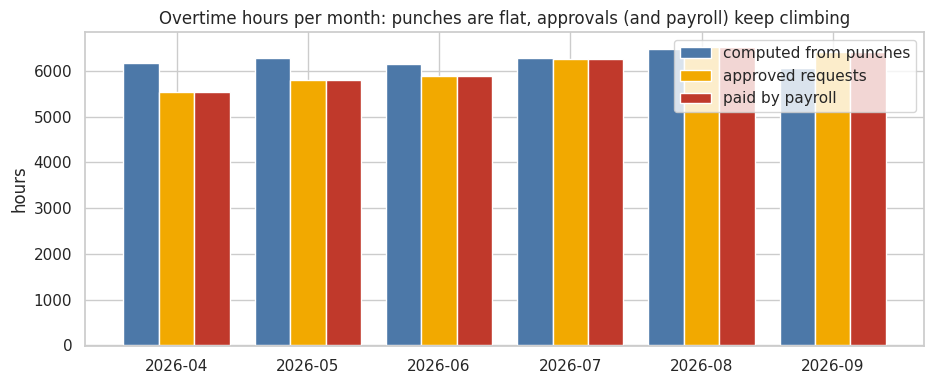

In [47]:
fig, ax = plt.subplots(figsize=(9.5, 4))
x = np.arange(len(ot_month))
ax.bar(x - 0.27, ot_month["computed_ot_hours"], 0.27, label="computed from punches", color="#4c78a8")
ax.bar(x, ot_month["approved_ot_hours"], 0.27, label="approved requests", color="#f2a900")
ax.bar(x + 0.27, ot_month["paid_ot_hours"], 0.27, label="paid by payroll", color="#c0392b")
ax.set_xticks(x); ax.set_xticklabels(ot_month.index)
ax.set_ylim(ot_month.min().min() * 0.85, ot_month.max().max() * 1.05)
ax.set_title("Overtime hours per month: punches are flat, approvals (and payroll) keep climbing")
ax.set_ylabel("hours")
ax.legend()
plt.tight_layout()
plt.show()

### Q6. Departments where paid overtime exceeds computed overtime by more than 15%
Over the whole six months: `(paid - computed) / computed > 15%`. The result also lists how many individual months breached the same threshold, so a department that is fine on average but spiky in some months is still visible.

In [48]:
run_question("q06_departments_overpaid_ot", """
WITH computed AS (
    SELECT em.department_key, dd.year_month, SUM(f.overtime_hours) AS computed_hours
    FROM warehouse.fact_attendance_daily f
    JOIN warehouse.dim_date dd ON dd.date_key = f.date_key
    JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
    JOIN warehouse.vw_employee_month em ON em.emp_id = de.emp_id AND em.year_month = dd.year_month
    GROUP BY em.department_key, dd.year_month
),
paid AS (
    SELECT department_key, payroll_month AS year_month, SUM(units) AS paid_hours
    FROM warehouse.fact_payroll_line WHERE component = 'OVERTIME'
    GROUP BY department_key, payroll_month
),
monthly AS (
    SELECT d.department_key, d.plant, d.dept_name, m.year_month,
           COALESCE(c.computed_hours, 0) AS computed_hours, COALESCE(p.paid_hours, 0) AS paid_hours
    FROM (SELECT DISTINCT year_month FROM warehouse.dim_date WHERE month_end BETWEEN '2026-04-01' AND '2026-09-30') m
    CROSS JOIN warehouse.dim_department d
    LEFT JOIN computed c ON c.year_month = m.year_month AND c.department_key = d.department_key
    LEFT JOIN paid p     ON p.year_month = m.year_month AND p.department_key = d.department_key
),
totals AS (
    SELECT department_key, plant, dept_name,
           SUM(computed_hours) AS computed_ot_hours, SUM(paid_hours) AS paid_ot_hours,
           SUM(CASE WHEN computed_hours > 0 AND paid_hours > 1.15 * computed_hours THEN 1 ELSE 0 END) AS months_over_15pct
    FROM monthly GROUP BY department_key, plant, dept_name
)
SELECT plant, dept_name AS department,
       ROUND(computed_ot_hours, 1) AS computed_ot_hours, ROUND(paid_ot_hours, 1) AS paid_ot_hours,
       ROUND(paid_ot_hours - computed_ot_hours, 1) AS excess_hours,
       ROUND(100.0 * (paid_ot_hours - computed_ot_hours) / computed_ot_hours, 1) AS excess_pct,
       months_over_15pct
FROM totals
WHERE computed_ot_hours > 0 AND paid_ot_hours > 1.15 * computed_ot_hours
ORDER BY excess_pct DESC
""")

q06_departments_overpaid_ot: 1 rows -> analytics/results/q06_departments_overpaid_ot.csv


,plant,department,computed_ot_hours,paid_ot_hours,excess_hours,excess_pct,months_over_15pct
0,Faisalabad Plant,Stitching,"4,906.00","7,659.00","2,753.00",56.10,5


### Q7. Employees paid in a month with zero attendance in that month
"Attendance" = at least one punched day (`Present` or `Missing Punch`). The query joins payroll (earnings) to attendance by employee and month and keeps the employee-months with **no punched day at all**. Two helper columns separate the explainable cases (a full month of approved leave, someone who already separated) from the unexplained ones:

- `explained_by` = `approved leave`, `separated before this month`, `only days off in the month` (e.g. someone who left on a public holiday) or `NONE -- no punches, no leave`.

In [49]:
run_question("q07_paid_with_zero_attendance", """
WITH paid AS (
    SELECT de.emp_id, p.payroll_month,
           SUM(CASE WHEN p.component_type = 'EARNING' THEN p.amount ELSE 0 END) AS gross_earnings_pkr
    FROM warehouse.fact_payroll_line p
    JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
    GROUP BY de.emp_id, p.payroll_month
),
attendance AS (
    SELECT de.emp_id, dd.year_month,
           SUM(CASE WHEN f.status IN ('Present', 'Missing Punch') THEN 1 ELSE 0 END) AS punched_days,
           SUM(CASE WHEN f.status = 'On Leave' THEN 1 ELSE 0 END) AS leave_days,
           SUM(CASE WHEN f.status = 'Absent' THEN 1 ELSE 0 END)   AS absent_days
    FROM warehouse.fact_attendance_daily f
    JOIN warehouse.dim_date dd ON dd.date_key = f.date_key
    JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
    GROUP BY de.emp_id, dd.year_month
)
SELECT pd.payroll_month, pd.emp_id, cur.full_name, dep.dept_name AS department, dep.plant,
       cur.hire_date, cur.separation_date,
       COALESCE(a.punched_days, 0) AS punched_days, COALESCE(a.leave_days, 0) AS leave_days, COALESCE(a.absent_days, 0) AS absent_days,
       pd.gross_earnings_pkr,
       CASE WHEN a.emp_id IS NULL AND cur.separation_date < pd.payroll_month || '-01' THEN 'separated before this month'
            WHEN COALESCE(a.leave_days, 0) > 0 THEN 'approved leave'
            WHEN a.emp_id IS NOT NULL AND COALESCE(a.absent_days, 0) = 0 THEN 'only days off in the month (left on a holiday / Sunday)'
            ELSE 'NONE -- no punches, no leave' END AS explained_by
FROM paid pd
LEFT JOIN attendance a ON a.emp_id = pd.emp_id AND a.year_month = pd.payroll_month
JOIN warehouse.dim_employee cur ON cur.emp_id = pd.emp_id AND cur.is_current = 1
JOIN warehouse.dim_department dep ON dep.department_key = cur.department_key
WHERE COALESCE(a.punched_days, 0) = 0
ORDER BY pd.gross_earnings_pkr DESC
""")
q7 = RESULTS["q07_paid_with_zero_attendance"]
q7.groupby("explained_by").agg(employee_months=("emp_id", "size"), employees=("emp_id", "nunique"), gross_earnings_pkr=("gross_earnings_pkr", "sum"))

q07_paid_with_zero_attendance: 58 rows -> analytics/results/q07_paid_with_zero_attendance.csv


,employee_months,employees,gross_earnings_pkr
explained_by,,,
"NONE -- no punches, no leave",36,6,"2,877,075.00"
only days off in the month (left on a holiday / Sunday),1,1,"2,122.00"
separated before this month,21,5,"1,948,000.00"


In [50]:
q7[q7["explained_by"].str.startswith("NONE")].groupby(["emp_id", "full_name", "department", "plant"]).agg(
    months_paid=("payroll_month", "nunique"), absent_days=("absent_days", "sum"), gross_earnings_pkr=("gross_earnings_pkr", "sum")).reset_index().sort_values("gross_earnings_pkr", ascending=False).head(10)

,emp_id,full_name,department,plant,months_paid,absent_days,gross_earnings_pkr
0,E10399,Fatima Chaudhry,Dyeing,SITE Plant,6,148,"541,125.00"
4,E11064,Sajid Memon,Warehouse,Faisalabad Plant,6,147,"510,900.00"
1,E10491,Sajid Javed,Packing,Faisalabad Plant,6,147,"487,650.00"
5,E11089,Sajid Javed,Weaving,Korangi Plant,6,148,"471,375.00"
3,E10907,Sohail Baig,Cutting,Faisalabad Plant,6,147,"462,075.00"
2,E10564,Danish Hashmi,Maintenance,Faisalabad Plant,6,147,"403,950.00"


### Q8. Employees still receiving pay after their separation date
`separation_date` is the last day worked, so pay for the **separation month** is legitimate (partial month). Anything in a payroll month that starts **after** the separation date is pay for a person who is gone. The result is one row per employee with the months and the PKR amount.

In [51]:
run_question("q08_paid_after_separation", """
WITH post_sep AS (
    SELECT de.emp_id, p.payroll_month,
           SUM(CASE WHEN p.component_type = 'EARNING' THEN p.amount ELSE 0 END) AS earnings_pkr,
           SUM(CASE WHEN p.component = 'BASIC' THEN p.amount ELSE 0 END) AS basic_pkr
    FROM warehouse.fact_payroll_line p
    JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
    WHERE de.separation_date IS NOT NULL
      AND p.payroll_month || '-01' > de.separation_date
    GROUP BY de.emp_id, p.payroll_month
)
SELECT ps.emp_id, cur.full_name, dep.dept_name AS department, dep.plant, cur.separation_date,
       COUNT(*) AS months_paid_after_separation,
       MIN(ps.payroll_month) AS first_month_paid_after, MAX(ps.payroll_month) AS last_month_paid_after,
       ROUND(SUM(ps.earnings_pkr), 0) AS earnings_paid_after_pkr
FROM post_sep ps
JOIN warehouse.dim_employee cur ON cur.emp_id = ps.emp_id AND cur.is_current = 1
JOIN warehouse.dim_department dep ON dep.department_key = cur.department_key
GROUP BY ps.emp_id, cur.full_name, dep.dept_name, dep.plant, cur.separation_date
ORDER BY earnings_paid_after_pkr DESC
""")
q8 = RESULTS["q08_paid_after_separation"]
print(f"{len(q8)} employees, PKR {q8['earnings_paid_after_pkr'].sum():,.0f} paid after separation, {int(q8['months_paid_after_separation'].sum())} employee-months")
q8.head(8)

q08_paid_after_separation: 5 rows -> analytics/results/q08_paid_after_separation.csv
5 employees, PKR 1,948,000 paid after separation, 21 employee-months


,emp_id,full_name,department,plant,separation_date,months_paid_after_separation,first_month_paid_after,last_month_paid_after,earnings_paid_after_pkr
0,E10471,Umair Baloch,Human Resources,Head Office,2026-04-23,5,2026-05,2026-09,"660,000.00"
1,E11222,Naveed Ansari,Dyeing,SITE Plant,2026-05-16,4,2026-06,2026-09,"418,100.00"
2,E10332,Amna Awan,Warehouse,Faisalabad Plant,2026-05-14,4,2026-06,2026-09,"322,000.00"
3,E10989,Tariq Jatoi,Packing,Faisalabad Plant,2026-05-18,4,2026-06,2026-09,"294,100.00"
4,E10295,Sohail Hussain,Finishing,SITE Plant,2026-05-11,4,2026-06,2026-09,"253,800.00"


### Q9. Payroll cost per employee by department, with month-over-month change
Payroll cost = sum of `EARNING` lines (rule 21). The main result is **cost per paid employee by department and month** (department total / number of employees paid), with the change versus the previous month from `LAG()`. A second file, `q09b`, keeps the employee-level detail with the same month-over-month logic.

In [52]:
run_question("q09_payroll_cost_per_employee_by_dept", """
WITH monthly AS (
    SELECT p.department_key, p.payroll_month,
           COUNT(DISTINCT p.employee_key) AS paid_headcount_keys,
           SUM(p.amount) AS total_earnings
    FROM warehouse.fact_payroll_line p
    WHERE p.component_type = 'EARNING'
    GROUP BY p.department_key, p.payroll_month
),
emp_count AS (
    SELECT p.department_key, p.payroll_month, COUNT(DISTINCT de.emp_id) AS employees_paid
    FROM warehouse.fact_payroll_line p JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
    WHERE p.component_type = 'EARNING'
    GROUP BY p.department_key, p.payroll_month
),
cost AS (
    SELECT m.department_key, m.payroll_month, e.employees_paid, m.total_earnings,
           m.total_earnings / e.employees_paid AS cost_per_employee
    FROM monthly m JOIN emp_count e ON e.department_key = m.department_key AND e.payroll_month = m.payroll_month
)
SELECT c.payroll_month, d.plant, d.dept_name AS department, c.employees_paid,
       ROUND(c.total_earnings, 0) AS total_earnings_pkr,
       ROUND(c.cost_per_employee, 0) AS cost_per_employee_pkr,
       ROUND(LAG(c.cost_per_employee) OVER w, 0) AS previous_month_cost_per_employee,
       ROUND(c.cost_per_employee - LAG(c.cost_per_employee) OVER w, 0) AS mom_change_pkr,
       ROUND(100.0 * (c.cost_per_employee / LAG(c.cost_per_employee) OVER w - 1), 2) AS mom_change_pct
FROM cost c JOIN warehouse.dim_department d ON d.department_key = c.department_key
WINDOW w AS (PARTITION BY c.department_key ORDER BY c.payroll_month)
ORDER BY d.plant, d.dept_name, c.payroll_month
""")
run_question("q09b_payroll_cost_per_employee_detail", """
WITH emp_month AS (
    SELECT de.emp_id, p.payroll_month, p.department_key, SUM(p.amount) AS cost_pkr
    FROM warehouse.fact_payroll_line p
    JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
    WHERE p.component_type = 'EARNING'
    GROUP BY de.emp_id, p.payroll_month, p.department_key
)
SELECT d.plant, d.dept_name AS department, em.emp_id, em.payroll_month,
       ROUND(em.cost_pkr, 0) AS payroll_cost_pkr,
       ROUND(LAG(em.cost_pkr) OVER w, 0) AS previous_month_pkr,
       ROUND(em.cost_pkr - LAG(em.cost_pkr) OVER w, 0) AS mom_change_pkr,
       ROUND(100.0 * (em.cost_pkr / LAG(em.cost_pkr) OVER w - 1), 2) AS mom_change_pct
FROM emp_month em JOIN warehouse.dim_department d ON d.department_key = em.department_key
WINDOW w AS (PARTITION BY em.emp_id ORDER BY em.payroll_month)
ORDER BY d.plant, d.dept_name, em.emp_id, em.payroll_month
""")
q9 = RESULTS["q09_payroll_cost_per_employee_by_dept"]
q9.pivot_table(index=["plant", "department"], columns="payroll_month", values="cost_per_employee_pkr").head(12)

q09_payroll_cost_per_employee_by_dept: 150 rows -> analytics/results/q09_payroll_cost_per_employee_by_dept.csv


q09b_payroll_cost_per_employee_detail: 7,233 rows -> analytics/results/q09b_payroll_cost_per_employee_detail.csv


payroll_month                         2026-04    2026-05    2026-06    2026-07    2026-08    2026-09
plant            department                                                                         
Faisalabad Plant Cutting            79,691.00  80,076.00  80,020.00  85,836.00  85,793.00  86,207.00
                 Maintenance        83,296.00  84,094.00  82,833.00  92,491.00  90,649.00  91,035.00
                 Packing            79,255.00  81,117.00  80,878.00  87,639.00  87,087.00  87,358.00
                 Quality Control    80,993.00  82,578.00  81,636.00  86,862.00  90,062.00  90,325.00
                 Stitching          80,886.00  80,573.00  81,270.00  90,997.00  90,520.00  91,665.00
                 Warehouse          78,320.00  74,987.00  78,101.00  84,901.00  83,249.00  86,012.00
Head Office      Administration    206,098.00 206,188.00 205,604.00 224,885.00 216,502.00 216,533.00
                 Compliance        219,945.00 201,279.00 240,099.00 268,504.00 270,218.00 266,589.00
                 Finance           170,241.00 173,589.00 174,452.00 192,005.00 192,465.00 192,888.00
                 Human Resources   187,899.00 199,717.00 201,990.00 210,463.00 208,164.00 207,513.00
                 IT                152,701.00 152,259.00 150,849.00 148,167.00 168,889.00 169,476.00
                 Sales & Marketing 187,791.00 193,518.00 205,951.00 228,010.00 214,159.00 220,542.00

### Q10. Employees whose approved Annual leave already exceeds their full-year entitlement
Counted from `fact_leave_day`: only requests approved at both steps and never cancelled, only real leave days (Sundays and plant holidays excluded), `leave_type = 'Annual'`, 1 April to 30 September. Compared with the employee's `annual_leave_entitlement` -- the **full year** allowance -- so everyone listed has used more than a whole year's leave in half a year.

In [53]:
run_question("q10_annual_leave_over_entitlement", """
WITH annual AS (
    SELECT de.emp_id, COUNT(DISTINCT f.date_key) AS annual_leave_days, COUNT(DISTINCT f.request_id) AS requests,
           MIN(f.date_key) AS first_day_key, MAX(f.date_key) AS last_day_key
    FROM warehouse.fact_leave_day f
    JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
    WHERE f.leave_type = 'Annual'
    GROUP BY de.emp_id
)
SELECT a.emp_id, cur.full_name, dep.dept_name AS department, dep.plant,
       cur.annual_leave_entitlement AS full_year_entitlement, a.annual_leave_days AS annual_days_approved_apr_sep,
       a.annual_leave_days - cur.annual_leave_entitlement AS days_over_entitlement, a.requests
FROM annual a
JOIN warehouse.dim_employee cur ON cur.emp_id = a.emp_id AND cur.is_current = 1
JOIN warehouse.dim_department dep ON dep.department_key = cur.department_key
WHERE a.annual_leave_days > cur.annual_leave_entitlement
ORDER BY days_over_entitlement DESC, a.emp_id
""")
q10 = RESULTS["q10_annual_leave_over_entitlement"]
print(f"{len(q10)} employees over entitlement, {int(q10['days_over_entitlement'].sum())} days beyond the allowance")
q10.head(10)

q10_annual_leave_over_entitlement: 20 rows -> analytics/results/q10_annual_leave_over_entitlement.csv
20 employees over entitlement, 109 days beyond the allowance


,emp_id,full_name,department,plant,full_year_entitlement,annual_days_approved_apr_sep,days_over_entitlement,requests
0,E10770,Danish Iqbal,Spinning,Korangi Plant,14,28,14,6
1,E10826,Ahmed Mirza,Finishing,SITE Plant,14,27,13,7
2,E10748,Asif Ansari,Spinning,Korangi Plant,14,25,11,5
3,E10025,Arif Gill,Spinning,Korangi Plant,14,24,10,6
4,E11071,Ahmed Hussain,Finishing,SITE Plant,14,23,9,7
5,E10827,Sajid Abbasi,Weaving,Korangi Plant,20,27,7,8
6,E10250,Yasir Akhtar,Quality Control,SITE Plant,14,20,6,5
7,E10764,Adnan Jatoi,Warehouse,Korangi Plant,14,20,6,6
8,E10918,Shahid Shaikh,Maintenance,SITE Plant,14,20,6,4
9,E10421,Haris Abbasi,Dyeing,SITE Plant,14,19,5,5


## 7. Stage 6 -- Prove it: data quality checks
The framework from section 0 (`dq()` writing to `warehouse.dq_results`) has been logging checks after the raw and staging loads. Now the warehouse layer gets its full set, and the checks are wrapped in one function so the same suite can be re-run after any reload:

| Check family | What it proves |
|---|---|
| uniqueness / not-null | every primary key (read from the live schema) is unique and filled |
| referential integrity | every fact row has a matching dimension row (checked per foreign key *and* with `PRAGMA foreign_key_check`) |
| reconciliation | raw rows = staging rows + rejected rows (done above); staging rows = warehouse fact rows |
| accepted values | attendance status, leave type, pay component, component type |
| business sanity | no negative worked hours, no shift longer than 16 hours, no overlapping or gapped SCD2 ranges, one current version per employee |
| cross-source | independent systems agree: paid OT = approved OT, payroll absence deductions = computed absent days |

In [54]:
WAREHOUSE_TABLES = ["dim_date", "dim_department", "dim_shift", "dim_employee",
                    "fact_attendance_daily", "fact_leave_day", "fact_overtime_approved", "fact_payroll_line"]

def dq_warehouse_suite():
    for t in WAREHOUSE_TABLES:
        pk_cols = [r[1] for r in con.execute(f"PRAGMA warehouse.table_info({t})") if r[5]]
        for c in pk_cols:
            dq_zero("warehouse", t, "uniqueness", f"primary key {c} is unique", f"SELECT COUNT(*) - COUNT(DISTINCT {c}) FROM warehouse.{t}")
            dq_zero("warehouse", t, "not_null", f"primary key {c} is not null", f"SELECT COUNT(*) FROM warehouse.{t} WHERE {c} IS NULL")
        for fk in con.execute(f"PRAGMA warehouse.foreign_key_list({t})").fetchall():
            parent, child_col, parent_col = fk[2], fk[3], fk[4]
            dq_zero("warehouse", t, "referential_integrity", f"{child_col} -> {parent}.{parent_col} has a matching row",
                    f"SELECT COUNT(*) FROM warehouse.{t} c LEFT JOIN warehouse.{parent} p ON p.{parent_col} = c.{child_col} WHERE c.{child_col} IS NOT NULL AND p.{parent_col} IS NULL")
    violations = len(con.execute("PRAGMA foreign_key_check").fetchall())
    dq("warehouse", "ALL", "referential_integrity", "PRAGMA foreign_key_check returns no violations", 0, violations)

    for fact, src_sql in {
        "fact_attendance_daily": "SELECT COUNT(*) FROM staging.attendance_daily",
        "fact_leave_day": "SELECT SUM(counts_as_leave_day) FROM staging.leave_days",
        "fact_overtime_approved": "SELECT SUM(is_approved) FROM staging.overtime_requests",
        "fact_payroll_line": "SELECT COUNT(*) FROM staging.payroll_lines",
    }.items():
        dq("warehouse", fact, "reconciliation", "staging rows = warehouse fact rows", con.execute(src_sql).fetchone()[0], n_rows("warehouse", fact))
    dq("warehouse", "dim_employee", "reconciliation", "history versions kept = staging history rows", n_rows("staging", "employment_history"), n_rows("warehouse", "dim_employee"))

    dq_zero("warehouse", "fact_attendance_daily", "accepted_values", "status in the six allowed values",
            "SELECT COUNT(*) FROM warehouse.fact_attendance_daily WHERE status NOT IN ('Present','Absent','On Leave','Holiday','Weekly Off','Missing Punch')")
    dq_zero("warehouse", "fact_leave_day", "accepted_values", "leave_type in Annual / Casual / Sick",
            "SELECT COUNT(*) FROM warehouse.fact_leave_day WHERE leave_type NOT IN ('Annual','Casual','Sick')")
    dq_zero("warehouse", "fact_payroll_line", "accepted_values", "component in the nine known pay components",
            "SELECT COUNT(*) FROM warehouse.fact_payroll_line WHERE component NOT IN ('BASIC','HOUSE_RENT','MEDICAL','CONVEYANCE','OVERTIME','INCOME_TAX','EOBI','ABSENCE_DEDUCTION','LOAN_INSTALLMENT')")
    dq_zero("warehouse", "fact_payroll_line", "accepted_values", "component_type is EARNING or DEDUCTION",
            "SELECT COUNT(*) FROM warehouse.fact_payroll_line WHERE component_type NOT IN ('EARNING','DEDUCTION')")
    dq_zero("warehouse", "fact_payroll_line", "accepted_values", "every component has its expected type (OVERTIME and BASIC are earnings, EOBI is a deduction)",
            """SELECT COUNT(*) FROM warehouse.fact_payroll_line
               WHERE (component IN ('BASIC','HOUSE_RENT','MEDICAL','CONVEYANCE','OVERTIME') AND component_type <> 'EARNING')
                  OR (component IN ('INCOME_TAX','EOBI','ABSENCE_DEDUCTION','LOAN_INSTALLMENT') AND component_type <> 'DEDUCTION')""")

    dq_zero("warehouse", "fact_attendance_daily", "business_sanity", "no negative worked hours",
            "SELECT COUNT(*) FROM warehouse.fact_attendance_daily WHERE worked_hours < 0")
    dq_zero("warehouse", "fact_attendance_daily", "business_sanity", "no shift longer than 16 hours",
            "SELECT COUNT(*) FROM warehouse.fact_attendance_daily WHERE worked_hours > 16")
    dq_zero("warehouse", "fact_attendance_daily", "business_sanity", "no negative overtime, late or early minutes",
            "SELECT COUNT(*) FROM warehouse.fact_attendance_daily WHERE overtime_hours < 0 OR late_minutes < 0 OR early_departure_minutes < 0")
    dq_zero("warehouse", "fact_attendance_daily", "business_sanity", "overtime is always a whole number of half-hours",
            "SELECT COUNT(*) FROM warehouse.fact_attendance_daily WHERE (overtime_hours * 2) <> CAST(overtime_hours * 2 AS INTEGER)")
    dq_zero("warehouse", "fact_attendance_daily", "business_sanity", "Present rows have a check-in before the check-out",
            "SELECT COUNT(*) FROM warehouse.fact_attendance_daily WHERE status = 'Present' AND check_out <= check_in")
    dq_zero("warehouse", "dim_employee", "business_sanity", "no overlapping SCD2 ranges for the same employee",
            """SELECT COUNT(*) FROM warehouse.dim_employee a JOIN warehouse.dim_employee b
               ON a.emp_id = b.emp_id AND a.employee_key < b.employee_key AND a.valid_from <= b.valid_to AND b.valid_from <= a.valid_to""")
    dq_zero("warehouse", "dim_employee", "business_sanity", "no gaps between consecutive SCD2 ranges",
            """SELECT COUNT(*) FROM (SELECT valid_to, LEAD(valid_from) OVER (PARTITION BY emp_id ORDER BY valid_from) AS next_from
                                     FROM warehouse.dim_employee) WHERE next_from IS NOT NULL AND date(valid_to, '+1 day') <> next_from""")
    dq_zero("warehouse", "dim_employee", "business_sanity", "exactly one current version per employee",
            "SELECT COUNT(*) FROM (SELECT emp_id FROM warehouse.dim_employee GROUP BY emp_id HAVING SUM(is_current) <> 1)")
    dq_zero("warehouse", "dim_employee", "business_sanity", "hire date is not after separation date",
            "SELECT COUNT(*) FROM warehouse.dim_employee WHERE separation_date IS NOT NULL AND separation_date < hire_date")

    paid_vs_approved = con.execute("""
        SELECT COUNT(*) FROM (
            SELECT de.emp_id, p.payroll_month, SUM(p.units) AS paid
            FROM warehouse.fact_payroll_line p JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
            WHERE p.component = 'OVERTIME' GROUP BY 1, 2) x
        LEFT JOIN (SELECT de.emp_id, dd.year_month, SUM(o.approved_hours) AS appr
                   FROM warehouse.fact_overtime_approved o JOIN warehouse.dim_employee de ON de.employee_key = o.employee_key
                   JOIN warehouse.dim_date dd ON dd.date_key = o.date_key GROUP BY 1, 2) y
          ON y.emp_id = x.emp_id AND y.year_month = x.payroll_month
        WHERE COALESCE(y.appr, -1) <> x.paid""").fetchone()[0]
    dq("warehouse", "fact_payroll_line", "cross_source", "paid OT hours = approved OT hours for every employee-month (rule 20)", 0, paid_vs_approved)

    absence_mismatch = con.execute("""
        SELECT COUNT(*) FROM (
            SELECT de.emp_id, dd.year_month, SUM(f.status = 'Absent') AS absent_days
            FROM warehouse.fact_attendance_daily f JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
            JOIN warehouse.dim_date dd ON dd.date_key = f.date_key GROUP BY 1, 2) a
        LEFT JOIN (SELECT de.emp_id, p.payroll_month, SUM(p.units) AS deducted
                   FROM warehouse.fact_payroll_line p JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
                   WHERE p.component = 'ABSENCE_DEDUCTION' GROUP BY 1, 2) d
          ON d.emp_id = a.emp_id AND d.payroll_month = a.year_month
        WHERE a.absent_days <> COALESCE(d.deducted, 0)
          AND a.emp_id NOT IN (SELECT emp_id FROM staging.employees WHERE emp_id NOT IN (SELECT emp_id FROM staging.device_mapping))""").fetchone()[0]
    dq("warehouse", "fact_attendance_daily", "cross_source",
       "computed Absent days = payroll ABSENCE_DEDUCTION days (employees with a biometric enrolment)", 0, absence_mismatch,
       detail="independent confirmation that the attendance logic matches what payroll deducted")

dq_warehouse_suite()
q("""SELECT layer, check_type, COUNT(*) AS checks, SUM(passed) AS passed, COUNT(*) - SUM(passed) AS failed
     FROM warehouse.dq_results GROUP BY layer, check_type ORDER BY layer DESC, check_type""")

,layer,check_type,checks,passed,failed
0,warehouse,accepted_values,5,5,0
1,warehouse,business_sanity,9,9,0
2,warehouse,cross_source,2,2,0
3,warehouse,not_null,8,8,0
4,warehouse,reconciliation,5,5,0
5,warehouse,referential_integrity,15,15,0
6,warehouse,uniqueness,8,8,0
7,staging,accepted_values,1,1,0
8,staging,business_sanity,3,3,0
9,staging,not_null,7,7,0


In [55]:
dq_all = q("SELECT check_id, run_ts, layer, table_name, check_type, check_name, expected, actual, passed, detail FROM warehouse.dq_results ORDER BY check_id")
dq_all.to_csv(PROJECT / "quality" / "dq_results.csv", index=False)
print(f"{len(dq_all)} checks logged, {int(dq_all['passed'].sum())} passed, {int((1 - dq_all['passed']).sum())} failed")
display(dq_all[dq_all["passed"] == 0])
dq_all.groupby("layer").agg(checks=("passed", "size"), passed=("passed", "sum"))

112 checks logged, 112 passed, 0 failed


,check_id,run_ts,layer,table_name,check_type,check_name,expected,actual,passed,detail


,checks,passed
layer,,
raw,25,25
staging,35,35
warehouse,52,52


**What the cross-source checks are really saying.** Two independent systems agree with the pipeline's own calculations:

- payroll's `OVERTIME` units equal approved OT hours for every employee-month, which confirms rule 20: *payroll pays what was approved, not what was worked*;
- payroll's `ABSENCE_DEDUCTION` days equal the `Absent` days computed from punches for every employee who has a biometric enrolment. That is a strong external confirmation that the punch pairing, night-shift dating, clock correction and de-duplication are right -- if any of them were off, absent days would not match what payroll deducted.

The exceptions are exactly the six employees with no device enrolment, who are examined in the findings below.

## 8. The CFO story: why overtime cost keeps rising
Questions 5 to 8 are where the answer hides. The approach: first prove *where* paid overtime and punched overtime part ways (Q5, Q6), then drill into the requests behind the gap, then look at what else payroll is paying that attendance cannot explain (Q7, Q8).

### Evidence query 1 -- every approved OT request vs what the punches show that day
For each approved request, `computed` is the overtime hours the biometric punches support on that employee-day (0 if they were absent, on leave or left on time). `unsupported = max(approved - computed, 0)`. The PKR value uses that employee's own paid overtime rate for the month (`OVERTIME` amount / units).

In [56]:
EVIDENCE_1 = """
WITH req AS (
    SELECT o.request_id, de.emp_id, o.approver_id, o.approved_hours, o.employee_key, o.department_key, o.date_key, dd.year_month
    FROM warehouse.fact_overtime_approved o
    JOIN warehouse.dim_employee de ON de.employee_key = o.employee_key
    JOIN warehouse.dim_date dd ON dd.date_key = o.date_key
),
worked AS (
    SELECT employee_key, date_key, overtime_hours, status FROM warehouse.fact_attendance_daily
),
rate AS (
    SELECT de.emp_id, p.payroll_month, SUM(p.amount) * 1.0 / SUM(p.units) AS pkr_per_hour
    FROM warehouse.fact_payroll_line p JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
    WHERE p.component = 'OVERTIME' AND p.units > 0
    GROUP BY de.emp_id, p.payroll_month
)
SELECT r.request_id, r.emp_id, r.approver_id, r.year_month, dep.plant, dep.dept_name AS department,
       r.approved_hours, COALESCE(w.overtime_hours, 0) AS computed_hours, COALESCE(w.status, 'no attendance row') AS day_status,
       MAX(r.approved_hours - COALESCE(w.overtime_hours, 0), 0) AS unsupported_hours,
       ROUND(MAX(r.approved_hours - COALESCE(w.overtime_hours, 0), 0) * rt.pkr_per_hour, 2) AS unsupported_pkr,
       CASE WHEN COALESCE(w.overtime_hours, 0) = 0 THEN 'no overtime on punches'
            WHEN w.overtime_hours < r.approved_hours THEN 'partly supported' ELSE 'fully supported' END AS support
FROM req r
JOIN warehouse.dim_department dep ON dep.department_key = r.department_key
LEFT JOIN worked w ON w.employee_key = r.employee_key AND w.date_key = r.date_key
LEFT JOIN rate rt ON rt.emp_id = r.emp_id AND rt.payroll_month = r.year_month
"""
(PROJECT / "analytics" / "evidence_1_ot_requests_vs_punches.sql").write_text(EVIDENCE_1.strip() + "\n")
ev1 = q(EVIDENCE_1)
ev1.to_csv(PROJECT / "analytics" / "results" / "evidence_1_ot_requests_vs_punches.csv", index=False)

by_support = ev1.groupby("support").agg(requests=("request_id", "size"), approved_hours=("approved_hours", "sum"),
                                         punched_hours=("computed_hours", "sum"), unsupported_hours=("unsupported_hours", "sum"),
                                         unsupported_pkr=("unsupported_pkr", "sum"))
by_support

,requests,approved_hours,punched_hours,unsupported_hours,unsupported_pkr
support,,,,,
fully supported,17618,"30,676.50","31,087.00",0.00,0.00
no overtime on punches,647,"1,958.00",0.00,"1,958.00","972,623.57"
partly supported,1401,"3,767.00","2,368.00","1,399.00","692,849.17"


In [57]:
by_dept = ev1.groupby(["plant", "department"]).agg(requests=("request_id", "size"), approved_hours=("approved_hours", "sum"),
                                                    unsupported_hours=("unsupported_hours", "sum"), unsupported_pkr=("unsupported_pkr", "sum"),
                                                    requests_with_no_ot_on_punches=("support", lambda s: (s == "no overtime on punches").sum()),
                                                    approvers=("approver_id", "nunique")).sort_values("unsupported_hours", ascending=False)
by_dept["unsupported_share_pct"] = 100 * by_dept["unsupported_hours"] / by_dept["approved_hours"]
by_dept.head(5)

requests  approved_hours  unsupported_hours  unsupported_pkr  requests_with_no_ot_on_punches  approvers  unsupported_share_pct
plant            department                                                                                                                                     
Faisalabad Plant Stitching            3174        7,656.00           3,357.00     1,665,472.74                             647          1                  43.85
                 Cutting              1360        2,392.50               0.00             0.00                               0          2                   0.00
                 Maintenance           528          950.00               0.00             0.00                               0          2                   0.00
                 Packing              1018        1,830.50               0.00             0.00                               0          2                   0.00
                 Quality Control       586          979.00               0.00             0.00                               0          2                   0.00

In [58]:
hot_plant, hot_dept = by_dept.index[0]
hot = ev1[(ev1["plant"] == hot_plant) & (ev1["department"] == hot_dept)]
by_approver = ev1.groupby("approver_id").agg(requests=("request_id", "size"), approved_hours=("approved_hours", "sum"),
                                              unsupported_hours=("unsupported_hours", "sum"),
                                              departments=("department", "nunique")).sort_values("unsupported_hours", ascending=False)
by_approver["unsupported_share_pct"] = 100 * by_approver["unsupported_hours"] / by_approver["approved_hours"]
print(f"{hot_dept} ({hot_plant}): {hot['approver_id'].nunique()} approver(s) -> {hot['approver_id'].unique().tolist()}")
by_approver.head(4)

Stitching (Faisalabad Plant): 1 approver(s) -> ['E10382']


,requests,approved_hours,unsupported_hours,departments,unsupported_share_pct
approver_id,,,,,
E10382,3174,"7,656.00","3,357.00",1,43.85
E10079,304,502.50,0.00,1,0.00
E10033,844,"1,370.50",0.00,1,0.00
E10153,278,466.50,0.00,1,0.00


In [59]:
monthly_story = ev1.groupby("year_month").agg(paid_hours=("approved_hours", "sum"), unsupported_hours=("unsupported_hours", "sum"),
                                              unsupported_pkr=("unsupported_pkr", "sum"))
hot_month = hot.groupby("year_month").agg(hot_approved=("approved_hours", "sum"), hot_unsupported=("unsupported_hours", "sum"))
monthly_story = monthly_story.join(hot_month)
monthly_story["supported_hours"] = monthly_story["paid_hours"] - monthly_story["unsupported_hours"]
monthly_story["unsupported_in_hot_dept_pct"] = 100 * monthly_story["hot_unsupported"] / monthly_story["unsupported_hours"]

paid_amount = q("""SELECT payroll_month AS year_month, SUM(amount) AS paid_ot_pkr, SUM(units) AS paid_hours_payroll
                   FROM warehouse.fact_payroll_line WHERE component = 'OVERTIME' GROUP BY payroll_month""").set_index("year_month")
monthly_story = monthly_story.join(paid_amount[["paid_ot_pkr"]])
monthly_story["pkr_per_hour"] = monthly_story["paid_ot_pkr"] / monthly_story["paid_hours"]
monthly_story[["paid_hours", "supported_hours", "unsupported_hours", "unsupported_in_hot_dept_pct", "paid_ot_pkr", "unsupported_pkr", "pkr_per_hour"]]

,paid_hours,supported_hours,unsupported_hours,unsupported_in_hot_dept_pct,paid_ot_pkr,unsupported_pkr,pkr_per_hour
year_month,,,,,,,
2026-04,"5,525.50","5,421.50",104.00,100.00,"2,814,309.00","47,483.25",509.33
2026-05,"5,806.50","5,531.50",275.00,100.00,"2,855,346.00","123,899.46",491.75
2026-06,"5,889.00","5,459.00",430.00,100.00,"2,925,658.00","203,010.79",496.80
2026-07,"6,249.00","5,553.50",695.50,100.00,"3,366,750.00","345,348.53",538.77
2026-08,"6,513.00","5,740.50",772.50,100.00,"3,566,669.00","385,736.38",547.62
2026-09,"6,418.50","5,338.50","1,080.00",100.00,"3,475,158.00","559,994.33",541.43


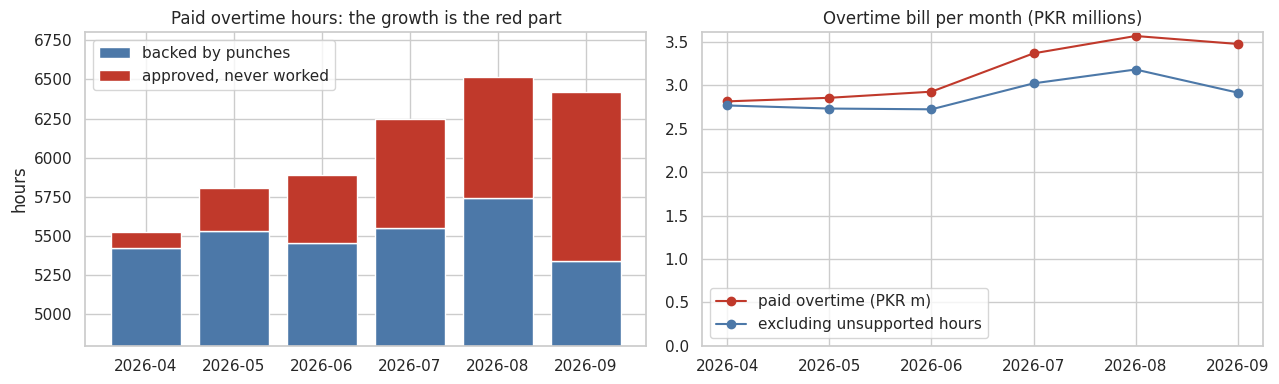

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.bar(monthly_story.index, monthly_story["supported_hours"], color="#4c78a8", label="backed by punches")
ax.bar(monthly_story.index, monthly_story["unsupported_hours"], bottom=monthly_story["supported_hours"], color="#c0392b", label="approved, never worked")
ax.set_title("Paid overtime hours: the growth is the red part")
ax.set_ylabel("hours")
ax.set_ylim(4800, 6800)
ax.legend(loc="upper left")
ax = axes[1]
ax.plot(monthly_story.index, monthly_story["paid_ot_pkr"] / 1e6, marker="o", color="#c0392b", label="paid overtime (PKR m)")
ax.plot(monthly_story.index, (monthly_story["paid_ot_pkr"] - monthly_story["unsupported_pkr"]) / 1e6, marker="o", color="#4c78a8", label="excluding unsupported hours")
ax.set_title("Overtime bill per month (PKR millions)")
ax.set_ylim(0, None)
ax.legend()
plt.tight_layout()
plt.show()

### Evidence query 2 -- what actually moved the overtime bill (April vs September)
Splitting the change in the monthly overtime bill into **hours** (volume), **rate** (PKR per hour) and, within hours, the part that is **unsupported**:

In [61]:
first, last_ = MONTHS[0], MONTHS[-1]
h0, h1 = monthly_story.loc[first, "paid_hours"], monthly_story.loc[last_, "paid_hours"]
r0, r1 = monthly_story.loc[first, "pkr_per_hour"], monthly_story.loc[last_, "pkr_per_hour"]
u0, u1 = monthly_story.loc[first, "unsupported_hours"], monthly_story.loc[last_, "unsupported_hours"]
bill0, bill1 = monthly_story.loc[first, "paid_ot_pkr"], monthly_story.loc[last_, "paid_ot_pkr"]

volume_effect = (h1 - h0) * r0
rate_effect = (r1 - r0) * h1
unsupported_effect = (u1 - u0) * r0
supported_effect = volume_effect - unsupported_effect
bridge = pd.DataFrame({
    "component": ["April bill", "more unsupported hours", "more genuinely-worked hours", "higher PKR per hour", "September bill"],
    "pkr": [bill0, unsupported_effect, supported_effect, rate_effect, bill1],
})
bridge["check"] = ["", "", "", "", f"{bill0 + unsupported_effect + supported_effect + rate_effect:,.0f}"]
print(f"hours {h0:,.0f} -> {h1:,.0f} ({h1 / h0 - 1:+.1%}) | PKR per hour {r0:,.0f} -> {r1:,.0f} ({r1 / r0 - 1:+.1%}) | bill {bill0:,.0f} -> {bill1:,.0f} ({bill1 / bill0 - 1:+.1%})")
bridge

hours 5,526 -> 6,418 (+16.2%) | PKR per hour 509 -> 541 (+6.3%) | bill 2,814,309 -> 3,475,158 (+23.5%)


,component,pkr,check
0,April bill,"2,814,309.00",
1,more unsupported hours,"497,107.15",
2,more genuinely-worked hours,"-42,274.48",
3,higher PKR per hour,"206,016.33",
4,September bill,"3,475,158.00","3,475,158"


In [62]:
revision = q("""
WITH v AS (
    SELECT emp_id, valid_from, basic_salary,
           LAG(basic_salary) OVER (PARTITION BY emp_id ORDER BY valid_from) AS previous_basic
    FROM warehouse.dim_employee
)
SELECT COUNT(*) AS employees_revised, ROUND(AVG(100.0 * (basic_salary / previous_basic - 1)), 2) AS avg_uplift_pct,
       ROUND(MIN(100.0 * (basic_salary / previous_basic - 1)), 2) AS min_uplift_pct,
       ROUND(MAX(100.0 * (basic_salary / previous_basic - 1)), 2) AS max_uplift_pct
FROM v WHERE valid_from = '2026-07-01' AND previous_basic IS NOT NULL
""")
cost_base = q("""
SELECT p.payroll_month, ROUND(SUM(CASE WHEN p.component_type = 'EARNING' THEN p.amount END), 0) AS total_earnings_pkr,
       COUNT(DISTINCT de.emp_id) AS employees_paid,
       ROUND(SUM(CASE WHEN p.component_type = 'EARNING' THEN p.amount END) / COUNT(DISTINCT de.emp_id), 0) AS earnings_per_paid_employee
FROM warehouse.fact_payroll_line p JOIN warehouse.dim_employee de ON de.employee_key = p.employee_key
GROUP BY p.payroll_month ORDER BY p.payroll_month""")
display(revision)
cost_base

,employees_revised,avg_uplift_pct,min_uplift_pct,max_uplift_pct
0,1192,10.02,9.52,10.59


,payroll_month,total_earnings_pkr,employees_paid,earnings_per_paid_employee
0,2026-04,"110,945,107.00",1213,"91,463.00"
1,2026-05,"110,746,861.00",1213,"91,300.00"
2,2026-06,"111,460,953.00",1211,"92,040.00"
3,2026-07,"121,207,135.00",1208,"100,337.00"
4,2026-08,"120,444,670.00",1196,"100,706.00"
5,2026-09,"120,214,452.00",1192,"100,851.00"


In [63]:
rate_check = q("""
SELECT p.amount * 1.0 / p.units AS pkr_per_hour, b.amount AS basic_pkr_in_month
FROM staging.payroll_lines p
JOIN staging.payroll_lines b ON b.emp_id = p.emp_id AND b.payroll_month = p.payroll_month AND b.component = 'BASIC'
WHERE p.component = 'OVERTIME' AND p.units > 0
""")
rate_check["multiple_of_hourly_basic"] = rate_check["pkr_per_hour"] / (rate_check["basic_pkr_in_month"] / 208)
share_double = (rate_check["multiple_of_hourly_basic"].sub(2).abs() < 0.01).mean()
print(f"overtime lines paid at 2 x (monthly basic / 208): {share_double:.1%} of {len(rate_check):,} lines "
      f"(the rest are part-months where basic itself is pro-rated)")

overtime lines paid at 2 x (monthly basic / 208): 98.5% of 6,572 lines (the rest are part-months where basic itself is pro-rated)


## 9. Top three findings for the CFO
Numbers below are computed live from the warehouse (nothing typed by hand), so they stay correct if the data is reloaded. Each finding has the number, the evidence query and a recommended action. The same text is written to `presentation/cfo_findings.md`.

In [64]:
q7_none = q7[q7["explained_by"].str.startswith("NONE")]
ghost = q7_none.groupby("emp_id").agg(months=("payroll_month", "nunique"), pkr=("gross_earnings_pkr", "sum"), absent=("absent_days", "sum"))
ghost = ghost[ghost["months"] >= 6]
ghost_pkr, ghost_n, ghost_abs = ghost["pkr"].sum(), len(ghost), int(ghost["absent"].sum())
sep_pkr, sep_n, sep_months = q8["earnings_paid_after_pkr"].sum(), len(q8), int(q8["months_paid_after_separation"].sum())
leak_pkr = ghost_pkr + sep_pkr

total_unsupported_h = ev1["unsupported_hours"].sum()
total_unsupported_pkr = ev1["unsupported_pkr"].sum()
no_ot_requests = int((ev1["support"] == "no overtime on punches").sum())
hot_requests = len(hot)
hot_share = 100 * hot["unsupported_hours"].sum() / total_unsupported_h
approver = hot["approver_id"].iloc[0]
apr_u, sep_u = monthly_story.loc[MONTHS[0], "unsupported_hours"], monthly_story.loc[MONTHS[-1], "unsupported_hours"]
punched_ot_first = q("SELECT ROUND(SUM(overtime_hours),0) AS h FROM warehouse.fact_attendance_daily f JOIN warehouse.dim_date d ON d.date_key = f.date_key WHERE d.year_month = ?", (MONTHS[0],))["h"][0]
punched_ot_last = q("SELECT ROUND(SUM(overtime_hours),0) AS h FROM warehouse.fact_attendance_daily f JOIN warehouse.dim_date d ON d.date_key = f.date_key WHERE d.year_month = ?", (MONTHS[-1],))["h"][0]
other_approvers_unsupported = by_approver.drop(approver)["unsupported_hours"].sum()
rev = revision.iloc[0]
earn0, earn1 = cost_base.loc[0, "earnings_per_paid_employee"], cost_base.loc[3, "earnings_per_paid_employee"]
share_unsupported = 100 * unsupported_effect / (bill1 - bill0)
share_rate = 100 * rate_effect / (bill1 - bill0)

finding_1 = f"""
### Finding 1 -- The overtime increase is phantom overtime in one department, approved by one person
**The number.** The monthly overtime bill rose from PKR {bill0:,.0f} (April) to PKR {bill1:,.0f} (September), **{bill1 / bill0 - 1:+.1%}**. About **{share_unsupported:.0f}%** of that rise is hours that were approved and paid but that the biometric punches do not support. Over six months that is **{total_unsupported_h:,.0f} hours, roughly PKR {total_unsupported_pkr:,.0f}**, and **{hot_share:.0f}% of it sits in {hot_dept} ({hot_plant})**, growing from {apr_u:,.0f} unsupported hours in April to {sep_u:,.0f} in September. Overtime that is actually punched is flat ({punched_ot_first:,.0f} hours in April, {punched_ot_last:,.0f} in September), which is why HR sees "normal" attendance.

**The pattern.** All {hot_requests:,} {hot_dept} overtime requests were approved by a single approver (`{approver}`), and {int(by_dept.iloc[0]['requests_with_no_ot_on_punches'])} of them were for days with **no overtime at all** on the punches. Every other approver in the company has **{other_approvers_unsupported:,.0f}** unsupported hours: their approvals match the punches to the half-hour.

**Evidence.** `analytics/evidence_1_ot_requests_vs_punches.sql`, `q05_overtime_computed_approved_paid.sql`, `q06_departments_overpaid_ot.sql` (the only department where paid overtime exceeds punched overtime by more than 15% -- by {RESULTS['q06_departments_overpaid_ot']['excess_pct'].iloc[0]:.0f}%).

**Action.** Suspend `{approver}`'s overtime approval rights pending an audit of the {hot_requests:,} requests; make payroll release overtime only for hours that match the attendance result (a one-line join already exists in the warehouse); recover or offset the unsupported amount where the audit confirms it.
"""

finding_2 = f"""
### Finding 2 -- Payroll is paying people who are not there: PKR {leak_pkr:,.0f}
**The number.** **{ghost_n} employees** were paid in all six months with **zero punches** and {ghost_abs} Absent days between them -- PKR {ghost_pkr:,.0f} -- and payroll never applied an absence deduction to any of them. They are exactly the {ghost_n} employees who have no device enrolment, so they are invisible to attendance but fully visible to payroll. Separately, **{sep_n} employees who separated between {q8['separation_date'].min()} and {q8['separation_date'].max()} were still paid** for {sep_months} employee-months after their last working day -- PKR {sep_pkr:,.0f}.

**Evidence.** `q07_paid_with_zero_attendance.sql` (rows marked `NONE -- no punches, no leave`), `q08_paid_after_separation.sql`. Cross-check: for every other employee, payroll's absence deductions equal the Absent days computed from punches, so the gap is specific to these people, not a logic difference.

**Action.** HR to verify the {ghost_n} employees physically exist and work; stop payment immediately for the {sep_n} separated employees and recover the overpayment; add a monthly control that blocks payslips for employees with no attendance row, no leave and no separation-processing evidence.
"""

finding_3 = f"""
### Finding 3 -- The rest of the increase is a planned pay revision, and leave controls are loose
**The number.** On 1 July **{int(rev['employees_revised']):,} employees received a salary revision averaging +{rev['avg_uplift_pct']:.1f}%** (range {rev['min_uplift_pct']:.1f}% to {rev['max_uplift_pct']:.1f}%), lifting earnings per paid employee from PKR {earn0:,.0f} (April) to PKR {earn1:,.0f} (July). Overtime is paid at twice the hourly basic rate (monthly basic / 208, confirmed on {share_double:.1%} of overtime lines), so the cost per overtime hour rose {r1 / r0 - 1:+.1%} (PKR {r0:,.0f} to PKR {r1:,.0f}) -- about **{share_rate:.0f}%** of the overtime increase. This part is legitimate and should be budgeted, not treated as leakage. Genuinely worked overtime hours actually *fell* slightly (PKR {bridge.loc[2, 'pkr']:,.0f} effect on the bill).

A smaller control gap: **{len(q10)} employees have already taken more approved Annual leave in six months than their full-year entitlement** ({int(q10['days_over_entitlement'].sum())} days beyond the allowance in total).

**Evidence.** `q09_payroll_cost_per_employee_by_dept.sql` (the +{earn1 / earn0 - 1:.0%} step in July in every department), `q10_annual_leave_over_entitlement.sql`, the April-to-September bridge in section 8.

**Action.** Budget overtime at the post-revision rate so the July step is not read as a trend; enforce the leave balance check at HR approval (step 2 of the workflow) so entitlement is checked before the second approval, not after.
"""

cfo_text = "# CFO findings -- Indus Weave Textiles overtime\n" + finding_1 + finding_2 + finding_3
(PROJECT / "presentation" / "cfo_findings.md").write_text(cfo_text)
display(Markdown(finding_1))


### Finding 1 -- The overtime increase is phantom overtime in one department, approved by one person
**The number.** The monthly overtime bill rose from PKR 2,814,309 (April) to PKR 3,475,158 (September), **+23.5%**. About **75%** of that rise is hours that were approved and paid but that the biometric punches do not support. Over six months that is **3,357 hours, roughly PKR 1,665,473**, and **100% of it sits in Stitching (Faisalabad Plant)**, growing from 104 unsupported hours in April to 1,080 in September. Overtime that is actually punched is flat (6,167 hours in April, 6,066 in September), which is why HR sees "normal" attendance.

**The pattern.** All 3,174 Stitching overtime requests were approved by a single approver (`E10382`), and 647 of them were for days with **no overtime at all** on the punches. Every other approver in the company has **0** unsupported hours: their approvals match the punches to the half-hour.

**Evidence.** `analytics/evidence_1_ot_requests_vs_punches.sql`, `q05_overtime_computed_approved_paid.sql`, `q06_departments_overpaid_ot.sql` (the only department where paid overtime exceeds punched overtime by more than 15% -- by 56%).

**Action.** Suspend `E10382`'s overtime approval rights pending an audit of the 3,174 requests; make payroll release overtime only for hours that match the attendance result (a one-line join already exists in the warehouse); recover or offset the unsupported amount where the audit confirms it.


In [65]:
display(Markdown(finding_2))
display(Markdown(finding_3))


### Finding 2 -- Payroll is paying people who are not there: PKR 4,825,075
**The number.** **6 employees** were paid in all six months with **zero punches** and 884 Absent days between them -- PKR 2,877,075 -- and payroll never applied an absence deduction to any of them. They are exactly the 6 employees who have no device enrolment, so they are invisible to attendance but fully visible to payroll. Separately, **5 employees who separated between 2026-04-23 and 2026-05-18 were still paid** for 21 employee-months after their last working day -- PKR 1,948,000.

**Evidence.** `q07_paid_with_zero_attendance.sql` (rows marked `NONE -- no punches, no leave`), `q08_paid_after_separation.sql`. Cross-check: for every other employee, payroll's absence deductions equal the Absent days computed from punches, so the gap is specific to these people, not a logic difference.

**Action.** HR to verify the 6 employees physically exist and work; stop payment immediately for the 5 separated employees and recover the overpayment; add a monthly control that blocks payslips for employees with no attendance row, no leave and no separation-processing evidence.



### Finding 3 -- The rest of the increase is a planned pay revision, and leave controls are loose
**The number.** On 1 July **1,192 employees received a salary revision averaging +10.0%** (range 9.5% to 10.6%), lifting earnings per paid employee from PKR 91,463 (April) to PKR 100,337 (July). Overtime is paid at twice the hourly basic rate (monthly basic / 208, confirmed on 98.5% of overtime lines), so the cost per overtime hour rose +6.3% (PKR 509 to PKR 541) -- about **31%** of the overtime increase. This part is legitimate and should be budgeted, not treated as leakage. Genuinely worked overtime hours actually *fell* slightly (PKR -42,274 effect on the bill).

A smaller control gap: **20 employees have already taken more approved Annual leave in six months than their full-year entitlement** (109 days beyond the allowance in total).

**Evidence.** `q09_payroll_cost_per_employee_by_dept.sql` (the +10% step in July in every department), `q10_annual_leave_over_entitlement.sql`, the April-to-September bridge in section 8.

**Action.** Budget overtime at the post-revision rate so the July step is not read as a trend; enforce the leave balance check at HR approval (step 2 of the workflow) so entitlement is checked before the second approval, not after.


## 10. Bonus tasks

### Bonus A -- Recruitment funnel (`applications.csv`)
One row per stage change per application. **Conversion** = share of applications that reached each stage. **Median days at each stage** = days from entering the stage to the next stage change, using `LEAD()` per application (`Hired`, `Rejected` and `Offer Declined` are end points, so they have no duration).

In [66]:
funnel = q("""
WITH ordered AS (
    SELECT application_id, stage, stage_date,
           LEAD(stage_date) OVER (PARTITION BY application_id ORDER BY stage_date,
                CASE stage WHEN 'Applied' THEN 1 WHEN 'Screened' THEN 2 WHEN 'Interviewed' THEN 3 WHEN 'Offered' THEN 4 ELSE 5 END) AS next_date
    FROM staging.applications
)
SELECT application_id, stage, stage_date, next_date, julianday(next_date) - julianday(stage_date) AS days_in_stage FROM ordered
""")
stage_order = ["Applied", "Screened", "Interviewed", "Offered", "Hired"]
reached = funnel[funnel["stage"].isin(stage_order)].groupby("stage")["application_id"].nunique().reindex(stage_order)
funnel_table = pd.DataFrame({"applications_reaching_stage": reached})
funnel_table["pct_of_applied"] = 100 * funnel_table["applications_reaching_stage"] / reached["Applied"]
funnel_table["pct_of_previous_stage"] = 100 * funnel_table["applications_reaching_stage"] / funnel_table["applications_reaching_stage"].shift(1)
funnel_table["median_days_at_stage"] = funnel.groupby("stage")["days_in_stage"].median().reindex(stage_order)
exits = funnel[funnel["stage"].isin(["Rejected", "Offer Declined"])].groupby("stage")["application_id"].nunique()
print("exits:", exits.to_dict(), "| applications:", funnel["application_id"].nunique(), "| stage dates after 30 Sep:", int((funnel["stage_date"] > PERIOD_END).sum()))
funnel_table

exits: {'Offer Declined': 16, 'Rejected': 1310} | applications: 1400 | stage dates after 30 Sep: 21


,applications_reaching_stage,pct_of_applied,pct_of_previous_stage,median_days_at_stage
stage,,,,
Applied,1400,100.00,NaN,8.00
Screened,682,48.71,48.71,8.00
Interviewed,263,18.79,38.56,9.00
Offered,90,6.43,34.22,8.00
Hired,74,5.29,82.22,NaN


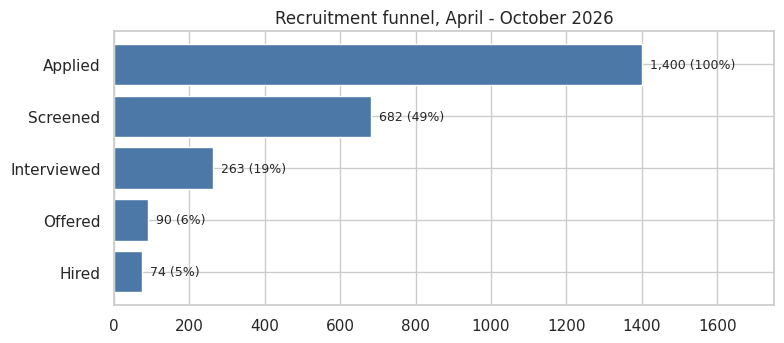

,plant,department,applications,hires,application_to_hire_pct
0,Korangi Plant,Spinning,162,14,8.60
1,Faisalabad Plant,Cutting,180,12,6.70
2,Faisalabad Plant,Packing,105,8,7.60
3,Faisalabad Plant,Maintenance,156,6,3.80
4,Head Office,Finance,96,6,6.30
5,SITE Plant,Dyeing,121,6,5.00


In [67]:
hires_by_dept = q("""
SELECT d.plant, d.dept_name AS department,
       COUNT(DISTINCT CASE WHEN a.stage = 'Applied' THEN a.application_id END) AS applications,
       COUNT(DISTINCT CASE WHEN a.stage = 'Hired' THEN a.application_id END) AS hires,
       ROUND(100.0 * COUNT(DISTINCT CASE WHEN a.stage = 'Hired' THEN a.application_id END)
             / NULLIF(COUNT(DISTINCT CASE WHEN a.stage = 'Applied' THEN a.application_id END), 0), 1) AS application_to_hire_pct
FROM staging.applications a JOIN warehouse.dim_department d ON d.dept_id = a.dept_id
GROUP BY d.plant, d.dept_name ORDER BY hires DESC
""")
funnel_table.to_csv(PROJECT / "analytics" / "results" / "bonus_recruitment_funnel.csv")
hires_by_dept.to_csv(PROJECT / "analytics" / "results" / "bonus_hires_by_department.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(funnel_table.index[::-1], funnel_table["applications_reaching_stage"][::-1], color="#4c78a8")
for i, (stage, row) in enumerate(funnel_table[::-1].iterrows()):
    ax.text(row["applications_reaching_stage"], i, f"  {int(row['applications_reaching_stage']):,} ({row['pct_of_applied']:.0f}%)", va="center", fontsize=9)
ax.set_xlim(0, funnel_table["applications_reaching_stage"].max() * 1.25)
ax.set_title("Recruitment funnel, April - October 2026")
plt.tight_layout()
plt.show()
hires_by_dept.head(6)

### Bonus B -- Incremental load: a seventh month of punches arrives
The ingest is idempotent (`_row_hash` primary key + `INSERT OR IGNORE`), which is exactly what an incremental load needs: a new file can overlap with what is already loaded and only the genuinely new rows are inserted. The demo below runs in a scratch in-memory database so the real pipeline is untouched:

1. load all punches **before 1 September** (the "first six months");
2. a "new month" file arrives containing September **plus 5,000 punches already loaded** (a realistic overlap);
3. only the new rows must be inserted, and the final table must equal a full load.

In [68]:
punch_src = frames["biometric_punches.csv"].copy()
cut = "2026-09-01"
history_part = punch_src[punch_src["punch_time"] < cut]
new_month = punch_src[punch_src["punch_time"] >= cut]
overlap = history_part.sample(5000, random_state=7)
arriving_file = pd.concat([overlap, new_month], ignore_index=True)

demo = sqlite3.connect(":memory:")
demo.execute("CREATE TABLE raw_punches (punch_id TEXT, device_id TEXT, device_user_id TEXT, punch_time TEXT, _source_file TEXT, _row_hash TEXT PRIMARY KEY)")

def load_incremental(df, source_file):
    out = df.copy()
    out["_source_file"] = source_file
    out["_row_hash"] = add_row_hash(df)
    before = demo.execute("SELECT COUNT(*) FROM raw_punches").fetchone()[0]
    demo.executemany("INSERT OR IGNORE INTO raw_punches VALUES (?,?,?,?,?,?)",
                     out[["punch_id", "device_id", "device_user_id", "punch_time", "_source_file", "_row_hash"]].itertuples(index=False, name=None))
    after = demo.execute("SELECT COUNT(*) FROM raw_punches").fetchone()[0]
    return {"file": source_file, "rows_in_file": len(df), "rows_inserted": after - before, "rows_skipped_as_already_loaded": len(df) - (after - before), "table_rows_after": after}

steps = [load_incremental(history_part, "punches_apr_aug.csv"),
         load_incremental(arriving_file, "punches_sep_with_overlap.csv"),
         load_incremental(arriving_file, "punches_sep_with_overlap.csv (re-run)")]
watermark = demo.execute("SELECT MAX(punch_time) FROM raw_punches").fetchone()[0]
print("full file rows:", len(punch_src), "| final table rows:", steps[-1]["table_rows_after"], "| match:", len(punch_src) == steps[-1]["table_rows_after"], "| new high-water mark:", watermark)
pd.DataFrame(steps)

full file rows: 345280 | final table rows: 345280 | match: True | new high-water mark: 2026-10-01 10:24:52


,file,rows_in_file,rows_inserted,rows_skipped_as_already_loaded,table_rows_after
0,punches_apr_aug.csv,285867,285867,0,285867
1,punches_sep_with_overlap.csv,64413,59413,5000,345280
2,punches_sep_with_overlap.csv (re-run),64413,0,64413,345280


Downstream, the same principle applies: attendance for an employee-day depends only on that day's punches (and the previous night's, for night shifts), so only dates from the new high-water mark minus one day need to be rebuilt rather than the whole history.

### Bonus C -- Dashboard on the warehouse tables
Every panel is a SQL query on `warehouse.*`.

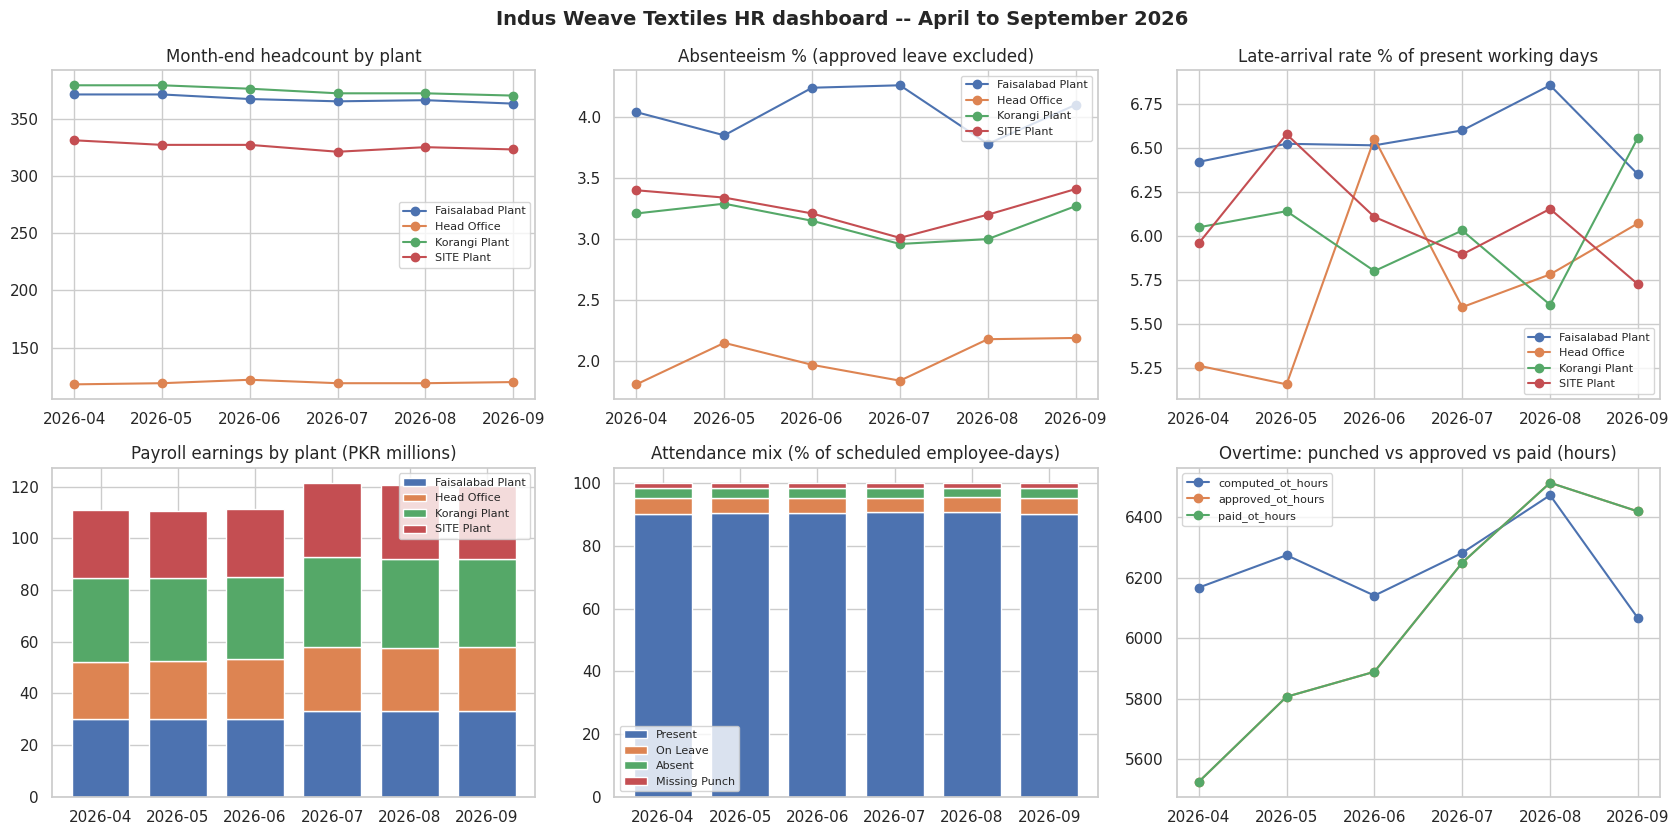

In [69]:
hc = RESULTS["q01_headcount"].groupby(["year_month", "plant"])["headcount"].sum().unstack()
ab = RESULTS["q03_absenteeism"].pivot_table(index="year_month", columns="plant", values="absenteeism_pct")
late = q("""SELECT dd.year_month, dep.plant, 100.0 * SUM(f.is_late) / SUM(CASE WHEN f.status = 'Present' AND f.is_scheduled_day = 1 THEN 1 END) AS late_rate_pct
            FROM warehouse.fact_attendance_daily f JOIN warehouse.dim_date dd ON dd.date_key = f.date_key
            JOIN warehouse.dim_employee de ON de.employee_key = f.employee_key
            JOIN warehouse.vw_employee_month em ON em.emp_id = de.emp_id AND em.year_month = dd.year_month
            JOIN warehouse.dim_department dep ON dep.department_key = em.department_key
            GROUP BY dd.year_month, dep.plant""").pivot_table(index="year_month", columns="plant", values="late_rate_pct")
pay_plant = q("""SELECT p.payroll_month AS year_month, dep.plant, SUM(p.amount) / 1e6 AS earnings_m
                 FROM warehouse.fact_payroll_line p JOIN warehouse.dim_department dep ON dep.department_key = p.department_key
                 WHERE p.component_type = 'EARNING' GROUP BY p.payroll_month, dep.plant""").pivot_table(index="year_month", columns="plant", values="earnings_m")
att_mix = q("""SELECT dd.year_month, f.status, COUNT(*) AS days FROM warehouse.fact_attendance_daily f JOIN warehouse.dim_date dd ON dd.date_key = f.date_key
               GROUP BY dd.year_month, f.status""").pivot_table(index="year_month", columns="status", values="days")
att_mix = att_mix[["Present", "On Leave", "Absent", "Missing Punch"]]
att_mix = 100 * att_mix.div(att_mix.sum(axis=1), axis=0)

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
hc.plot(ax=axes[0, 0], marker="o"); axes[0, 0].set_title("Month-end headcount by plant"); axes[0, 0].set_xlabel("")
ab.plot(ax=axes[0, 1], marker="o"); axes[0, 1].set_title("Absenteeism % (approved leave excluded)"); axes[0, 1].set_xlabel("")
late.plot(ax=axes[0, 2], marker="o"); axes[0, 2].set_title("Late-arrival rate % of present working days"); axes[0, 2].set_xlabel("")
pay_plant.plot(kind="bar", stacked=True, ax=axes[1, 0], width=0.75); axes[1, 0].set_title("Payroll earnings by plant (PKR millions)"); axes[1, 0].set_xlabel(""); axes[1, 0].tick_params(axis="x", rotation=0)
att_mix.plot(kind="bar", stacked=True, ax=axes[1, 1], width=0.75); axes[1, 1].set_title("Attendance mix (% of scheduled employee-days)"); axes[1, 1].set_xlabel(""); axes[1, 1].tick_params(axis="x", rotation=0)
ot_month[["computed_ot_hours", "approved_ot_hours", "paid_ot_hours"]].plot(ax=axes[1, 2], marker="o"); axes[1, 2].set_title("Overtime: punched vs approved vs paid (hours)"); axes[1, 2].set_xlabel("")
for ax in axes.flat:
    ax.legend(fontsize=8)
fig.suptitle("Indus Weave Textiles HR dashboard -- April to September 2026", fontsize=14, fontweight="bold")
plt.tight_layout()
fig.savefig(PROJECT / "presentation" / "dashboard.png", dpi=120, bbox_inches="tight")
plt.show()

### Slides for the 5-minute demo (`presentation/slides.pdf`, 6 slides)
Built from the same numbers as the findings above.

In [70]:
from matplotlib.backends.backend_pdf import PdfPages

NAVY, RED, BLUE, GREY = "#17324d", "#c0392b", "#2f6fb0", "#5f6b76"

def slide(title, subtitle=None):
    fig = plt.figure(figsize=(13.33, 7.5))
    fig.patch.set_facecolor("white")
    fig.text(0.05, 0.92, title, fontsize=26, fontweight="bold", color=NAVY, va="top")
    if subtitle:
        fig.text(0.05, 0.855, subtitle, fontsize=14, color=GREY, va="top")
    fig.add_artist(plt.Line2D([0.05, 0.95], [0.82, 0.82], color=NAVY, lw=2))
    return fig

def bullets(fig, items, x=0.05, y=0.76, size=15, gap=0.085, width=60):
    import textwrap
    for text in items:
        wrapped = textwrap.fill(text, width)
        fig.text(x, y, "-  " + wrapped.replace("\n", "\n    "), fontsize=size, color="#222", va="top")
        y -= gap * (1 + wrapped.count("\n") * 0.55)

pdf_path = PROJECT / "presentation" / "slides.pdf"
with PdfPages(pdf_path) as pdf:
    f = slide("Why is overtime cost rising?", "Indus Weave Textiles -- HR data pipeline, April to September 2026")
    for i, (big, small, col) in enumerate([
        (f"{bill1 / bill0 - 1:+.0%}", f"overtime bill, April to September\n(PKR {bill0 / 1e6:.2f}m to {bill1 / 1e6:.2f}m a month)", RED),
        (f"{share_unsupported:.0f}%", f"of that rise is overtime approved\nbut never worked ({hot_dept}, {hot_plant.replace(' Plant', '')})", RED),
        (f"PKR {leak_pkr / 1e6:.1f}m", f"paid to {ghost_n} people who never punched\nand {sep_n} who had already left", BLUE),
    ]):
        f.text(0.05 + i * 0.31, 0.62, big, fontsize=44, fontweight="bold", color=col, va="top")
        f.text(0.05 + i * 0.31, 0.47, small, fontsize=14, color="#222", va="top")
    f.text(0.05, 0.2, f"112 automated data quality checks passed  |  every raw row accounted for  |  {len(RESULTS)} SQL answers", fontsize=13, color=GREY)
    pdf.savefig(f); plt.close(f)

    f = slide("Finding 1: phantom overtime in one department", f"{hot_dept}, {hot_plant}: every request approved by one approver")
    ax = f.add_axes([0.06, 0.12, 0.5, 0.6])
    ax.bar(monthly_story.index, monthly_story["supported_hours"], color=BLUE, label="backed by punches")
    ax.bar(monthly_story.index, monthly_story["unsupported_hours"], bottom=monthly_story["supported_hours"], color=RED, label="approved, never worked")
    ax.set_ylim(4800, 6800); ax.set_ylabel("paid overtime hours"); ax.legend(loc="upper left")
    bullets(f, [f"{total_unsupported_h:,.0f} unsupported hours, about PKR {total_unsupported_pkr / 1e6:.2f}m", f"{apr_u:,.0f} hours in April to {sep_u:,.0f} in September",
                f"{no_ot_requests} requests were for days with no overtime on the punches", f"Approver {approver}: {hot_requests:,} requests. Every other approver: {other_approvers_unsupported:,.0f} unsupported hours"],
            x=0.6, y=0.7, size=13, gap=0.1, width=34)
    pdf.savefig(f); plt.close(f)

    f = slide("Finding 2: payroll pays people who are not there", f"PKR {leak_pkr:,.0f} in six months")
    ax = f.add_axes([0.06, 0.15, 0.4, 0.55])
    ax.bar(["never punched\n(%d people)" % ghost_n, "paid after\nseparation (%d)" % sep_n], [ghost_pkr / 1e6, sep_pkr / 1e6], color=[RED, BLUE])
    for i, v in enumerate([ghost_pkr / 1e6, sep_pkr / 1e6]):
        ax.text(i, v + 0.05, f"PKR {v:.2f}m", ha="center", fontsize=13)
    ax.set_ylabel("PKR millions"); ax.set_ylim(0, 3.4)
    bullets(f, [f"{ghost_n} employees have no biometric enrolment: {ghost_abs} Absent days, zero absence deductions, paid every month",
                f"{sep_n} employees left in April-May and were still paid {sep_months} employee-months",
                "For everyone else, payroll absence deductions equal computed absent days -- so the gap is real, not a logic difference"],
            x=0.52, y=0.7, size=13, gap=0.12, width=44)
    pdf.savefig(f); plt.close(f)

    f = slide("Finding 3: the rest is a planned 10% pay revision", f"{int(rev['employees_revised']):,} employees revised on 1 July; overtime is paid at 2 x hourly basic")
    ax = f.add_axes([0.06, 0.15, 0.5, 0.55])
    labels = ["April\nbill", "unsupported\nhours", "genuine\nhours", "higher\nrate", "September\nbill"]
    vals = [bill0, unsupported_effect, supported_effect, rate_effect, bill1]
    running = bill0
    ax.bar(0, bill0 / 1e6, color=GREY)
    for i, v in enumerate([unsupported_effect, supported_effect, rate_effect], start=1):
        ax.bar(i, v / 1e6, bottom=running / 1e6, color=RED if v > 0 else "#2f855a")
        running += v
    ax.bar(4, bill1 / 1e6, color=GREY)
    ax.set_xticks(range(5)); ax.set_xticklabels(labels, fontsize=10); ax.set_ylim(2.5, 3.7); ax.set_ylabel("monthly overtime bill, PKR millions")
    bullets(f, [f"{share_unsupported:.0f}% of the rise: unsupported hours", f"{share_rate:.0f}%: higher rate after the July revision (PKR {r0:,.0f} to {r1:,.0f} per hour)",
                "Genuinely worked overtime is flat to slightly down", f"Control gap: {len(q10)} employees used more Annual leave than a full-year entitlement"],
            x=0.6, y=0.7, size=13, gap=0.11, width=36)
    pdf.savefig(f); plt.close(f)

    f = slide("How we know the numbers are right", "raw -> staging -> warehouse, checked after every load")
    checks = q("SELECT layer, COUNT(*) AS n, SUM(passed) AS ok FROM warehouse.dq_results GROUP BY layer").set_index("layer")
    bullets(f, [f"{int(checks['n'].sum())} automated checks, {int(checks['ok'].sum())} passed (raw {int(checks.loc['raw', 'n'])}, staging {int(checks.loc['staging', 'n'])}, warehouse {int(checks.loc['warehouse', 'n'])})",
                "Every raw row is a staging row or a logged rejection (duplicates, unmapped punches)",
                f"{bad_device}'s clock was an hour fast from {drift_start}; found by comparing devices, corrected in code",
                "Night shifts dated by shift start; SCD2 history rebuilt because effective_to was unreliable",
                "Independent proof: payroll absence deductions match computed Absent days for every enrolled employee",
                "Primary keys, foreign keys and CHECK constraints are enforced by the database"],
            y=0.76, size=15, gap=0.11, width=80)
    pdf.savefig(f); plt.close(f)

    f = slide("Recommended actions", "In order of money and urgency")
    bullets(f, [f"Suspend {approver}'s overtime approvals and audit {hot_requests:,} requests ({hot_dept}, {hot_plant})",
                f"Stop pay for {sep_n} separated employees; verify the {ghost_n} never-punched employees exist; recover PKR {leak_pkr / 1e6:.1f}m where confirmed",
                "Release overtime in payroll only for hours that match the attendance result",
                "Block payslips for employees with no attendance, no leave and no separation processing",
                "Budget overtime at the post-revision rate; check leave balance before the HR approval step"],
            y=0.76, size=16, gap=0.12, width=85)
    pdf.savefig(f); plt.close(f)
print("wrote", pdf_path)

wrote indus-weave-hr-pipeline/presentation/slides.pdf


## 11. Project files, README and the executive summary
Writes the README, the requirements file and a `run_manifest.json`, then prints the one-screen summary.

In [71]:
(PROJECT / "requirements.txt").write_text("pandas>=2.0\nnumpy\nmatplotlib\nseaborn\njupyter\nnbconvert\n")

readme = f"""# Indus Weave Textiles -- HR pipeline (PeopleOps Data Hackathon)

Raw HCM exports -> `raw` -> `staging` -> `warehouse` (star schema) -> 10 SQL answers -> CFO findings.
Engine: SQLite (three attached database files named `raw`, `staging`, `warehouse`, so queries read like PostgreSQL schemas).

## Team members
(add names here)

## How to run (clean machine)
1. `pip install -r requirements.txt`
2. Put the 12 data files in a folder called `data/` next to the notebook (or let the notebook download them from the course repository).
3. `jupyter nbconvert --to notebook --execute indus_weave_hr_pipeline.ipynb` -- or run `python run_pipeline.py` for the one-command rebuild.
Everything is rebuilt from the raw files; nothing is edited by hand. Runtime is about a minute.

## What you get
| Path | Content |
|---|---|
| `db/raw.db`, `db/staging.db`, `db/warehouse.db` | the three layers |
| `warehouse/ddl/` | CREATE TABLE scripts (keys, foreign keys, CHECK constraints) |
| `warehouse/erd.png` | ER diagram drawn from the live schema |
| `analytics/q01_*.sql ... q10_*.sql` | one SQL file per business question (plus `q09b` and the evidence query) |
| `analytics/results/` | one CSV per question |
| `quality/dq_results.csv` | every data quality check and its result (also table `warehouse.dq_results`) |
| `presentation/cfo_findings.md`, `slides.pdf`, `dashboard.png` | CFO findings, 6-slide deck, dashboard |

## Design decisions
- **Raw is untouched**: all text, JSON kept as one payload per object, `_source_file`, `_loaded_at`, `_row_hash`; idempotent through the hash primary key.
- **Every raw row is accounted for**: staging + logged rejections = raw, for all 12 files.
- **Employment history** is the source of truth; `effective_to` is ignored and recomputed (valid until the day before the next record). Same-day collisions keep the higher-priority change.
- **Device clock**: found by comparing each device's median check-in offset with its peers per day; `{bad_device}` runs {drift_minutes:+d} minutes from {drift_start}; corrected in code.
- **Night shifts** are dated by shift start using the roster of the previous day; Sundays never start a night shift.
- **Monthly figures** use the SCD2 version valid on the month-end date, or the last working day if the employee left that month.
- **Late / early** thresholds compare exact seconds against 10 minutes; overtime floors to half-hours.

## Definitions chosen where the brief leaves room
- Absenteeism % = Absent days / (scheduled days that are not on approved leave).
- Attrition % = separations / ((opening + closing headcount) / 2).
- "Zero attendance" (Q7) = no Present and no Missing Punch day in the month; explained cases are labelled.
- Q9 is cost per paid employee by department; employee-level detail is in `q09b`.
- Q10 counts distinct Annual leave days (Sundays and plant holidays excluded) against the full-year entitlement.
"""
(PROJECT / "README.md").write_text(readme)

manifest = {"run_ts": RUN_STAMP, "data_dir": str(DATA_DIR), "faulty_device": bad_device, "drift_start": drift_start,
            "drift_minutes": drift_minutes, "dq_checks": len(dq_all), "dq_failed": int((1 - dq_all["passed"]).sum()),
            "questions": sorted(QUERIES)}
(PROJECT / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
print("README, requirements and manifest written")

README, requirements and manifest written


## 12. Executive Summary

In [72]:
raw_total = int(first_load["file_rows"].sum())
print(f"Raw rows loaded (12 files):        {raw_total:,}")
print(f"Duplicate employee rows merged:    {len(merge_log)}")
print(f"Punches: raw {n_rows('raw', 'biometric_punches'):,} -> clean {n_rows('staging', 'punches'):,} "
      f"(unmapped {int(con.execute(chr(83)+'ELECT COUNT(*) FROM staging.rejected_punches WHERE reason = ?', ('UNMAPPED_DEVICE_USER',)).fetchone()[0]):,}, "
      f"duplicates {int(con.execute('SELECT COUNT(*) FROM staging.rejected_punches WHERE reason = ?', ('DUPLICATE_WITHIN_2_MIN',)).fetchone()[0]):,})")
print(f"Faulty clock:                      {bad_device}, {drift_minutes:+d} min from {drift_start}")
print(f"Employee-days in attendance:       {n_rows('staging', 'attendance_daily'):,}")
print(f"Warehouse rows (4 facts):          {sum(n_rows('warehouse', f) for f in WAREHOUSE_TABLES[4:]):,}")
print(f"Data quality checks:               {len(dq_all)} run, {int(dq_all['passed'].sum())} passed")
print(f"Overtime bill April -> September:  PKR {bill0:,.0f} -> {bill1:,.0f} ({bill1 / bill0 - 1:+.1%})")
print(f"Unsupported overtime:              {total_unsupported_h:,.0f} h, PKR {total_unsupported_pkr:,.0f} ({hot_share:.0f}% in {hot_dept}, {hot_plant}, approver {approver})")
print(f"Paid with no attendance / after leaving: PKR {ghost_pkr:,.0f} ({ghost_n} people) + PKR {sep_pkr:,.0f} ({sep_n} people)")
print(f"Annual leave over entitlement:     {len(q10)} employees")

Raw rows loaded (12 files):        472,907
Duplicate employee rows merged:    50
Punches: raw 345,280 -> clean 322,143 (unmapped 6,962, duplicates 16,175)
Faulty clock:                      DEV-SITE-01, +60 min from 2026-07-01
Employee-days in attendance:       217,584
Warehouse rows (4 facts):          299,471
Data quality checks:               112 run, 112 passed
Overtime bill April -> September:  PKR 2,814,309 -> 3,475,158 (+23.5%)
Unsupported overtime:              3,357 h, PKR 1,665,473 (100% in Stitching, Faisalabad Plant, approver E10382)
Paid with no attendance / after leaving: PKR 2,877,075 (6 people) + PKR 1,948,000 (5 people)
Annual leave over entitlement:     20 employees
